# Homework 2: Multiple Object Video Detection

Sections 1–5 follow the grading rubric: the dataset, then the four detector families (Faster R-CNN, RetinaNet, FCOS, RT-DETR). Section 6 holds the pipeline experiments (box loss, cross-validation, training, inference, fusion) in the order they were run, including the ones that scored lower. **Results at a glance**, right below, sorts every experiment by its outcome, and each experiment starts with its outcome.

**Everything is in this notebook.** Run it from top to bottom, with the folder that holds `data/` as the working directory. The dataset goes under `data/`, with `train/`, `val/`, `test/`, `test_images.csv` and `sample_submission.csv` directly inside it. Each experiment saves its results under `outputs/<section>_<name>/` (for example `outputs/6.6_crop_training/`) and reuses them when the notebook runs again: a run with saved results takes about ten minutes, while a first run trains every model on a CUDA GPU (about 25 hours on an RTX 3070 Ti Laptop). The selected Kaggle file is written in section 6.11 to `outputs/submissions/submission_tta_rtdetr_group.csv` (public leaderboard 0.3073).

**Environment:** Python 3.12; torch 2.7.1 and torchvision 0.22.1 (CUDA 11.8 wheels); transformers 4.57.1, numpy 2.2.4, pandas 2.2.3, matplotlib 3.10.1, pycocotools 2.0.11, PyYAML 6.0.3, Pillow 11.2.1. The detectors start from pretrained TorchVision and RT-DETR (`PekingU/rtdetr_r50vd`) weights, downloaded on first use.

## Results at a glance

Scores are mAP on the full official validation set (COCO mAP over IoU 0.50–0.95, up to 500 detections per image) unless marked **LB** (public leaderboard). Each change is compared with the run it modifies. A gain counts as clear from +0.005 mAP, the bar the notebook fixes in advance in sections 6.5 and 6.6.

**Leaderboard path:** FCOS alone 0.2046 → FCOS at long side 1600 0.1876 → Faster R-CNN crop pass 1 0.2258 (the first file above the public baseline of 0.2216) → four-detector fusion 0.2570 → selected two-group ensemble **0.3073**.

### Worked well
Gains of +0.005 or more. The selected file is built on these.

| Experiment | Section | Before → after | In the selected file |
|---|---|---|---|
| FCOS centre sampling radius 1.0 | 4 | 0.1888 → 0.1985 (+0.010) | yes, the FCOS member |
| RT-DETR with 500 queries | 5 | 0.1429 → 0.1488 (+0.006) | yes, three of the four RT-DETR members |
| Fusing the Faster R-CNN and FCOS files | 6.9 | 0.1993 and 0.1990 alone → 0.2240 (+0.025) | yes |
| Adding RetinaNet and RT-DETR to the fusion | 6.9 | 0.2240 → 0.2322; LB 0.2570 | yes |
| Score threshold 0.001, mirrored view, a group of four RT-DETR checkpoints | 6.10 | 0.2322 → 0.2516; LB 0.2570 → 0.3073 | yes, this is the selected file |

### Small gain
Positive, but under +0.005.

| Experiment | Section | Before → after | Kept |
|---|---|---|---|
| Faster R-CNN anchors 16–256 | 2 | 0.1941 → 0.1969 (+0.003); AP_small 0.092 → 0.102 | yes, the start of every later Faster R-CNN |
| Faster R-CNN learning rate 0.005 | 2 | 0.1941 → 0.1966 (+0.0025) | no, the anchor run was carried forward |
| RetinaNet focal alpha 0.5 | 3 | 0.1801 → 0.1811 (+0.001) | yes, the RetinaNet member |
| FCOS DIoU box loss | 6.1 | 0.1985 → 0.1990 (+0.0005, a tie) | yes, the FCOS member |
| Faster R-CNN crop training, pass 1 | 6.6 | 0.1969 → 0.1983 (+0.0014); LB 0.2258 | yes |
| Faster R-CNN test-time RPN budget 3000 | 6.8 | 0.1983 → 0.1993 (+0.001 on every check) | yes |

### Did not work
Lower scores, or a gain below a bar fixed before the result.

| Experiment | Section | Before → after |
|---|---|---|
| Long side 1024 for Faster R-CNN and FCOS | 2, 4 | 0.1941 → 0.1791; 0.1888 → 0.1586 |
| RetinaNet anchors 16–256 | 3 | 0.1801 → 0.1628 |
| RT-DETR at its native long side 640 | 5 | 0.1429 → 0.0807 |
| FCOS inference at long side 1600 | 6.5 | +0.0012, below the +0.005 bar; LB 0.2046 → 0.1876 |
| FCOS fine-tune, two more epochs | 6.5 | 0.1990 → 0.1972 and 0.1956 |
| Tiled inference with 640-pixel tiles | 6.6 | 0.1983 → 0.1853 |
| Crop training pass 2 (so pass 3 was not run) | 6.7 | 0.1983 → 0.1953 |
| Fusion settings: looser pairing, duplicate removal, more Faster R-CNN weight | 6.9 | screening set 0.2228 → 0.2228, 0.2228 and 0.2207 |
| RT-DETR retrain, epoch 2, as the fourth detector | 6.9 | 0.2322 → 0.2319 (it helps later, inside the RT-DETR group of 6.10) |
| Overnight Faster R-CNN with class-aware crops | 6.9 | 0.2310 → 0.2283 at best |

### Checks and diagnostics
These change no score. They test the code or explain a result.
- **Code checks:** the metric with ignore regions and 500 detections, the training flip, the focal loss head, the RT-DETR adapter, the DIoU box loss head and the submission format, each against a hand-checkable case.
- **Inference speed recheck (6.3):** the 5.2 fps logged for the 5-epoch Faster R-CNN baseline came from a GPU slowdown; measured again it runs at 15.0 fps.
- **Video-grouped five-fold cross-validation (6.4):** out-of-fold mAP 0.193 ± 0.031 across folds, 0.186 pooled. The fold models score 0.190 on the official validation set, against 0.199 for the final model trained on all videos.
- **Proposal diagnostics (6.8):** 21% of small objects get no proposal at IoU 0.5, the first step that loses them. This led to the RPN budget test.

In [1]:
import csv
import json
import platform
import re
import time
from collections import Counter, defaultdict, deque
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass, field
from io import BytesIO
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import yaml
from IPython.display import Image as DisplayImage, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from PIL import Image

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

## 1. Dataset and preprocessing

## Conventions
- **Class label:** competition class ID, 0-7 (COCO `category_id` minus 1).
- **Box format:** pixel `[x, y, width, height]` of the original image, top-left origin, unless a function name says otherwise.
- **Ignore regions** are class-agnostic. The COCO files repeat each one 8 times (once per category, so that COCO evaluation ignores all classes); `load_split` collapses the copies into one region per frame.

### Constants and the frame record

In [2]:
PROJECT_ROOT = Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data"
assert DATA_ROOT.exists(), f"Dataset not found at {DATA_ROOT}; run from the homework folder"
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
OUTPUT_DIRS = {
    1: "1_dataset", 2: "2_faster_rcnn", 3: "3_retinanet", 4: "4_fcos", 5: "5_rtdetr", 6: "6.1_fcos_box_loss",
    7: "6.2_first_export", 9: "6.5_fcos_resolution", 10: "6.6_crop_training", 11: "6.7_crop_followup", 12: "6.8_rpn_budget",
}
DATASET_DIR = OUTPUT_ROOT / OUTPUT_DIRS[1]

CLASS_NAMES = ("person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor")
NUM_CLASSES = len(CLASS_NAMES)

IGNORE_FILL_RGB = (124, 116, 104)
IGNORE_DROP_OVERLAP = 0.5

@dataclass(frozen=True)
class Frame:
    """One annotated video frame."""

    image_id: int
    path: Path
    clip: str
    frame_index: int
    width: int
    height: int
    boxes: np.ndarray
    labels: np.ndarray
    track_ids: np.ndarray
    occlusion: np.ndarray
    ignore: np.ndarray

### Conversions

In [3]:
def coco_category_to_label(category_id):
    """COCO category IDs are 1-8; competition class IDs are 0-7."""
    return category_id - 1


def yolo_to_xywh(rows, width, height):
    """Normalized (cx, cy, w, h) rows to pixel (x, y, w, h) rows."""
    rows = np.asarray(rows, dtype=float).reshape(-1, 4)
    scale = np.array([width, height, width, height], dtype=float)
    pixels = rows * scale
    pixels[:, :2] -= pixels[:, 2:] / 2
    return pixels


def xywh_to_xyxy(boxes):
    """Pixel (x, y, w, h) rows to pixel (x1, y1, x2, y2) rows."""
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    return np.concatenate([boxes[:, :2], boxes[:, :2] + boxes[:, 2:]], axis=1)

### File readers

In [4]:
def read_yolo_label_file(path):
    """Return (labels, normalized cxcywh rows) from a YOLO label file."""
    rows = np.array(Path(path).read_text().split(), dtype=float).reshape(-1, 5)
    return rows[:, 0].astype(int), rows[:, 1:]

def read_ignore_file(path):
    """Return normalized cxcywh rows from a per-frame ignore file (no class column)."""
    return np.array(Path(path).read_text().split(), dtype=float).reshape(-1, 4)

def load_coco(split, data_root=DATA_ROOT):
    with open(Path(data_root) / split / "annotations_coco.json", encoding="utf-8") as file:
        return json.load(file)

def load_split(split, data_root=DATA_ROOT):
    """Load 'train' or 'val' into a list of Frame, ordered by clip and frame."""
    coco = load_coco(split, data_root)
    categories = sorted(coco["categories"], key=lambda c: c["id"])
    if tuple(c["name"] for c in categories) != CLASS_NAMES or categories[0]["id"] != 1:
        raise ValueError(f"Unexpected categories in {split}: {categories}")

    objects = defaultdict(list)
    regions = defaultdict(dict)
    for ann in coco["annotations"]:
        if ann["iscrowd"]:
            regions[ann["image_id"]][tuple(ann["bbox"])] = None
        else:
            objects[ann["image_id"]].append(ann)

    frames = []
    for image in coco["images"]:
        anns = objects.get(image["id"], [])
        frames.append(
            Frame(
                image_id=image["id"],
                path=Path(data_root) / split / image["file_name"],
                clip=image["video"],
                frame_index=image["frame_id"],
                width=image["width"],
                height=image["height"],
                boxes=np.array([a["bbox"] for a in anns], dtype=float).reshape(-1, 4),
                labels=np.array(
                    [coco_category_to_label(a["category_id"]) for a in anns], dtype=int
                ),
                track_ids=np.array([a["track_id"] for a in anns], dtype=int),
                occlusion=np.array([a["occlusion"] for a in anns], dtype=int),
                ignore=np.array(list(regions.get(image["id"], {})), dtype=float).reshape(-1, 4),
            )
        )
    frames.sort(key=lambda f: (f.clip, f.frame_index))
    return frames

def load_test_index(data_root=DATA_ROOT):
    """Read test_images.csv. Test frames have no annotations of any kind."""
    with open(Path(data_root) / "test_images.csv", encoding="utf-8", newline="") as file:
        rows = list(csv.DictReader(file))
    return [
        {
            "image_id": row["image_id"],
            "path": Path(data_root) / row["file_name"],
            "clip": row["clip"],
            "frame_index": int(row["frame"]),
            "width": int(row["width"]),
            "height": int(row["height"]),
        }
        for row in rows
    ]

### Ignored regions

In [5]:
def ignored_overlap(boxes, regions):
    """For each box, the largest share of its area inside any single ignore region.

    This is intersection over the box's own area, not IoU: a tiny object fully
    inside a large region scores 1.0, which is what matters for masking.
    """
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    regions = np.asarray(regions, dtype=float).reshape(-1, 4)
    if len(boxes) == 0 or len(regions) == 0:
        return np.zeros(len(boxes))
    a, b = xywh_to_xyxy(boxes)[:, None, :], xywh_to_xyxy(regions)[None, :, :]
    inter_w = (np.minimum(a[..., 2], b[..., 2]) - np.maximum(a[..., 0], b[..., 0])).clip(0)
    inter_h = (np.minimum(a[..., 3], b[..., 3]) - np.maximum(a[..., 1], b[..., 1])).clip(0)
    box_area = (boxes[:, 2] * boxes[:, 3])[:, None]
    return (inter_w * inter_h / box_area).max(axis=1)


def mask_ignored_regions(image, regions):
    """Return a copy of an HWC uint8 image with ignore regions painted neutral."""
    masked = np.array(image)
    for x1, y1, x2, y2 in xywh_to_xyxy(regions):
        masked[int(np.floor(y1)) : int(np.ceil(y2)), int(np.floor(x1)) : int(np.ceil(x2))] = (
            IGNORE_FILL_RGB
        )
    return masked


class VisDroneDataset(torch.utils.data.Dataset):
    """Frames as (image tensor in [0, 1], target dict with xyxy boxes and labels 0-7).

    With `mask_ignored=True` (training) unlabeled objects inside ignore regions
    are hidden, so their appearance is never learned as background, and boxes
    mostly hidden by the mask are dropped. The approach needs no change to any
    detector, so all four model families are trained under the same protocol.

    Use `mask_ignored=False` for inference: test frames have no ignore data, so
    validation has to see unmodified pixels as well. Ignore regions are then
    handled by the evaluation metric.

    Labels stay 0-7 here. A model that reserves 0 for background (Faster R-CNN)
    has to shift them in its own adapter.
    """

    def __init__(self, frames, mask_ignored):
        self.frames = frames
        self.mask_ignored = mask_ignored

    def __len__(self):
        return len(self.frames)

    def __getitem__(self, index):
        frame = self.frames[index]
        with Image.open(frame.path) as image:
            pixels = np.array(image.convert("RGB"))
        boxes, labels = frame.boxes, frame.labels
        if self.mask_ignored and len(frame.ignore):
            pixels = mask_ignored_regions(pixels, frame.ignore)
            keep = ignored_overlap(boxes, frame.ignore) < IGNORE_DROP_OVERLAP
            boxes, labels = boxes[keep], labels[keep]
        target = {
            "boxes": torch.as_tensor(xywh_to_xyxy(boxes), dtype=torch.float32),
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "image_id": frame.image_id,
        }
        return torch.from_numpy(pixels).permute(2, 0, 1).float() / 255, target

### Sequence-aware cross-validation
Clip names have the form `uav<source>_<start frame>_v`. Several training clips are different segments of one source video, so grouping by clip alone would still leak scenes between folds. The grouping unit is therefore the source video. The official validation split is never part of any fold.

In [6]:
CLIP_NAME = re.compile(r"^(uav\d+)_\d+_v$")


def source_video(clip):
    match = CLIP_NAME.match(clip)
    if match is None:
        raise ValueError(f"Unexpected clip name: {clip}")
    return match.group(1)


def _source_totals(frames):
    """Return sorted source names and a (sources, 1 + classes) array of frame and object counts."""
    sources = sorted({source_video(f.clip) for f in frames})
    position = {source: i for i, source in enumerate(sources)}
    totals = np.zeros((len(sources), 1 + NUM_CLASSES), dtype=np.int64)
    for frame in frames:
        row = totals[position[source_video(frame.clip)]]
        row[0] += 1
        row[1:] += np.bincount(frame.labels, minlength=NUM_CLASSES)
    return sources, totals


def assign_folds(frames, n_folds=5, seed=2026, trials=2000):
    """Map each source video to a fold, balancing frames and per-class objects.

    Each trial shuffles the sources and gives each one to the fold with the fewest
    frames so far (this balances frames). The trial with the smallest worst-case
    deviation from an even share, over frames and all classes, is kept. Only
    training-label counts are used, never model results.
    """
    sources, totals = _source_totals(frames)
    rng = np.random.default_rng(seed)
    best_score, best_assignment = np.inf, None
    for _ in range(trials):
        assignment = np.zeros(len(sources), dtype=int)
        fold_totals = np.zeros((n_folds, totals.shape[1]), dtype=np.int64)
        for index in rng.permutation(len(sources)):
            fold = int(np.argmin(fold_totals[:, 0]))
            assignment[index] = fold
            fold_totals[fold] += totals[index]
        score = np.abs(fold_totals / fold_totals.sum(axis=0) - 1 / n_folds).max()
        if score < best_score:
            best_score, best_assignment = score, assignment
    return {source: int(fold) for source, fold in zip(sources, best_assignment)}


def split_by_fold(frames, folds, fold):
    """Return (training frames, held-out frames) for one fold."""
    train, held_out = [], []
    for frame in frames:
        (held_out if folds[source_video(frame.clip)] == fold else train).append(frame)
    return train, held_out

### Integrity checks
Every annotation and image header is checked, not a sample. Results go to `outputs/stage1/validation_report.txt`. Takes over 10 minutes because of the number of small files.

In [7]:
EXPECTED = {"train": (56, 24201), "val": (7, 2846), "test": (48, 3811)}
EXPECTED_MERGE = {1: 1, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6, 8: 6, 9: 7, 10: 8}
IGNORE_ORIGINAL_CATEGORIES = {0, 11}

results = []
log = []

def report(status, name, detail=""):
    results.append(status)
    line = f"[{status}] {name}" + (f": {detail}" if detail else "")
    print(line, flush=True)
    log.append(line)

def check(condition, name, detail=""):
    report("PASS" if condition else "FAIL", name, detail)

def rounding_error(converted, reference):
    """Compare converted float rows with integer COCO rows, ignoring row order.

    Returns the largest absolute difference, or None if the rows do not match
    after rounding to whole pixels. The difference is the rounding error of the
    6-decimal text files.
    """
    if len(converted) != len(reference):
        return None
    if len(converted) == 0:
        return 0.0
    rounded = converted.round()
    converted, rounded = converted[np.lexsort(rounded.T[::-1])], rounded[np.lexsort(rounded.T[::-1])]
    reference = reference[np.lexsort(reference.T[::-1])]
    return np.abs(converted - reference).max() if np.array_equal(rounded, reference) else None

def check_layout():
    required = ["test_images.csv", "test/images"]
    for split in ("train", "val"):
        required += [f"{split}/{name}" for name in ("images", "labels", "ignore", "annotations_coco.json", "data.yaml")]
    missing = [path for path in required if not (DATA_ROOT / path).exists()]
    check(not missing, "layout: required dataset files exist", f"missing={missing}")
    if (DATA_ROOT / "sample_submission.csv").exists():
        report("PASS", "layout: sample_submission.csv present")
    else:
        report("WARN", "layout: sample_submission.csv missing", "cannot compare to the official format until provided")
    for split in ("train", "val"):
        with open(DATA_ROOT / split / "data.yaml", encoding="utf-8") as file:
            config = yaml.safe_load(file)
        check(config["nc"] == 8 and tuple(config["names"]) == CLASS_NAMES, f"{split}: data.yaml class order matches class IDs 0-7")

def check_coco_records(split):
    coco = load_coco(split)
    annotations = coco["annotations"]
    objects = [a for a in annotations if not a["iscrowd"]]
    crowd = [a for a in annotations if a["iscrowd"]]

    merge_pairs = {(a["orig_category_id"], a["category_id"]) for a in objects}
    check(merge_pairs == set(EXPECTED_MERGE.items()), f"{split}: original-to-merged class mapping", f"pairs={sorted(merge_pairs)}")

    per_region = Counter()
    categories_per_region = {}
    for a in crowd:
        key = (a["image_id"], tuple(a["bbox"]))
        per_region[key] += 1
        categories_per_region.setdefault(key, set()).add(a["category_id"])
    check(
        all(c == set(range(1, 9)) for c in categories_per_region.values()),
        f"{split}: each ignore region exists once per category 1-8",
        f"{len(categories_per_region)} regions, {len(crowd)} COCO records",
    )
    check(
        all(a["ignore"] == 1 for a in crowd) and {a["orig_category_id"] for a in crowd} <= IGNORE_ORIGINAL_CATEGORIES,
        f"{split}: crowd records come only from ignored/others categories",
    )

    size = {i["id"]: (i["width"], i["height"]) for i in coco["images"]}
    boxes = np.array([a["bbox"] for a in objects], dtype=float)
    image_sizes = np.array([size[a["image_id"]] for a in objects], dtype=float)
    positive = (boxes[:, 2:] > 0).all()
    inside = (boxes[:, :2] >= 0).all() and (boxes[:, :2] + boxes[:, 2:] <= image_sizes).all()
    check(positive and inside, f"{split}: all object boxes have positive size and lie inside the image", f"{len(boxes)} boxes")
    areas = np.array([a["area"] for a in objects], dtype=float)
    check((areas == boxes[:, 2] * boxes[:, 3]).all(), f"{split}: COCO area equals width*height")

def check_files(split, frames):
    clips = {f.clip for f in frames}
    expected_clips, expected_frames = EXPECTED[split]
    check((len(clips), len(frames)) == (expected_clips, expected_frames), f"{split}: clip and frame counts", f"{len(clips)} clips, {len(frames)} frames")

    on_disk = {p for p in (DATA_ROOT / split / "images").glob("*/*.jpg")}
    listed = {f.path for f in frames}
    check(on_disk == listed, f"{split}: annotated images equal images on disk", f"missing={len(listed - on_disk)} extra={len(on_disk - listed)}")

    by_clip = {}
    for frame in frames:
        by_clip.setdefault(frame.clip, []).append(frame.frame_index)
    check(all(np.array_equal(v, np.arange(v[0], v[0] + len(v))) for v in by_clip.values()), f"{split}: frame numbers are contiguous within each clip")

    wrong = sum(Image.open(f.path).size != (f.width, f.height) for f in frames)
    check(wrong == 0, f"{split}: JPEG header size equals annotated size", f"{wrong} mismatches")

def check_yolo_and_ignore(split, frames):
    """Convert every text annotation to pixels and compare with COCO."""
    worst_box, worst_ignore, bad_labels, bad_ignore = 0.0, 0.0, 0, 0
    for frame in frames:
        path = DATA_ROOT / split / "labels" / frame.clip / f"{frame.frame_index:07d}.txt"
        labels, normalized = read_yolo_label_file(path)
        yolo = np.column_stack([labels, yolo_to_xywh(normalized, frame.width, frame.height)])
        error = rounding_error(yolo, np.column_stack([frame.labels, frame.boxes]))
        if error is None:
            bad_labels += 1
        else:
            worst_box = max(worst_box, error)

        ignore_path = DATA_ROOT / split / "ignore" / frame.clip / f"{frame.frame_index:07d}.txt"
        normalized_ignore = read_ignore_file(ignore_path) if ignore_path.exists() else np.zeros((0, 4))
        error = rounding_error(yolo_to_xywh(normalized_ignore, frame.width, frame.height), frame.ignore)
        if error is None:
            bad_ignore += 1
        else:
            worst_ignore = max(worst_ignore, error)
    check(bad_labels == 0, f"{split}: YOLO labels equal COCO boxes and classes in every frame", f"{bad_labels} frames differ, max rounding error {worst_box:.4f} px")
    check(bad_ignore == 0, f"{split}: ignore files equal de-duplicated COCO crowd regions", f"{bad_ignore} frames differ, max rounding error {worst_ignore:.4f} px")

    disk = {p.name for p in (DATA_ROOT / split / "ignore").iterdir()}
    coco_clips = {f.clip for f in frames if len(f.ignore)}
    all_clips = {f.clip for f in frames}
    check(disk == coco_clips, f"{split}: missing ignore folders are exactly the clips without ignore regions", f"no folder: {sorted(all_clips - disk)}")

def check_test():
    rows = load_test_index()
    clips, images = EXPECTED["test"]
    check(len({r["clip"] for r in rows}) == clips and len(rows) == images, "test: clip and frame counts", f"{clips} clips, {len(rows)} rows")
    check(len({r["image_id"] for r in rows}) == len(rows), "test: image_id values are unique")
    check(all(r["image_id"] == f'{r["clip"]}_{r["frame_index"]:07d}' for r in rows), "test: image_id equals <clip>_<7-digit frame>")
    disk = set((DATA_ROOT / "test" / "images").glob("*/*.jpg"))
    listed = {r["path"] for r in rows}
    check(disk == listed, "test: CSV rows equal images on disk", f"missing={len(listed - disk)} extra={len(disk - listed)}")
    wrong = sum(Image.open(r["path"]).size != (r["width"], r["height"]) for r in rows)
    check(wrong == 0, "test: JPEG header size equals CSV size", f"{wrong} mismatches")
    check(not (DATA_ROOT / "test" / "labels").exists() and not (DATA_ROOT / "test" / "ignore").exists(), "test: no labels or ignore data exist")

def check_splits(train, val):
    train_sources = {source_video(f.clip) for f in train}
    val_sources = {source_video(f.clip) for f in val}
    check(not train_sources & val_sources, "splits: official train and val share no source video", f"{len(train_sources)} train sources, {len(val_sources)} val sources")

    folds = assign_folds(train)
    check(folds == assign_folds(train), "splits: fold assignment is reproducible")
    check(set(folds) == train_sources and set(folds.values()) == set(range(5)), "splits: every train source is in exactly one of 5 folds")
    held_out_total = 0
    leaks = 0
    for fold in range(5):
        fit, held_out = split_by_fold(train, folds, fold)
        held_out_total += len(held_out)
        leaks += len({source_video(f.clip) for f in fit} & {source_video(f.clip) for f in held_out})
        leaks += len({f.clip for f in held_out} & {f.clip for f in val})
    check(leaks == 0, "splits: no source video appears on both sides of any fold, and no val clip is used")
    check(held_out_total == len(train), "splits: out-of-fold predictions would cover each train frame exactly once", f"{held_out_total} frames")

def check_conversions():
    pixels = yolo_to_xywh([[0.5, 0.25, 0.2, 0.1]], 100, 200)
    check(np.allclose(pixels, [[40, 40, 20, 20]]), "conversion: YOLO to pixel xywh, hand-computed case")
    check(np.allclose(xywh_to_xyxy(pixels), [[40, 40, 60, 60]]), "conversion: xywh to xyxy, hand-computed case")
    overlap = ignored_overlap([[0, 0, 10, 10], [50, 50, 5, 5], [2, 2, 2, 2]], [[5, 0, 10, 10]])
    check(np.allclose(overlap, [0.5, 0, 0]), "conversion: overlap, half-inside and outside cases")
    check(np.allclose(ignored_overlap([[6, 2, 2, 2]], [[5, 0, 10, 10]]), [1]), "conversion: overlap, fully-inside case")

def check_dataset_class(frames):
    """Exercise the torch Dataset on the frame with the most ignored objects."""
    index = int(np.argmax([(ignored_overlap(f.boxes, f.ignore) >= IGNORE_DROP_OVERLAP).sum() for f in frames]))
    frame = frames[index]

    image, target = VisDroneDataset(frames, mask_ignored=False)[index]
    check(tuple(image.shape) == (3, frame.height, frame.width) and 0 <= image.min() <= image.max() <= 1, "dataset: tensor is CHW in [0, 1]", f"shape {tuple(image.shape)}")
    check(len(target["boxes"]) == len(frame.boxes) and target["labels"].min() >= 0 and target["labels"].max() <= 7, "dataset: unmasked sample keeps all boxes, labels 0-7")
    expected = torch.as_tensor(xywh_to_xyxy(frame.boxes), dtype=torch.float32)
    check(torch.equal(target["boxes"], expected), "dataset: boxes returned as xyxy pixels")

    masked_image, masked_target = VisDroneDataset(frames, mask_ignored=True)[index]
    dropped = int((ignored_overlap(frame.boxes, frame.ignore) >= IGNORE_DROP_OVERLAP).sum())
    check(len(frame.boxes) - len(masked_target["boxes"]) == dropped and dropped > 0, "dataset: masked sample drops boxes at or above the overlap limit", f"{dropped} of {len(frame.boxes)} on frame {frame.clip}/{frame.frame_index}")
    fill = torch.tensor(IGNORE_FILL_RGB, dtype=torch.float32)[:, None, None] / 255
    x1, y1, x2, y2 = xywh_to_xyxy(frame.ignore[:1])[0].astype(int)
    check(torch.allclose(masked_image[:, y1:y2, x1:x2], fill.expand(3, y2 - y1, x2 - x1)), "dataset: ignore region pixels equal the fill colour")
    outside = torch.ones(image.shape[1:], dtype=torch.bool)
    for x1, y1, x2, y2 in xywh_to_xyxy(frame.ignore).astype(int):
        outside[y1:y2, x1:x2] = False
    check(torch.equal(image[:, outside], masked_image[:, outside]), "dataset: pixels outside ignore regions are unchanged")

def run_dataset_checks():
    results.clear()
    log.clear()
    check_conversions()
    check_layout()
    frames_by_split = {}
    for split in ("train", "val"):
        print(f"--- {split} ---", flush=True)
        frames_by_split[split] = load_split(split)
        check_coco_records(split)
        check_files(split, frames_by_split[split])
        check_yolo_and_ignore(split, frames_by_split[split])
    print("--- test ---", flush=True)
    check_test()
    print("--- splits and dataset ---", flush=True)
    check_splits(frames_by_split["train"], frames_by_split["val"])
    check_dataset_class(frames_by_split["val"])

    counts = Counter(results)
    summary = f"{counts['PASS']} passed, {counts['WARN']} warnings, {counts['FAIL']} failed"
    print(summary)
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / "validation_report.txt").write_text("\n".join(log + [summary]) + "\n", encoding="utf-8")
    return 1 if counts["FAIL"] else 0

### Analysis: Plot style

In [8]:
SPLITS = ("train", "val")

COCO_SMALL_SIDE, COCO_MEDIUM_SIDE = 32, 96
LONG_SIDES = (640, 800, 1024, 1333, 1600, 1920)

OCTAVES = (1.0, 2 ** (1 / 3), 2 ** (2 / 3))
ANCHOR_SETS = {
    "faster_rcnn default 32-512": ((32, 64, 128, 256, 512), (1.0,)),
    "faster_rcnn 16-256": ((16, 32, 64, 128, 256), (1.0,)),
    "faster_rcnn 8-128": ((8, 16, 32, 64, 128), (1.0,)),
    "retinanet default 32-512": ((32, 64, 128, 256, 512), OCTAVES),
    "retinanet 16-256": ((16, 32, 64, 128, 256), OCTAVES),
    "retinanet 8-128": ((8, 16, 32, 64, 128), OCTAVES),
}
ASPECT_RATIOS = (0.5, 1.0, 2.0)

SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SPLIT_COLORS = {"train": "#2a78d6", "val": "#eb6834"}
CLASS_COLORS = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "blue", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)

plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
        "font.size": 10,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "text.color": INK,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "legend.frameon": False,
    }
)

### Analysis: base tables

In [9]:
def box_table(split, frames):
    """One row per labeled object."""
    counts = np.array([len(f.boxes) for f in frames])
    boxes = np.concatenate([f.boxes for f in frames])
    table = pd.DataFrame(
        {
            "split": split,
            "clip": np.repeat([f.clip for f in frames], counts),
            "frame_index": np.repeat([f.frame_index for f in frames], counts),
            "image_w": np.repeat([f.width for f in frames], counts),
            "image_h": np.repeat([f.height for f in frames], counts),
            "label": np.concatenate([f.labels for f in frames]),
            "track": np.concatenate([f.track_ids for f in frames]),
            "occlusion": np.concatenate([f.occlusion for f in frames]),
            "w": boxes[:, 2],
            "h": boxes[:, 3],
            "ignore_overlap": np.concatenate([ignored_overlap(f.boxes, f.ignore) for f in frames]),
        }
    )
    table["side"] = np.sqrt(table.w * table.h)
    table["relative_side"] = table.side / np.sqrt(table.image_w * table.image_h)
    return table

def frame_table(split, frames):
    """One row per frame, same order as `frames`."""
    return pd.DataFrame(
        {
            "split": split,
            "clip": [f.clip for f in frames],
            "frame_index": [f.frame_index for f in frames],
            "image_w": [f.width for f in frames],
            "image_h": [f.height for f in frames],
            "objects": [len(f.boxes) for f in frames],
            "ignore_regions": [len(f.ignore) for f in frames],
            "ignored_area_share": [(f.ignore[:, 2] * f.ignore[:, 3]).sum() / (f.width * f.height) for f in frames],
            "median_side": [np.median(np.sqrt(f.boxes[:, 2] * f.boxes[:, 3])) if len(f.boxes) else np.nan for f in frames],
        }
    )

def size_shares(table):
    return {
        "small_share": (table.side < COCO_SMALL_SIDE).mean(),
        "medium_share": ((table.side >= COCO_SMALL_SIDE) & (table.side < COCO_MEDIUM_SIDE)).mean(),
        "large_share": (table.side >= COCO_MEDIUM_SIDE).mean(),
    }

### Analysis: result tables

In [10]:
def class_statistics(boxes):
    rows = []
    for split, split_boxes in boxes.groupby("split"):
        for name, table in [("all", split_boxes)] + [(CLASS_NAMES[i], split_boxes[split_boxes.label == i]) for i in range(NUM_CLASSES)]:
            rows.append(
                {
                    "split": split,
                    "class": name,
                    "objects": len(table),
                    "share": len(table) / len(split_boxes),
                    "clips_present": table["clip"].nunique(),
                    "unique_tracks": table.groupby("clip").track.nunique().sum(),
                    "objects_per_track": len(table) / table.groupby("clip").track.nunique().sum(),
                    "median_w": table.w.median(),
                    "median_h": table.h.median(),
                    "median_h_over_w": (table.h / table.w).median(),
                    "side_p10": table.side.quantile(0.10),
                    "side_median": table.side.median(),
                    "side_p90": table.side.quantile(0.90),
                    **size_shares(table),
                    "occlusion_none": (table.occlusion == 0).mean(),
                    "occlusion_partial": (table.occlusion == 1).mean(),
                    "occlusion_heavy": (table.occlusion == 2).mean(),
                    "dropped_by_ignore_mask": (table.ignore_overlap >= IGNORE_DROP_OVERLAP).mean(),
                }
            )
    return pd.DataFrame(rows)

def image_size_statistics(boxes, frames, test_index):
    rows = []
    for (split, width, height), table in frames.groupby(["split", "image_w", "image_h"]):
        selected = boxes[(boxes.split == split) & (boxes.image_w == width) & (boxes.image_h == height)]
        rows.append(
            {
                "split": split,
                "width": width,
                "height": height,
                "clips": table["clip"].nunique(),
                "frames": len(table),
                "objects_per_frame": table.objects.mean(),
                "side_median": selected.side.median(),
                "relative_side_median": selected.relative_side.median(),
                "small_share": size_shares(selected)["small_share"],
            }
        )
    test = pd.DataFrame(test_index)
    for (width, height), table in test.groupby(["width", "height"]):
        rows.append({"split": "test", "width": width, "height": height, "clips": table["clip"].nunique(), "frames": len(table)})
    return pd.DataFrame(rows).sort_values(["split", "frames"], ascending=[True, False])

def density_statistics(frames):
    rows = []
    for split, table in frames.groupby("split"):
        densest = table.loc[table.objects.idxmax()]
        rows.append(
            {
                "split": split,
                "frames": len(table),
                "mean": table.objects.mean(),
                "median": table.objects.median(),
                "p90": table.objects.quantile(0.90),
                "p95": table.objects.quantile(0.95),
                "p99": table.objects.quantile(0.99),
                "max": table.objects.max(),
                "max_at": f"{densest['clip']}/{densest['frame_index']}",
                "share_over_100": (table.objects > 100).mean(),
                "share_over_300": (table.objects > 300).mean(),
                "frames_without_objects": (table.objects == 0).sum(),
            }
        )
    return pd.DataFrame(rows)

def clip_statistics(boxes, frames, folds):
    rows = []
    for (split, clip), table in frames.groupby(["split", "clip"]):
        selected = boxes[(boxes.split == split) & (boxes["clip"] == clip)]
        counts = np.bincount(selected.label, minlength=NUM_CLASSES)
        rows.append(
            {
                "split": split,
                "clip": clip,
                "source": source_video(clip),
                "fold": folds.get(source_video(clip), -1),
                "width": table.image_w.iloc[0],
                "height": table.image_h.iloc[0],
                "frames": len(table),
                "objects": len(selected),
                "objects_per_frame": table.objects.mean(),
                "objects_per_frame_max": table.objects.max(),
                "unique_tracks": selected.track.nunique(),
                "side_median": selected.side.median(),
                "relative_side_median": selected.relative_side.median(),
                "small_share": size_shares(selected)["small_share"],
                "frames_with_ignore_share": (table.ignore_regions > 0).mean(),
                "ignored_area_share": table.ignored_area_share.mean(),
                **{f"share_{name}": counts[i] / max(len(selected), 1) for i, name in enumerate(CLASS_NAMES)},
            }
        )
    return pd.DataFrame(rows)

def ignore_statistics(boxes, frames):
    rows = []
    for split in SPLITS:
        selected, table = boxes[boxes.split == split], frames[frames.split == split]
        with_ignore = table[table.ignore_regions > 0]
        rows.append(
            {
                "split": split,
                "clips_with_regions": with_ignore["clip"].nunique(),
                "frames_with_regions": len(with_ignore),
                "frames_with_regions_share": len(with_ignore) / len(table),
                "regions": table.ignore_regions.sum(),
                "region_area_share_median": with_ignore.ignored_area_share.median(),
                "region_area_share_p99": with_ignore.ignored_area_share.quantile(0.99),
                "region_area_share_max": with_ignore.ignored_area_share.max(),
                "boxes_any_overlap": (selected.ignore_overlap > 0).mean(),
                "boxes_overlap_ge_25": (selected.ignore_overlap >= 0.25).mean(),
                "boxes_overlap_ge_50": (selected.ignore_overlap >= 0.50).mean(),
                "boxes_overlap_ge_75": (selected.ignore_overlap >= 0.75).mean(),
                "boxes_fully_inside": (selected.ignore_overlap >= 1.0).mean(),
            }
        )
    return pd.DataFrame(rows)

def resolution_statistics(boxes):
    """Object sizes if each image is resized so that its long side equals L."""
    rows = []
    for split in SPLITS:
        selected = boxes[boxes.split == split]
        original_long = selected[["image_w", "image_h"]].max(axis=1)
        for long_side in LONG_SIDES:
            scale = long_side / original_long
            w, h = selected.w * scale, selected.h * scale
            side = np.sqrt(w * h)
            no_point = 1 - (w / 8).clip(upper=1) * (h / 8).clip(upper=1)
            rows.append(
                {
                    "split": split,
                    "long_side": long_side,
                    "side_median": side.median(),
                    "under_8px": (side < 8).mean(),
                    "under_16px": (side < 16).mean(),
                    "under_32px": (side < 32).mean(),
                    "min_side_under_8px": (np.minimum(w, h) < 8).mean(),
                    "no_stride8_point_expected": no_point.mean(),
                    "fcos_level_p3": (np.maximum(w, h) / 2 <= 64).mean(),
                }
            )
    return pd.DataFrame(rows)

def test_small_object_estimate(boxes, test_index):
    """Rough estimate of the COCO-small share in test, which has no boxes to measure.

    Assumes test objects have the same size relative to the image as labeled
    objects: each labeled box is rescaled to every test resolution. This is an
    assumption about unseen data, not a measurement.
    """
    test = pd.DataFrame(test_index)
    rows = []
    for (width, height), table in test.groupby(["width", "height"]):
        row = {"width": width, "height": height, "frames": len(table)}
        for split in SPLITS:
            selected = boxes[boxes.split == split]
            scale = max(width, height) / selected[["image_w", "image_h"]].max(axis=1)
            row[f"small_share_from_{split}"] = (selected.side * scale < COCO_SMALL_SIDE).mean()
        rows.append(row)
    table = pd.DataFrame(rows)
    weights = table.frames / table.frames.sum()
    total = {"width": 0, "height": 0, "frames": table.frames.sum()}
    for split in SPLITS:
        total[f"small_share_from_{split}"] = (table[f"small_share_from_{split}"] * weights).sum()
    measured = {
        "width": -1,
        "height": -1,
        "frames": 0,
        **{f"small_share_from_{s}": size_shares(boxes[boxes.split == s])["small_share"] for s in SPLITS},
    }
    return pd.concat([table, pd.DataFrame([total, measured])], ignore_index=True).assign(
        row=lambda t: t.width.map({0: "all test (estimate)", -1: "measured on the labeled split"}).fillna("test resolution")
    )

def anchor_statistics(boxes):
    """Upper bound on anchor coverage of the training boxes: best IoU of each box
    with any anchor shape, with centres aligned. Real matching is on a grid, so
    actual IoU for small boxes is lower."""
    selected = boxes[boxes.split == "train"]
    original_long = selected[["image_w", "image_h"]].max(axis=1).to_numpy()
    width, height = selected.w.to_numpy(), selected.h.to_numpy()
    rows = []
    for name, (sizes, octaves) in ANCHOR_SETS.items():
        shapes = np.array(
            [
                (size * octave / np.sqrt(ratio), size * octave * np.sqrt(ratio))
                for size in sizes
                for octave in octaves
                for ratio in ASPECT_RATIOS
            ]
        )
        for long_side in (640, 800, 1333, 1600):
            scale = long_side / original_long
            w, h = (width * scale)[:, None], (height * scale)[:, None]
            intersection = np.minimum(w, shapes[:, 0]) * np.minimum(h, shapes[:, 1])
            iou = intersection / (w * h + shapes[:, 0] * shapes[:, 1] - intersection)
            best = iou.max(axis=1)
            rows.append(
                {
                    "anchors": name,
                    "long_side": long_side,
                    "best_iou_median": np.median(best),
                    "best_iou_ge_0.5": (best >= 0.5).mean(),
                    "best_iou_ge_0.7": (best >= 0.7).mean(),
                }
            )
    return pd.DataFrame(rows)

def fold_statistics(train_boxes, train_frames, folds):
    frames = train_frames.assign(fold=train_frames["clip"].map(lambda c: folds[source_video(c)]))
    boxes = train_boxes.assign(fold=train_boxes["clip"].map(lambda c: folds[source_video(c)]))
    rows = []
    for fold in sorted(frames.fold.unique()):
        selected_frames, selected_boxes = frames[frames.fold == fold], boxes[boxes.fold == fold]
        counts = np.bincount(selected_boxes.label, minlength=NUM_CLASSES)
        rows.append(
            {
                "fold": fold,
                "sources": selected_frames["clip"].map(source_video).nunique(),
                "clips": selected_frames["clip"].nunique(),
                "frames": len(selected_frames),
                "frames_share": len(selected_frames) / len(frames),
                "objects": len(selected_boxes),
                **{name: counts[i] for i, name in enumerate(CLASS_NAMES)},
                **{f"share_{name}": counts[i] / (boxes.label == i).sum() for i, name in enumerate(CLASS_NAMES)},
            }
        )
    return pd.DataFrame(rows)

### Analysis: figures

In [11]:
def save(figure, name):
    figure.savefig(DATASET_DIR / name, dpi=150, bbox_inches="tight")
    plt.close(figure)

def plot_class_distribution(classes):
    order = classes[(classes.split == "train") & (classes["class"] != "all")].sort_values("share")["class"].tolist()
    figure, axis = plt.subplots(figsize=(8, 5))
    y = np.arange(len(order))
    for offset, split in zip((0.19, -0.19), SPLITS):
        shares = classes[classes.split == split].set_index("class").loc[order, "share"] * 100
        axis.barh(y + offset, shares, height=0.3, color=SPLIT_COLORS[split], label=split)
        for position, share in zip(y + offset, shares):
            if share < 3:
                axis.text(share + 0.5, position, f"{share:.1f}%", va="center", fontsize=8, color=INK_2)
    axis.set_yticks(y, order)
    axis.grid(axis="y", visible=False)
    axis.set_xlabel("Share of labeled objects in the split (%)")
    axis.set_title("Validation has relatively more people and far fewer cars, trucks and buses", loc="left", fontsize=11)
    axis.legend(loc="lower right")
    save(figure, "class_distribution.png")

def plot_box_sizes(boxes):
    figure, axis = plt.subplots(figsize=(8, 4.2))
    bins = np.logspace(0, 3.4, 69)
    for split in SPLITS:
        counts, _ = np.histogram(boxes[boxes.split == split].side, bins=bins)
        axis.stairs(counts / counts.sum() * 100, bins, color=SPLIT_COLORS[split], linewidth=2, label=split)
    axis.set_ylim(0, 11.5)
    for limit, text in ((COCO_SMALL_SIDE, "small | medium"), (COCO_MEDIUM_SIDE, "medium | large")):
        axis.axvline(limit, color=MUTED, linewidth=1)
        axis.text(limit * 1.04, axis.get_ylim()[1] * 0.96, text, fontsize=8, color=INK_2, va="top")
    axis.set_xscale("log")
    axis.set_xlim(2, 1500)
    axis.set_xlabel("Box size: sqrt(width x height) in original image pixels (log scale)")
    axis.set_ylabel("Share of objects per bin (%)")
    axis.set_title("Box sizes in original pixels, with the COCO size limits", loc="left", fontsize=11)
    axis.legend(loc="upper right")
    save(figure, "box_size_distribution.png")

def plot_box_sizes_by_class(boxes, long_side=1333):
    figure, axis = plt.subplots(figsize=(8, 4.8))
    for offset, split in zip((0.14, -0.14), SPLITS):
        selected = boxes[boxes.split == split]
        scale = long_side / selected[["image_w", "image_h"]].max(axis=1)
        side = selected.side * scale
        for label in range(NUM_CLASSES):
            values = side[selected.label == label]
            low, median, high = values.quantile([0.25, 0.5, 0.75])
            y = NUM_CLASSES - 1 - label + offset
            axis.plot([low, high], [y, y], color=SPLIT_COLORS[split], linewidth=2, solid_capstyle="round")
            axis.plot(median, y, "o", markersize=8, color=SPLIT_COLORS[split], markeredgecolor=SURFACE, markeredgewidth=1.5)
    axis.axvline(32, color=MUTED, linewidth=1)
    axis.set_ylim(-0.85, NUM_CLASSES - 0.5)
    axis.text(32 * 1.03, -0.7, "smallest default anchor (32 px)", fontsize=8, color=INK_2, va="center")
    axis.set_xscale("log")
    axis.set_xticks([4, 8, 16, 32, 64, 128, 256], ["4", "8", "16", "32", "64", "128", "256"])
    axis.set_yticks(range(NUM_CLASSES), CLASS_NAMES[::-1])
    axis.grid(axis="y", visible=False)
    axis.set_xlabel(f"Box size in pixels after resizing the long image side to {long_side} (log scale)")
    axis.set_title("Box size by class: median (dot) and middle 50% (line)", loc="left", fontsize=11)
    axis.legend(
        handles=[Line2D([], [], color=SPLIT_COLORS[s], marker="o", markersize=7, linewidth=2, label=s) for s in SPLITS],
        loc="lower right",
    )
    save(figure, "box_size_by_class.png")

def plot_objects_per_frame(frames):
    figure, axis = plt.subplots(figsize=(8, 4.2))
    bins = np.arange(0, 190, 5)
    for split in SPLITS:
        counts, _ = np.histogram(frames[frames.split == split].objects, bins=bins)
        axis.stairs(counts / counts.sum() * 100, bins, color=SPLIT_COLORS[split], linewidth=2, label=split)
    axis.axvline(100, color=MUTED, linewidth=1)
    axis.text(102, axis.get_ylim()[1] * 0.96, "100 detections per image:\ndefault limit in COCO metrics", fontsize=8, color=INK_2, va="top")
    axis.set_xlim(0, 185)
    axis.set_xlabel("Labeled objects in a frame")
    axis.set_ylabel("Share of frames per 5-object bin (%)")
    axis.set_title("Objects per frame", loc="left", fontsize=11)
    axis.legend(loc="upper right")
    save(figure, "objects_per_frame.png")

def plot_resolution_effect(resolution):
    panels = (("under_8px", "under 8 px"), ("under_16px", "under 16 px"), ("under_32px", "under 32 px"))
    figure, axes = plt.subplots(1, 3, figsize=(10, 3.6), sharey=True)
    for axis, (column, title) in zip(axes, panels):
        for split in SPLITS:
            selected = resolution[resolution.split == split]
            axis.plot(selected.long_side, selected[column] * 100, color=SPLIT_COLORS[split], linewidth=2, marker="o", markersize=6, markeredgecolor=SURFACE, label=split)
        axis.set_title(f"Objects {title}", loc="left", fontsize=10)
        axis.set_xlabel("Long image side (px)")
        axis.set_xticks([640, 1024, 1333, 1920])
    axes[0].set_ylabel("Share of objects (%)")
    axes[0].set_ylim(0, 100)
    axes[0].legend(loc="upper right")
    figure.suptitle("How many objects become tiny at each model input size", x=0.06, ha="left", fontsize=11)
    save(figure, "resolution_effect.png")

def plot_clip_overview(clips):
    """Class mix per clip (sequential colour) next to density per clip (bars)."""
    groups = [clips[clips.split == s].sort_values("objects_per_frame", ascending=False) for s in SPLITS]
    share_columns = [f"share_{name}" for name in CLASS_NAMES]
    figure = plt.figure(figsize=(10, 14))
    grid = figure.add_gridspec(2, 3, width_ratios=[8, 3, 0.2], height_ratios=[len(g) for g in groups], hspace=0.06, wspace=0.04)
    for row, (group, split) in enumerate(zip(groups, SPLITS)):
        heatmap, bars = figure.add_subplot(grid[row, 0]), figure.add_subplot(grid[row, 1])
        image = heatmap.imshow(group[share_columns].to_numpy() * 100, aspect="auto", cmap=SEQUENTIAL, vmin=0, vmax=100)
        heatmap.set_yticks(range(len(group)), group["clip"], fontsize=7)
        heatmap.set_xticks(range(NUM_CLASSES), CLASS_NAMES if row == 1 else [""] * NUM_CLASSES, rotation=30, ha="right")
        heatmap.grid(False)
        heatmap.set_ylabel(split)
        bars.barh(range(len(group)), group.objects_per_frame, height=0.6, color=SPLIT_COLORS[split])
        bars.set_ylim(len(group) - 0.5, -0.5)
        bars.set_yticks([])
        bars.set_xlim(0, clips.objects_per_frame.max() * 1.05)
        bars.grid(axis="y", visible=False)
        if row == 1:
            bars.set_xlabel("Mean objects per frame")
        else:
            bars.set_xticklabels([])
            heatmap.set_title("Class mix (% of the clip's objects) and density, per clip", loc="left", fontsize=11)
    colorbar = figure.colorbar(image, cax=figure.add_subplot(grid[:, 2]))
    colorbar.set_label("% of the clip's objects")
    save(figure, "clip_overview.png")

def draw_frame(axis, frame, boxes=None, labels=None, image=None, show_ignore=True, title=""):
    """Draw a frame in original-pixel coordinates, so drawn boxes verify the coordinates."""
    if image is None:
        with Image.open(frame.path) as opened:
            image = opened.convert("RGB")
            image.thumbnail((1100, 1100))
            image = np.array(image)
    axis.imshow(image, extent=(0, frame.width, frame.height, 0), interpolation="bilinear")
    boxes = frame.boxes if boxes is None else boxes
    labels = frame.labels if labels is None else labels
    for (x, y, w, h), label in zip(boxes, labels):
        axis.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=CLASS_COLORS[label], linewidth=0.9))
    if show_ignore:
        for x, y, w, h in frame.ignore:
            axis.add_patch(Rectangle((x, y), w, h, facecolor=(1, 1, 1, 0.35), edgecolor="white", linewidth=1, hatch="///"))
    axis.set_title(title, loc="left", fontsize=8, color=INK_2)
    axis.set_xticks([])
    axis.set_yticks([])
    axis.grid(False)
    for spine in axis.spines.values():
        spine.set_visible(False)

def class_legend(figure):
    handles = [Patch(facecolor=CLASS_COLORS[i], label=CLASS_NAMES[i]) for i in range(NUM_CLASSES)]
    handles.append(Patch(facecolor="#d9d9d9", edgecolor=INK_2, hatch="///", label="ignored region"))
    figure.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=9)

def plot_gt_samples(frames_by_split, frames):
    """Representative frames, chosen by rule so the figure is reproducible."""

    def pick(split, order_column, ascending, minimum_objects=0):
        table = frames[(frames.split == split) & (frames.objects >= minimum_objects)]
        index = table.sort_values(order_column, ascending=ascending).index[0]
        return frames_by_split[split][index - frames[frames.split == split].index[0]]

    largest_val = frames[(frames.split == "val") & (frames.image_w == frames[frames.split == "val"].image_w.max())]
    median_frame = largest_val.iloc[(largest_val.objects - largest_val.objects.median()).abs().argmin()]
    samples = [
        ("densest train frame", pick("train", "objects", False)),
        ("densest val frame", pick("val", "objects", False)),
        ("smallest objects, train", pick("train", "median_side", True, 20)),
        ("largest objects, train", pick("train", "median_side", False, 5)),
        ("most ignored area, train", pick("train", "ignored_area_share", False)),
        ("largest resolution, val", frames_by_split["val"][median_frame.name - frames[frames.split == "val"].index[0]]),
    ]
    figure, axes = plt.subplots(3, 2, figsize=(13, 11.5))
    for axis, (title, frame) in zip(axes.ravel(), samples):
        draw_frame(axis, frame, title=f"{title}: {frame.clip} frame {frame.frame_index}, {frame.width}x{frame.height}, {len(frame.boxes)} objects")
    class_legend(figure)
    figure.subplots_adjust(hspace=0.09, wspace=0.02, bottom=0.04, top=0.98, left=0.01, right=0.99)
    save(figure, "ground_truth_samples.png")

def plot_ignore_handling(frames_by_split):
    """Left: raw frame with regions. Right: what VisDroneDataset gives to training."""
    figure, axes = plt.subplots(2, 2, figsize=(13, 8))
    rows = []
    for split in SPLITS:
        selected = frames_by_split[split]
        dropped = [(ignored_overlap(f.boxes, f.ignore) >= IGNORE_DROP_OVERLAP).sum() for f in selected]
        rows.append((selected, int(np.argmax(dropped))))
    for row, (selected, index) in zip(axes, rows):
        frame = selected[index]
        draw_frame(row[0], frame, title=f"Raw: {frame.clip} frame {frame.frame_index}, {len(frame.boxes)} boxes")
        image, target = VisDroneDataset(selected, mask_ignored=True)[index]
        boxes = target["boxes"].numpy().copy()
        boxes[:, 2:] -= boxes[:, :2]
        draw_frame(row[1], frame, boxes=boxes, labels=target["labels"].numpy(), image=image.permute(1, 2, 0).numpy(), show_ignore=False, title=f"Training sample: regions masked, {len(boxes)} boxes kept")
    class_legend(figure)
    figure.subplots_adjust(hspace=0.08, wspace=0.02, bottom=0.05, top=0.97, left=0.01, right=0.99)
    save(figure, "ignore_handling.png")

def plot_same_source_clips(train_frames):
    """First frames of different clips cut from one source video: why folds group by source."""
    first = {}
    for frame in train_frames:
        first.setdefault(frame.clip, frame)
    groups = {}
    for clip in first:
        groups.setdefault(source_video(clip), []).append(clip)
    chosen = [clips for clips in groups.values() if len(clips) == 3][:2]
    figure, axes = plt.subplots(len(chosen), 3, figsize=(13, 2.75 * len(chosen)))
    for row, clips in zip(np.atleast_2d(axes), chosen):
        for axis, clip in zip(row, clips):
            draw_frame(axis, first[clip], boxes=np.zeros((0, 4)), labels=[], show_ignore=False, title=clip)
    figure.subplots_adjust(hspace=0.08, wspace=0.02, bottom=0.01, top=0.97, left=0.01, right=0.99)
    save(figure, "same_source_clips.png")

### Analysis runner

In [12]:
def write_table(table, name):
    table.to_csv(DATASET_DIR / name, index=False, float_format="%.5f")


def run_dataset_analysis():
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    frames_by_split = {split: load_split(split) for split in SPLITS}
    boxes = pd.concat([box_table(s, frames_by_split[s]) for s in SPLITS], ignore_index=True)
    frames = pd.concat([frame_table(s, frames_by_split[s]) for s in SPLITS], ignore_index=True)
    test_index = load_test_index()

    folds = assign_folds(frames_by_split["train"])
    clip_folds = {clip: folds[source_video(clip)] for clip in frames.loc[frames.split == "train", "clip"].unique()}
    (DATASET_DIR / "cv_folds.json").write_text(json.dumps({"by_source": folds, "by_clip": clip_folds}, indent=2), encoding="utf-8")

    classes = class_statistics(boxes)
    clips = clip_statistics(boxes, frames, folds)
    resolution = resolution_statistics(boxes)
    write_table(classes, "class_statistics.csv")
    write_table(image_size_statistics(boxes, frames, test_index), "image_sizes.csv")
    write_table(density_statistics(frames), "objects_per_frame.csv")
    write_table(clips, "clip_statistics.csv")
    write_table(ignore_statistics(boxes, frames), "ignore_statistics.csv")
    write_table(resolution, "resolution_statistics.csv")
    write_table(test_small_object_estimate(boxes, test_index), "test_small_object_estimate.csv")
    write_table(anchor_statistics(boxes), "anchor_coverage.csv")
    write_table(fold_statistics(boxes[boxes.split == "train"], frames[frames.split == "train"], folds), "fold_balance.csv")

    environment = {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__,
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "cuda_device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    }
    (DATASET_DIR / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")

    plot_class_distribution(classes)
    plot_box_sizes(boxes)
    plot_box_sizes_by_class(boxes)
    plot_objects_per_frame(frames)
    plot_resolution_effect(resolution)
    plot_clip_overview(clips)
    plot_gt_samples(frames_by_split, frames)
    plot_ignore_handling(frames_by_split)
    plot_same_source_clips(frames_by_split["train"])
    print(f"\nWrote results to {DATASET_DIR}")

### Run the dataset checks and analysis
Computes the checks and the analysis if their results are missing, otherwise shows the saved results.

In [13]:
def show_saved_figure(path, width=1100):
    """Display a saved figure, embedding a small copy so the notebook stays a manageable size."""
    with Image.open(path) as image:
        image = image.convert("RGB")
        if image.width > width:
            image = image.resize((width, round(image.height * width / image.width)))
        buffer = BytesIO()
        image.save(buffer, format="JPEG", quality=88)
    print(Path(path).name)
    display(DisplayImage(data=buffer.getvalue()))


DATASET_DIR.mkdir(parents=True, exist_ok=True)
if not (DATASET_DIR / "validation_report.txt").exists():
    run_dataset_checks()
else:
    print((DATASET_DIR / "validation_report.txt").read_text(encoding="utf-8"))
if not (DATASET_DIR / "fold_balance.csv").exists():
    run_dataset_analysis()

[PASS] conversion: YOLO to pixel xywh, hand-computed case
[PASS] conversion: xywh to xyxy, hand-computed case
[PASS] conversion: overlap, half-inside and outside cases
[PASS] conversion: overlap, fully-inside case
[PASS] layout: required dataset files exist: missing=[]
[WARN] layout: sample_submission.csv missing: cannot compare to the official format until provided
[PASS] train: data.yaml class order matches class IDs 0-7
[PASS] val: data.yaml class order matches class IDs 0-7
[PASS] train: original-to-merged class mapping: pairs=[(1, 1), (2, 1), (3, 2), (4, 3), (5, 4), (6, 5), (7, 6), (8, 6), (9, 7), (10, 8)]
[PASS] train: each ignore region exists once per category 1-8: 63843 regions, 510744 COCO records
[PASS] train: crowd records come only from ignored/others categories
[PASS] train: all object boxes have positive size and lie inside the image: 1105516 boxes
[PASS] train: COCO area equals width*height
[PASS] train: clip and frame counts: 56 clips, 24201 frames
[PASS] train: annota

In [14]:
display(pd.read_csv(DATASET_DIR / "class_statistics.csv").round(3))

,split,class,objects,share,clips_present,unique_tracks,objects_per_track,median_w,median_h,median_h_over_w,side_p10,side_median,side_p90,small_share,medium_share,large_share,occlusion_none,occlusion_partial,occlusion_heavy,dropped_by_ignore_mask
0,train,all,1105516,1.000,56,7342,150.574,44.0,48.0,1.057,24.000,45.826,101.602,0.249,0.635,0.116,0.543,0.403,0.053,0.011
1,train,person,328701,0.297,55,2620,125.458,25.0,50.0,2.000,19.799,35.777,60.000,0.395,0.602,0.003,0.541,0.396,0.063,0.014
2,train,bicycle,40255,0.036,41,323,124.628,43.0,43.0,1.056,24.900,41.413,71.451,0.244,0.741,0.015,0.465,0.501,0.034,0.019
3,train,car,505301,0.457,49,3017,167.485,67.0,48.0,0.800,28.267,57.009,120.946,0.163,0.645,0.192,0.570,0.384,0.046,0.009
4,train,van,46940,0.042,46,295,159.119,55.0,46.0,0.902,28.142,49.850,124.097,0.214,0.627,0.159,0.571,0.404,0.025,0.012
5,train,truck,30498,0.028,39,159,191.811,79.0,68.0,0.929,32.726,73.457,180.950,0.094,0.579,0.327,0.353,0.489,0.158,0.006
6,train,tricycle,41349,0.037,39,280,147.675,59.0,51.0,0.939,24.249,54.854,103.885,0.210,0.661,0.128,0.409,0.570,0.021,0.011
7,train,bus,9653,0.009,24,55,175.509,121.0,103.0,0.968,41.833,113.446,264.683,0.041,0.390,0.569,0.559,0.420,0.021,0.004
8,train,motor,102819,0.093,50,749,137.275,38.0,43.0,1.244,20.199,40.212,67.823,0.304,0.682,0.014,0.547,0.390,0.063,0.006
9,val,all,114132,1.000,7,758,150.570,47.0,57.0,1.333,26.077,52.393,99.348,0.192,0.695,0.113,0.409,0.524,0.066,0.011


In [15]:
display(pd.read_csv(DATASET_DIR / "image_sizes.csv").round(3))

,split,width,height,clips,frames,objects_per_frame,side_median,relative_side_median,small_share
0,test,1360,764,18,1474,NaN,NaN,NaN,NaN
1,test,1920,1080,11,991,NaN,NaN,NaN,NaN
2,test,1344,756,7,441,NaN,NaN,NaN,NaN
3,test,680,382,3,321,NaN,NaN,NaN,NaN
4,test,1904,1072,4,305,NaN,NaN,NaN,NaN
5,test,960,540,5,279,NaN,NaN,NaN,NaN
6,train,1904,1071,30,12895,46.001,47.739,0.033,0.208
7,train,1344,756,11,5645,27.463,32.985,0.033,0.457
8,train,2688,1512,11,3505,65.847,54.222,0.027,0.156
9,train,1360,765,1,962,55.009,31.496,0.031,0.511


In [16]:
display(pd.read_csv(DATASET_DIR / "objects_per_frame.csv").round(3))

,split,frames,mean,median,p90,p95,p99,max,max_at,share_over_100,share_over_300,frames_without_objects
0,train,24201,45.681,43.0,92.0,118.0,142.00,180,uav0000295_02300_v/322,0.076,0.0,3
1,val,2846,40.103,37.0,81.0,103.0,112.55,116,uav0000137_00458_v/142,0.064,0.0,0


In [17]:
display(pd.read_csv(DATASET_DIR / "ignore_statistics.csv").round(3))

,split,clips_with_regions,frames_with_regions,frames_with_regions_share,regions,region_area_share_median,region_area_share_p99,region_area_share_max,boxes_any_overlap,boxes_overlap_ge_25,boxes_overlap_ge_50,boxes_overlap_ge_75,boxes_fully_inside
0,train,50,18090,0.747,63843,0.016,0.216,0.385,0.035,0.017,0.011,0.008,0.006
1,val,5,1434,0.504,3995,0.014,0.102,0.111,0.033,0.016,0.011,0.008,0.005


In [18]:
display(pd.read_csv(DATASET_DIR / "resolution_statistics.csv").round(3))

,split,long_side,side_median,under_8px,under_16px,under_32px,min_side_under_8px,no_stride8_point_expected,fcos_level_p3
0,train,640,15.196,0.098,0.542,0.890,0.220,0.059,0.999
1,train,800,18.995,0.038,0.370,0.819,0.124,0.027,0.996
2,train,1024,24.314,0.014,0.203,0.691,0.043,0.010,0.988
3,train,1333,31.651,0.005,0.085,0.509,0.017,0.004,0.965
4,train,1600,37.990,0.002,0.038,0.370,0.010,0.002,0.935
5,train,1920,45.588,0.000,0.017,0.240,0.007,0.001,0.895
6,val,640,16.320,0.087,0.484,0.911,0.190,0.054,1.000
7,val,800,20.399,0.050,0.303,0.820,0.109,0.028,0.999
8,val,1024,26.111,0.017,0.163,0.661,0.053,0.011,0.997
9,val,1333,33.990,0.007,0.081,0.451,0.019,0.004,0.981


In [19]:
display(pd.read_csv(DATASET_DIR / "test_small_object_estimate.csv").round(3))

,width,height,frames,small_share_from_train,small_share_from_val,row
0,680,382,321,0.871,0.893,test resolution
1,960,540,279,0.735,0.700,test resolution
2,1344,756,441,0.502,0.443,test resolution
3,1360,764,1474,0.494,0.435,test resolution
4,1904,1072,305,0.247,0.196,test resolution
5,1920,1080,991,0.240,0.192,test resolution
6,0,0,3811,0.459,0.412,all test (estimate)
7,-1,-1,0,0.249,0.192,measured on the labeled split


In [20]:
display(pd.read_csv(DATASET_DIR / "anchor_coverage.csv").round(3))

,anchors,long_side,best_iou_median,best_iou_ge_0.5,best_iou_ge_0.7
0,faster_rcnn default 32-512,640,0.225,0.233,0.111
1,faster_rcnn default 32-512,800,0.352,0.373,0.172
2,faster_rcnn default 32-512,1333,0.626,0.745,0.377
3,faster_rcnn default 32-512,1600,0.662,0.848,0.427
4,faster_rcnn 16-256,640,0.619,0.719,0.363
5,faster_rcnn 16-256,800,0.662,0.848,0.427
6,faster_rcnn 16-256,1333,0.695,0.980,0.489
7,faster_rcnn 16-256,1600,0.695,0.989,0.490
8,faster_rcnn 8-128,640,0.694,0.977,0.486
9,faster_rcnn 8-128,800,0.695,0.989,0.490


In [21]:
display(pd.read_csv(DATASET_DIR / "fold_balance.csv").round(3))

,fold,sources,clips,frames,frames_share,objects,person,bicycle,car,van,truck,tricycle,bus,motor,share_person,share_bicycle,share_car,share_van,share_truck,share_tricycle,share_bus,share_motor
0,0,12,14,4842,0.200,218471,63863,7096,94464,12483,4832,8437,1479,25817,0.194,0.176,0.187,0.266,0.158,0.204,0.153,0.251
1,1,7,7,5093,0.210,171579,51171,10582,71778,6849,5570,7940,2011,15678,0.156,0.263,0.142,0.146,0.183,0.192,0.208,0.152
2,2,10,13,4704,0.194,281815,98813,8165,132022,9660,4670,9592,2746,16147,0.301,0.203,0.261,0.206,0.153,0.232,0.284,0.157
3,3,10,12,4828,0.200,231588,51450,5142,116797,13819,6326,11721,1850,24483,0.157,0.128,0.231,0.294,0.207,0.283,0.192,0.238
4,4,9,10,4734,0.196,202063,63404,9270,90240,4129,9100,3659,1567,20694,0.193,0.230,0.179,0.088,0.298,0.088,0.162,0.201


class_distribution.png


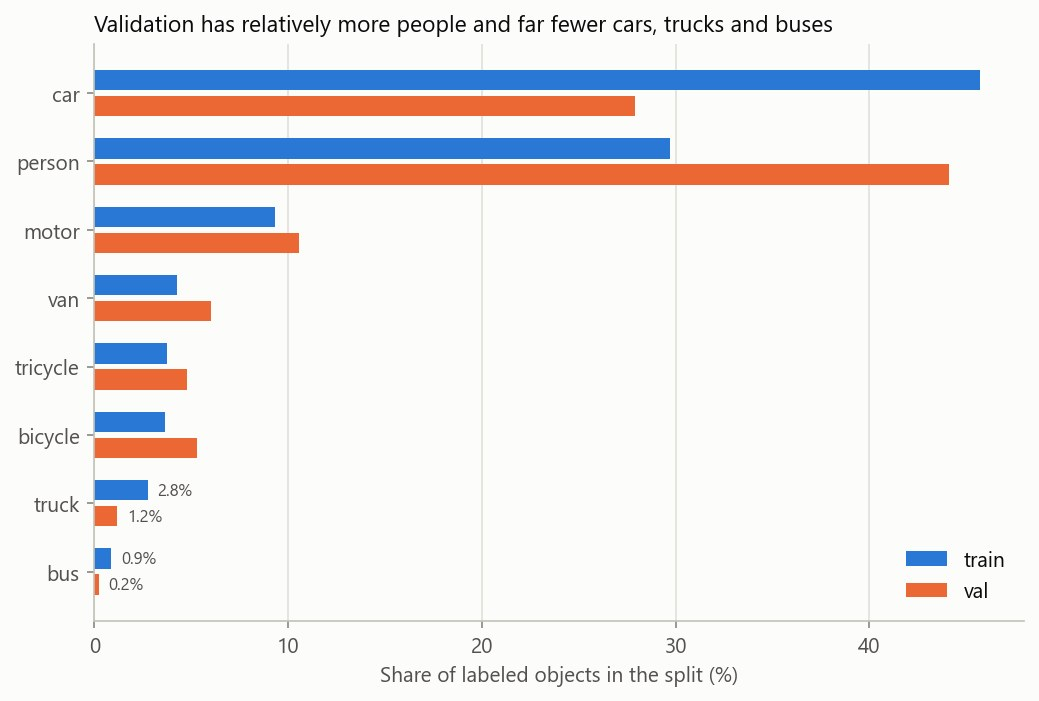

box_size_distribution.png


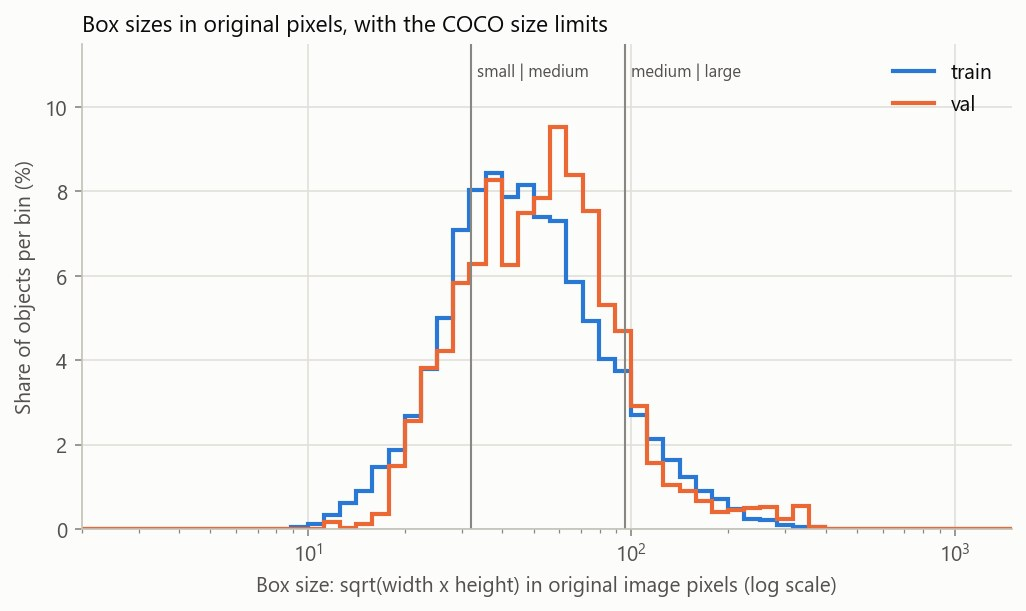

box_size_by_class.png


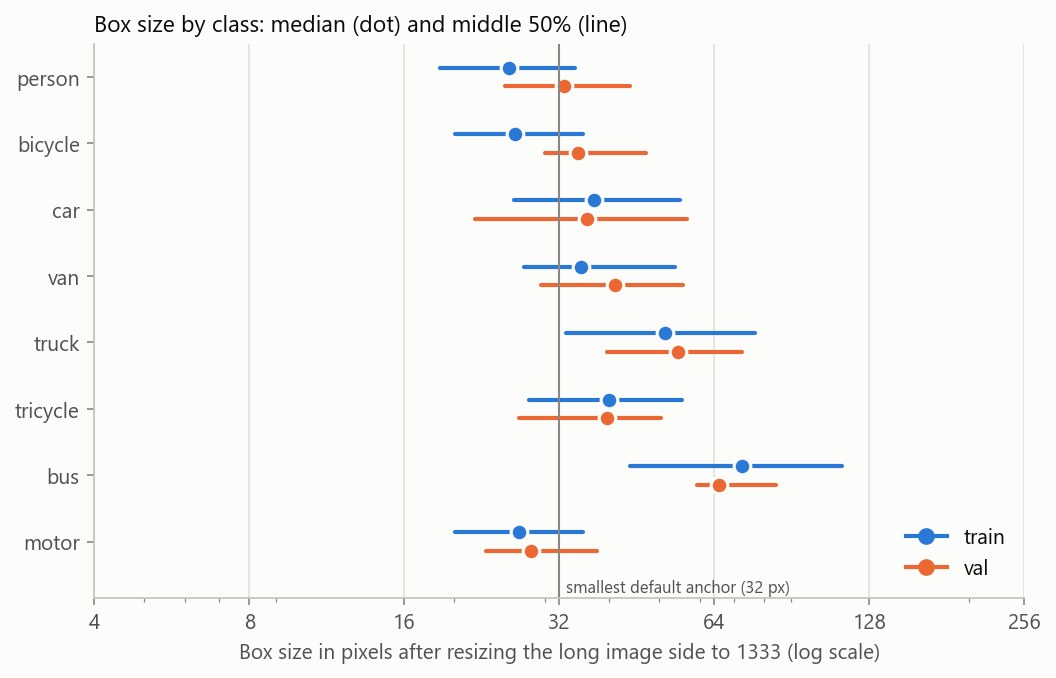

objects_per_frame.png


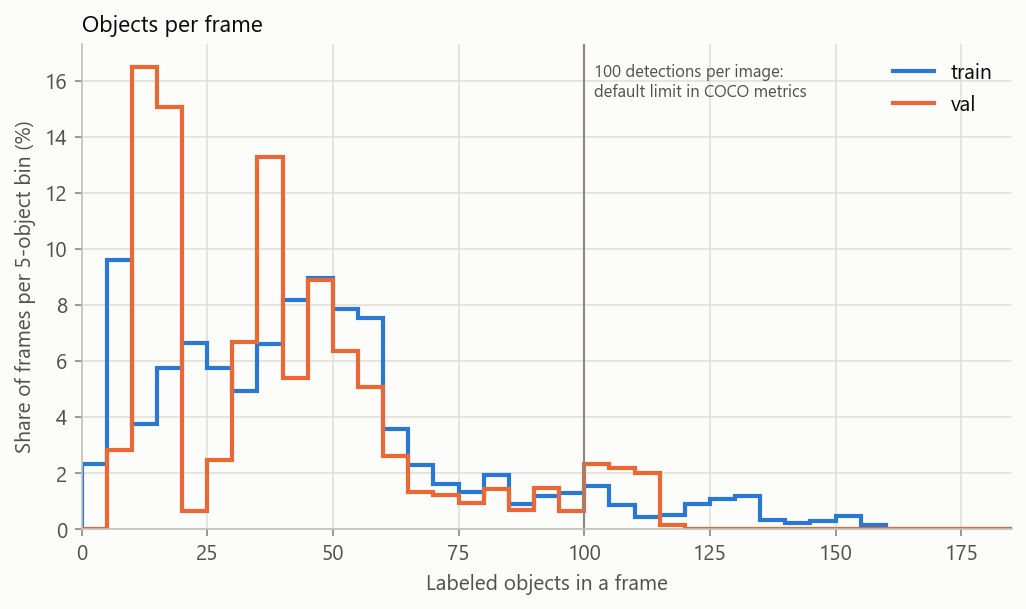

resolution_effect.png


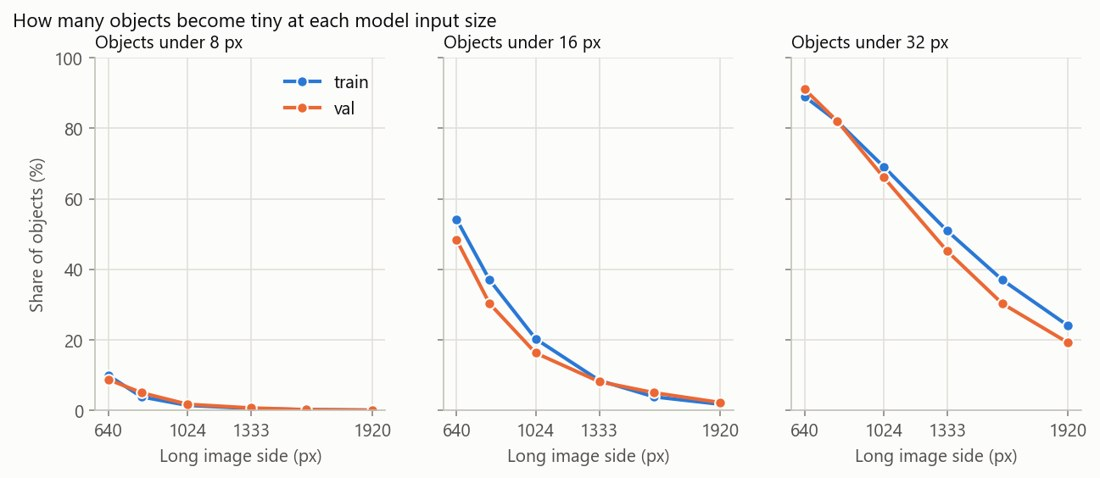

clip_overview.png


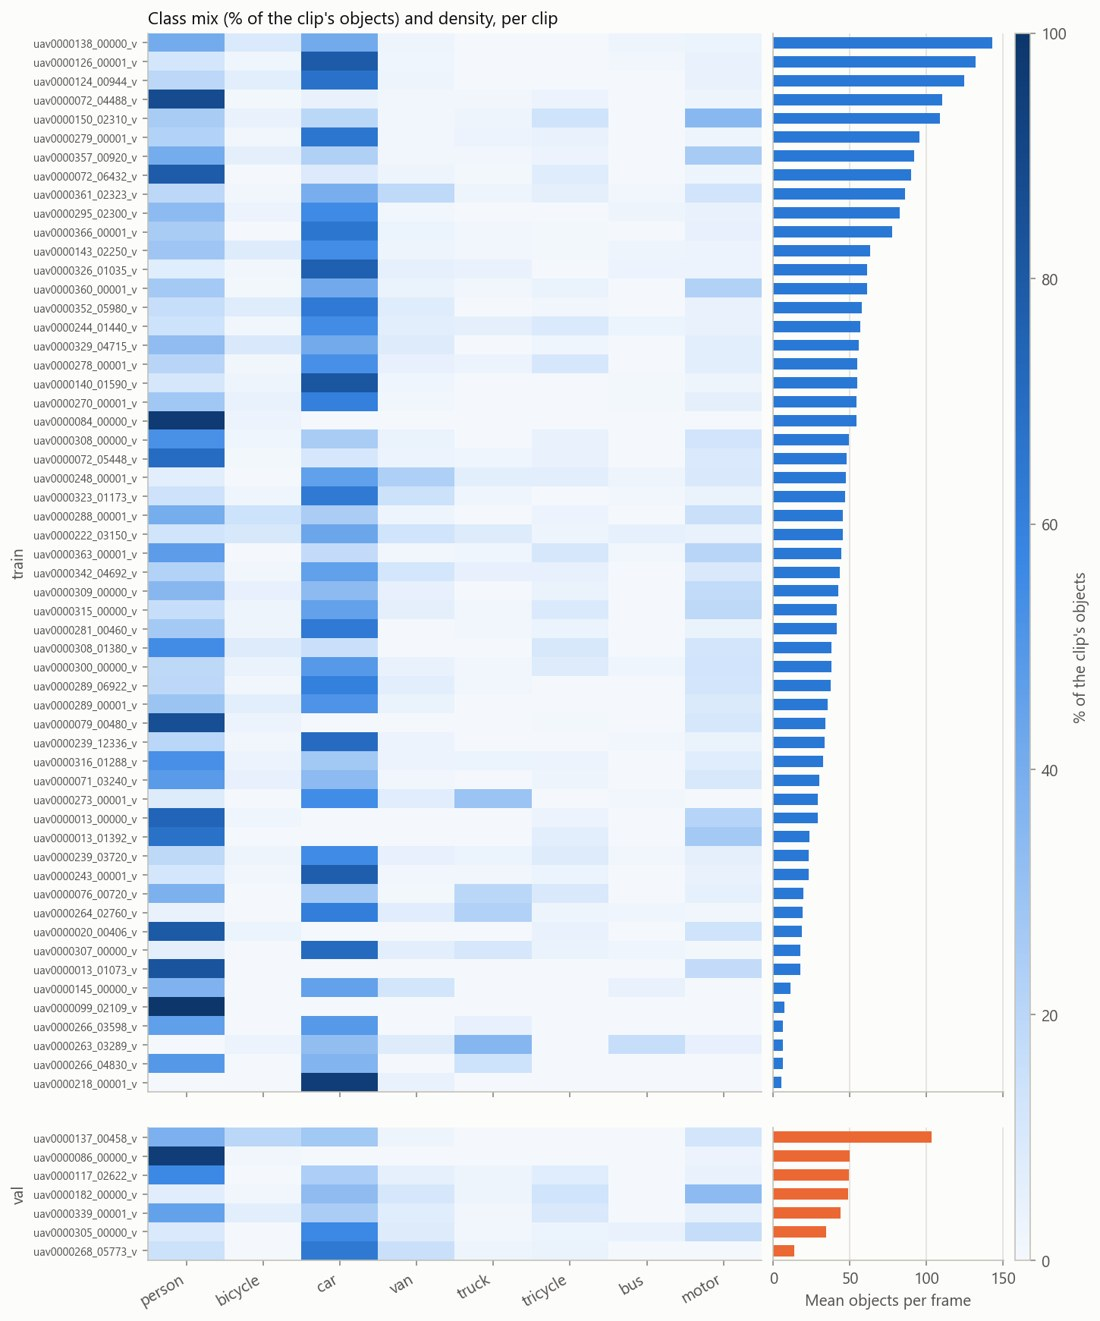

ground_truth_samples.png


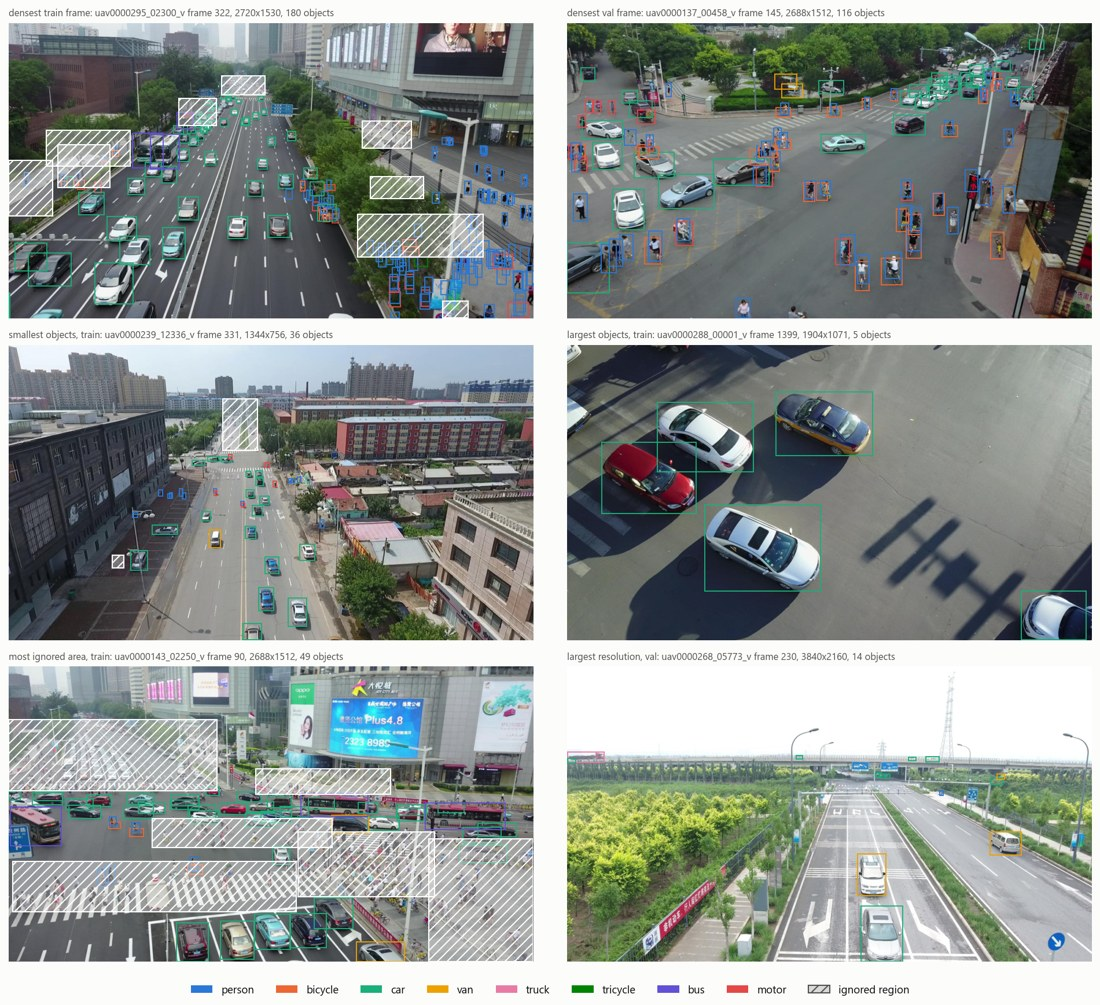

ignore_handling.png


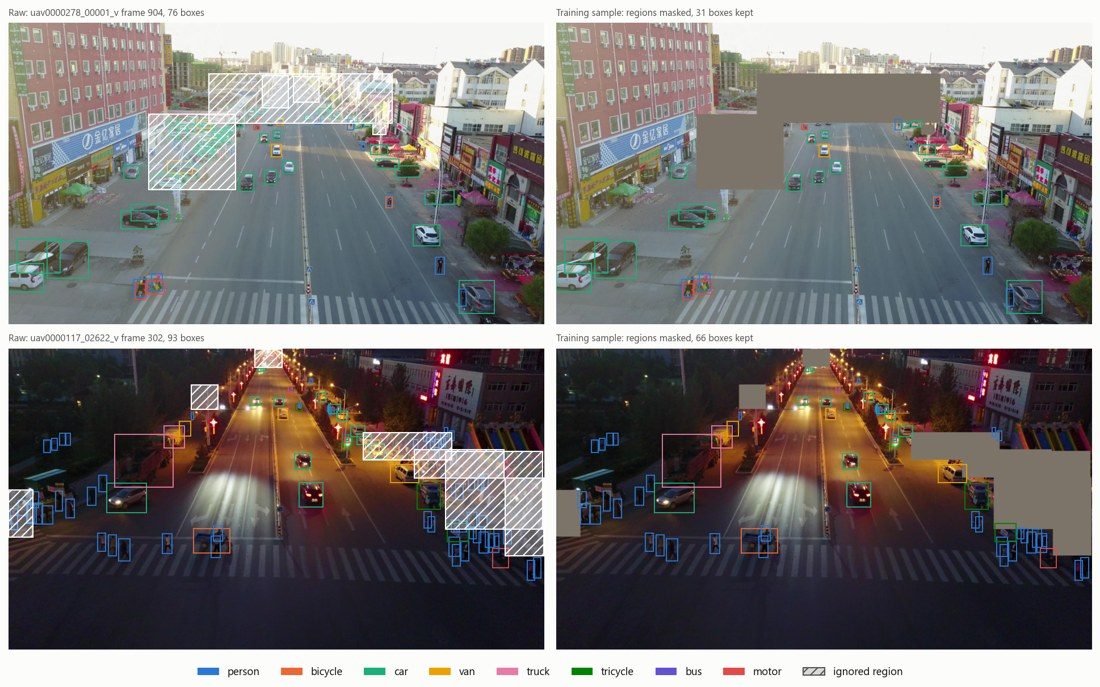

same_source_clips.png


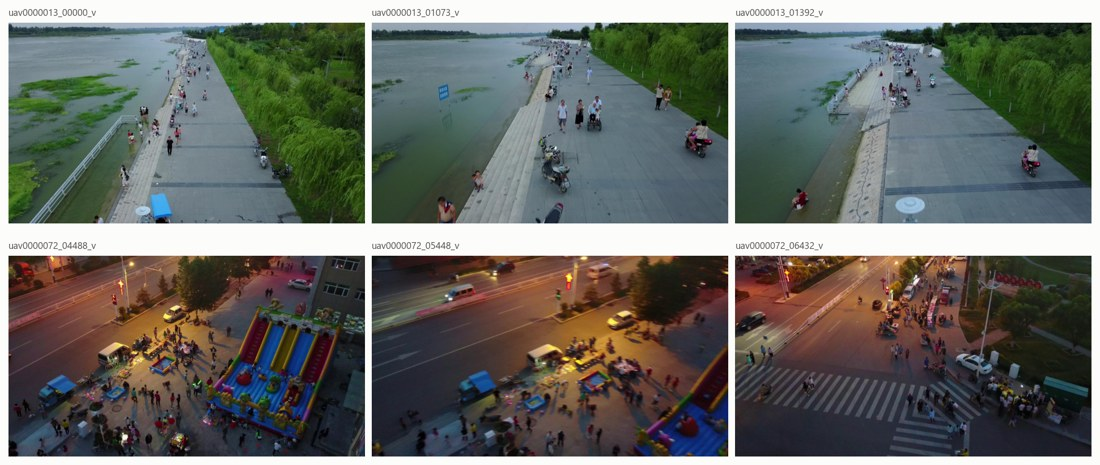

In [22]:
for name in ("class_distribution", "box_size_distribution", "box_size_by_class", "objects_per_frame", "resolution_effect", "clip_overview", "ground_truth_samples", "ignore_handling", "same_source_clips"):
    show_saved_figure(DATASET_DIR / f"{name}.png")

## 2. Faster R-CNN: two-stage anchor-based detection

## Shared protocol
These components are used unchanged for every model family, so results stay comparable:
- **Evaluation:** `pycocotools` on the official validation split, with the supplied `annotations_coco.json` and at most 500 detections per image (the competition limit). The default limit of 100 would cap recall, because 6.4% of validation frames have more than 100 objects.
- **Ignored regions:** masked in training images and handled by the metric at evaluation (`iscrowd=1`). Validation images are not masked, since test frames have no ignore data.
- **Training frames:** each epoch uses every `TRAIN_FRAME_STRIDE`-th frame of each clip with a different offset per epoch. Neighbouring frames are nearly identical (section 1: about 150 frames per object track), so this spreads a fixed budget over all frames.
- **Training budget.** All comparison runs train for five epochs with learning-rate drops near the starts of epochs 4 and 5. The rotating frame offset covers the entire training set once. Each run is scored using its final checkpoint.
- **Augmentation:** horizontal flip only, for the baselines.

In [23]:
import contextlib
from dataclasses import replace
from io import StringIO

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights, fasterrcnn_resnet50_fpn
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou

FRCNN_DIR = OUTPUT_ROOT / OUTPUT_DIRS[2]
EXPERIMENT_LOG = OUTPUT_ROOT / "experiment_log.csv"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 2026
MAX_DETECTIONS = 500
SCORE_THRESHOLD = 0.05
TRAIN_FRAME_STRIDE = 5
VAL_CURVE_STRIDE = 10
LOADER_THREADS = 8

train_frames = load_split("train")
val_frames = load_split("val")
val_curve_frames = [f for f in val_frames if f.frame_index % VAL_CURVE_STRIDE == 0]
print(len(train_frames), "train frames,", len(val_frames), "val frames,", len(val_curve_frames), "val frames for curves")

24201 train frames, 2846 val frames, 281 val frames for curves


### Data loading
Windows starts `DataLoader` workers as new processes, and they cannot import classes defined inside a notebook. A small thread pool is used instead: JPEG decoding releases Python's global lock, so threads still decode in parallel.

In [24]:
def iterate_batches(dataset, indices, batch_size, threads=LOADER_THREADS, prefetch=8):
    """Yield (images, targets) batches, loading samples in background threads, in order."""
    indices = iter(indices)
    with ThreadPoolExecutor(threads) as pool:
        pending, images, targets = deque(), [], []
        while True:
            while len(pending) < prefetch:
                index = next(indices, None)
                if index is None:
                    break
                pending.append(pool.submit(dataset.__getitem__, index))
            if not pending:
                break
            image, target = pending.popleft().result()
            images.append(image)
            targets.append(target)
            if len(images) == batch_size:
                yield images, targets
                images, targets = [], []
        if images:
            yield images, targets


class TrainingView:
    """Masked training samples with a random horizontal flip.

    The flip decision depends only on (seed, epoch, index), so it does not change
    with the order in which threads finish.
    """

    def __init__(self, frames, seed, epoch):
        self.dataset = VisDroneDataset(frames, mask_ignored=True)
        self.seed, self.epoch = seed, epoch

    def __getitem__(self, index):
        image, target = self.dataset[index]
        if np.random.default_rng((self.seed, self.epoch, index)).random() < 0.5:
            image = image.flip(-1)
            boxes = target["boxes"].clone()
            boxes[:, [0, 2]] = image.shape[-1] - target["boxes"][:, [2, 0]]
            target = {**target, "boxes": boxes}
        return image, target


def epoch_indices(frames, epoch, seed, stride=TRAIN_FRAME_STRIDE):
    """Every stride-th frame, offset by epoch so that all frames are eventually used, shuffled."""
    selected = [i for i, f in enumerate(frames) if (f.frame_index + epoch) % stride == 0]
    return np.random.default_rng((seed, epoch)).permutation(selected).tolist()

### Evaluation
Standard COCO metrics with a limit of 500 detections. COCOeval's overall AP summary defaults to 100, so overall mAP is averaged explicitly from the precision values for 500 detections. The other headline metrics use the 500-detection entries from the COCO summary.

In [25]:
_coco_ground_truth = {}

def coco_ground_truth(split="val"):
    if split not in _coco_ground_truth:
        with open(DATA_ROOT / split / "annotations_coco.json", encoding="utf-8") as file:
            dataset = json.load(file)
        coco = COCO()
        coco.dataset = dataset
        coco.createIndex()
        _coco_ground_truth[split] = coco
    return _coco_ground_truth[split]

def evaluate_detections(detections, image_ids=None, split="val"):
    """Return a dict of COCO metrics and per-class AP for a list of COCO-format detections."""
    ground_truth = coco_ground_truth(split)
    empty = {key: 0.0 for key in ("mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500")}
    empty.update({f"AP_{name}": 0.0 for name in CLASS_NAMES})
    if not detections:
        return empty
    with contextlib.redirect_stdout(StringIO()):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes(detections), "bbox")
        evaluator.params.maxDets = [1, 100, MAX_DETECTIONS]
        if image_ids is not None:
            evaluator.params.imgIds = sorted(image_ids)
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    precision = evaluator.eval["precision"][:, :, :, 0, -1]
    valid_precision = precision[precision >= 0]
    mean_ap = valid_precision.mean() if valid_precision.size else -1.0
    stats = evaluator.stats
    metrics = {"mAP": mean_ap, "AP50": stats[1], "AP75": stats[2], "AP_small": stats[3], "AP_medium": stats[4], "AP_large": stats[5], "AR500": stats[8]}
    for position, name in enumerate(CLASS_NAMES):
        values = precision[:, :, position]
        metrics[f"AP_{name}"] = float(values[values > -1].mean()) if (values > -1).any() else float("nan")
    return {key: float(value) for key, value in metrics.items()}

def frame_to_perfect_detections(frame, score=0.9):
    return [
        {"image_id": frame.image_id, "category_id": int(label) + 1, "bbox": [float(v) for v in box], "score": score}
        for box, label in zip(frame.boxes, frame.labels)
    ]

def check_evaluator():
    """Hand-checkable cases for the metric, on frames with objects and ignore regions."""
    frames = [f for f in val_frames if len(f.ignore) and len(f.boxes)][::40]
    ids = [f.image_id for f in frames]
    perfect = [d for f in frames for d in frame_to_perfect_detections(f)]
    baseline = evaluate_detections(perfect, ids)["AP50"]
    assert baseline > 0.99, baseline

    inside_ignored = [
        {"image_id": f.image_id, "category_id": 1, "bbox": [float(v) for v in f.ignore[0]], "score": 0.99}
        for f in frames
    ]
    with_ignored = evaluate_detections(perfect + inside_ignored, ids)["AP50"]
    assert abs(with_ignored - baseline) < 1e-6, (with_ignored, baseline)

    background = [
        {"image_id": f.image_id, "category_id": 1, "bbox": [1.0, 1.0, 3.0, 3.0], "score": 0.99}
        for f in frames for _ in range(5)
    ]
    with_background = evaluate_detections(perfect + background, ids)["AP50"]
    assert with_background < baseline - 1e-3, (with_background, baseline)

    densest = max(val_frames, key=lambda f: len(f.boxes))
    assert len(densest.boxes) > 100
    predictions = frame_to_perfect_detections(densest)
    recall = evaluate_detections(predictions, [densest.image_id])["AR500"]
    assert recall > 0.99, recall

    extra = [{**predictions[0], "bbox": [densest.width, densest.height, 1, 1]} for _ in range(100)]
    crowded = evaluate_detections(extra + predictions, [densest.image_id])
    per_class_ap = [crowded[f"AP_{name}"] for name in CLASS_NAMES]
    assert np.isclose(crowded["mAP"], np.nanmean(per_class_ap)), crowded

    print(
        f"AP50 perfect={baseline:.4f}, plus boxes in ignored regions={with_ignored:.4f}, "
        f"plus boxes on background={with_background:.4f}; "
        f"recall with {len(densest.boxes)} objects in a frame={recall:.4f}. Overall AP verified at 500."
    )

check_evaluator()

creating index...
index created!
AP50 perfect=1.0000, plus boxes in ignored regions=1.0000, plus boxes on background=0.9778; recall with 116 objects in a frame=1.0000. Overall AP verified at 500.


In [26]:
def check_flip():
    """A flipped sample must have mirrored pixels and exactly mirrored, valid boxes."""
    frame = next(f for f in val_frames if not len(f.ignore) and len(f.boxes))
    original_image, original_target = VisDroneDataset([frame], mask_ignored=True)[0]
    view = TrainingView([frame], seed=0, epoch=0)
    flips = 0
    for seed in range(20):
        view.seed = seed
        image, target = view[0]
        if torch.equal(image, original_image):
            assert torch.equal(target["boxes"], original_target["boxes"])
            continue
        flips += 1
        assert torch.equal(image, original_image.flip(-1))
        expected = original_target["boxes"].clone()
        expected[:, 0] = frame.width - original_target["boxes"][:, 2]
        expected[:, 2] = frame.width - original_target["boxes"][:, 0]
        assert torch.allclose(target["boxes"], expected)
        assert (target["boxes"][:, 2] > target["boxes"][:, 0]).all()
    assert 0 < flips < 20, flips
    print(f"flip correct: {flips} of 20 seeds flipped")


check_flip()

flip correct: 7 of 20 seeds flipped


### Experiment configuration and training loop
The optimizer settings follow the torchvision detection reference (SGD with momentum 0.9, weight decay 1e-4, learning rate 0.02 for batch size 16, scaled linearly to the batch size). The ResNet-50 FPN v1 weights are used because Faster R-CNN, RetinaNet and FCOS all have them, which keeps the backbone the same across the CNN families. Every long-side size below gives a fixed canvas, since all images are close to 16:9.

In [27]:
DEFAULT_ANCHORS = (32, 64, 128, 256, 512)
TRIAL_EPOCHS = 5

@dataclass
class Experiment:
    name: str
    change: str
    model: str = "faster_rcnn_r50_fpn_v1"
    stage: int = 2
    long_side: int = 1333
    batch_size: int = 2
    lr: float = 0.0025
    epochs: int = TRIAL_EPOCHS
    lr_decay_epochs: tuple = (3, 4)
    warmup_iterations: int = 500
    anchor_sizes: tuple = DEFAULT_ANCHORS
    seed: int = SEED
    optimizer: str = "sgd"
    backbone_lr: float = 0.0
    clip_grad_norm: float = 0.0
    focal_alpha: float = 0.25
    focal_gamma: float = 2.0
    center_sampling_radius: float = 1.5
    box_loss: str = "giou"
    init_weights: str = ""
    epoch_offset: int = 0
    sampler: str = "whole_frames"
    crop_share: float = 0.0
    crop_size: int = 0
    num_queries: int = 300

def build_faster_rcnn(config):
    """COCO-pretrained Faster R-CNN with a new 8-class head. Label 0 is background."""
    anchors = AnchorGenerator(tuple((s,) for s in config.anchor_sizes), ((0.5, 1.0, 2.0),) * len(config.anchor_sizes))
    model = fasterrcnn_resnet50_fpn(
        weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1,
        min_size=round(config.long_side * 0.6),
        max_size=config.long_side,
        rpn_anchor_generator=anchors,
        box_detections_per_img=MAX_DETECTIONS,
        box_score_thresh=SCORE_THRESHOLD,
    )
    features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(features, NUM_CLASSES + 1)
    model.label_offset = 1
    return model

MODEL_BUILDERS = {"faster_rcnn_r50_fpn_v1": build_faster_rcnn}

@torch.inference_mode()
def predict(model, frames, batch_size=2):
    """Run on unmasked frames and return COCO-format detections in original pixels."""
    model.eval()
    dataset = VisDroneDataset(frames, mask_ignored=False)
    detections = []
    for images, targets in iterate_batches(dataset, range(len(frames)), batch_size):
        outputs = model([image.to(DEVICE) for image in images])
        for target, output in zip(targets, outputs):
            boxes = output["boxes"].cpu().numpy()
            boxes[:, 2:] -= boxes[:, :2]
            for box, label, score in zip(boxes, output["labels"].cpu().numpy(), output["scores"].cpu().numpy()):
                detections.append(
                    {
                        "image_id": target["image_id"],
                        "category_id": int(label) - model.label_offset + 1,
                        "bbox": [round(float(v), 2) for v in box],
                        "score": round(float(score), 5),
                    }
                )
    return detections

@torch.inference_mode()
def measure_speed(model, frames, images_used=20, passes=10):
    """Frames per second, one image at a time on the GPU, excluding disk reads.

    Uses evenly spaced validation frames, so all resolutions are represented. The
    time includes the model's resize, the network and post-processing. The first
    pass only warms up the GPU and is not timed.
    """
    model.eval()
    selected = frames[:: len(frames) // images_used][:images_used]
    images = [VisDroneDataset(selected, mask_ignored=False)[i][0].to(DEVICE) for i in range(len(selected))]
    for image in images:
        model([image])
    torch.cuda.synchronize()
    started = time.perf_counter()
    for _ in range(passes):
        for image in images:
            model([image])
    torch.cuda.synchronize()
    return len(images) * passes / (time.perf_counter() - started)

def lr_factor(iteration, iterations_per_epoch, config):
    factor = min(1.0, (iteration + 1) / config.warmup_iterations)
    epoch = iteration // iterations_per_epoch
    return factor * 0.1 ** sum(epoch >= decay for decay in config.lr_decay_epochs)

def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)

def append_experiment_log(config, result):
    row = {**asdict(config), **result}
    row["anchor_sizes"] = "-".join(map(str, config.anchor_sizes))
    row["lr_decay_epochs"] = "-".join(map(str, config.lr_decay_epochs))
    table = pd.DataFrame([row])
    if EXPERIMENT_LOG.exists():
        previous = pd.read_csv(EXPERIMENT_LOG)
        table = pd.concat([previous[previous["name"] != config.name], table], ignore_index=True)
    table.to_csv(EXPERIMENT_LOG, index=False)

def build_optimizer(model, config):
    if config.optimizer == "sgd":
        parameters = [p for p in model.parameters() if p.requires_grad]
        return torch.optim.SGD(parameters, lr=config.lr, momentum=0.9, weight_decay=1e-4)
    backbone, no_decay, decay = [], [], []
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            group = backbone if ".backbone." in name else no_decay if name.endswith(".bias") or "norm" in name else decay
            group.append(parameter)
    groups = [{"params": decay}, {"params": no_decay, "weight_decay": 0.0}, {"params": backbone, "lr": config.backbone_lr}]
    return torch.optim.AdamW(groups, lr=config.lr, weight_decay=1e-4)

def whole_frame_samples(frames, config, epoch):
    """Sections 2-6.5: every stride-th frame, whole, with a random flip, in random order."""
    return TrainingView(frames, config.seed, epoch), epoch_indices(frames, epoch, config.seed)

SAMPLERS = {"whole_frames": whole_frame_samples}

def train_step(model, optimizer, scaler, parameters, images, targets, config):
    """One mixed-precision optimizer step. Returns the total loss and its terms."""
    images = [image.to(DEVICE, non_blocking=True) for image in images]
    targets = [
        {"boxes": t["boxes"].to(DEVICE), "labels": t["labels"].to(DEVICE) + model.label_offset,
         **({"keep_scale": True} if t.get("keep_scale") else {})}
        for t in targets
    ]
    with torch.amp.autocast("cuda"):
        losses = model(images, targets)
        loss = sum(losses.values())
    if not torch.isfinite(loss):
        raise RuntimeError(f"{config.name}: non-finite loss: {losses}")
    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    if config.clip_grad_norm:
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(parameters, config.clip_grad_norm)
    scaler.step(optimizer)
    scaler.update()
    return loss, losses

def train_experiment(config, frames=None, output_root=FRCNN_DIR):
    """Train, evaluate and log one experiment. Resumes after an interruption; skips if finished."""
    run_dir = output_root / config.name
    result_path = run_dir / "result.json"
    if result_path.exists():
        return json.loads(result_path.read_text())
    run_dir.mkdir(parents=True, exist_ok=True)
    frames = train_frames if frames is None else frames

    set_seed(config.seed)
    model = MODEL_BUILDERS[config.model](config).to(DEVICE)
    if config.init_weights:
        model.load_state_dict(torch.load(PROJECT_ROOT / config.init_weights, map_location="cpu"))
    parameters = [p for p in model.parameters() if p.requires_grad]
    optimizer = build_optimizer(model, config)
    scaler = torch.amp.GradScaler("cuda")
    iterations_per_epoch = int(np.ceil(len(epoch_indices(frames, 0, config.seed)) / config.batch_size))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda i: lr_factor(i, iterations_per_epoch, config))

    checkpoint_path = run_dir / "last.pt"
    first_epoch, history, elapsed = 0, [], 0.0
    if checkpoint_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location="cpu")
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        scaler.load_state_dict(checkpoint["scaler"])
        scheduler.load_state_dict(checkpoint["scheduler"])
        first_epoch, history, elapsed = checkpoint["epoch"] + 1, checkpoint["history"], checkpoint["elapsed"]
        del checkpoint
        print(f"{config.name}: resuming at epoch {first_epoch}", flush=True)

    torch.cuda.reset_peak_memory_stats()
    for epoch in range(first_epoch, config.epochs):
        started = time.time()
        model.train()
        frame_epoch = epoch + config.epoch_offset
        view, order = SAMPLERS[config.sampler](frames, config, frame_epoch)
        totals = Counter()
        batches = 0
        for images, targets in iterate_batches(view, order, config.batch_size):
            loss, losses = train_step(model, optimizer, scaler, parameters, images, targets, config)
            scheduler.step()
            batches += 1
            totals["loss"] += loss.item()
            for key, value in losses.items():
                totals[key] += value.item()

        train_seconds = time.time() - started
        elapsed += train_seconds
        curve = evaluate_detections(predict(model, val_curve_frames), [f.image_id for f in val_curve_frames])
        torch.cuda.empty_cache()
        row = {
            "epoch": epoch,
            "train_seconds": train_seconds,
            "lr": optimizer.param_groups[0]["lr"],
            **{key: value / batches for key, value in totals.items()},
            "val_subset_mAP": curve["mAP"],
            "val_subset_AP50": curve["AP50"],
            "val_subset_AP_small": curve["AP_small"],
        }
        history.append(row)
        pd.DataFrame(history).to_csv(run_dir / "history.csv", index=False)
        temporary = run_dir / "last.tmp"
        torch.save(
            {
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(),
                "scheduler": scheduler.state_dict(),
                "epoch": epoch,
                "history": history,
                "elapsed": elapsed,
            },
            temporary,
        )
        temporary.replace(checkpoint_path)
        print(
            f"{config.name} epoch {epoch + 1}/{config.epochs}: loss {row['loss']:.3f}, "
            f"val subset mAP {row['val_subset_mAP']:.4f}, AP_small {row['val_subset_AP_small']:.4f}, "
            f"{train_seconds / 60:.1f} min",
            flush=True,
        )

    detections = predict(model, val_frames)
    torch.cuda.empty_cache()
    (run_dir / "val_detections.json").write_text(json.dumps(detections))
    metrics = evaluate_detections(detections)
    result = {
        **metrics,
        "fps": measure_speed(model, val_frames),
        "train_minutes": elapsed / 60,
        "peak_vram_gb": torch.cuda.max_memory_reserved() / 1024**3,
        "frames_per_epoch": len(epoch_indices(frames, 0, config.seed)),
        "detections_per_image": len(detections) / len(val_frames),
    }
    torch.save(model.state_dict(), run_dir / "final.pt")
    checkpoint_path.unlink()
    result_path.write_text(json.dumps(result, indent=2))
    append_experiment_log(config, result)
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return result

### Experiment results and failure analysis tools
A failure analysis needs one operating point, so detections are kept at a fixed score of at least 0.5 and matched to objects of the same class at IoU of at least 0.5, highest score first. The remaining detections and objects are then labeled as follows:
- **Wrong class:** overlaps a still-unmatched object of another class at IoU of at least 0.5.
- **In ignored region:** at least half of the detection is inside an ignore region. This is not an error.
- **False positive:** any other unmatched detection.
- **Missed:** an object with no matching detection.

In [28]:
FAILURE_SCORE = 0.5
FAILURE_IOU = 0.5
STATUS_COLORS = {"missed": "#eb6834", "false positive": "#2a78d6", "wrong class": "#1baf7a"}

def analyse_frame(frame, detections):
    """Label each object and each detection of one frame with an outcome."""
    kept = sorted((d for d in detections if d["score"] >= FAILURE_SCORE), key=lambda d: -d["score"])
    boxes = np.array([d["bbox"] for d in kept], dtype=float).reshape(-1, 4)
    labels = np.array([d["category_id"] - 1 for d in kept], dtype=int)
    iou = box_iou(torch.as_tensor(xywh_to_xyxy(boxes)), torch.as_tensor(xywh_to_xyxy(frame.boxes))).numpy()
    object_status = np.full(len(frame.boxes), "missed", dtype=object)
    predicted = np.full(len(frame.boxes), -1, dtype=int)
    detection_status = np.full(len(kept), "false positive", dtype=object)
    taken = np.zeros(len(frame.boxes), dtype=bool)

    def best_match(detection, allowed):
        candidates = np.flatnonzero(allowed)
        if len(candidates) == 0:
            return None
        match = candidates[iou[detection, candidates].argmax()]
        return match if iou[detection, match] >= FAILURE_IOU else None

    for d in range(len(kept)):
        match = best_match(d, ~taken & (frame.labels == labels[d]))
        if match is not None:
            taken[match] = True
            detection_status[d], object_status[match] = "correct", "found"
    for d in np.flatnonzero(detection_status == "false positive"):
        match = best_match(d, ~taken)
        if match is not None:
            taken[match] = True
            detection_status[d], object_status[match] = "wrong class", "wrong class"
            predicted[match] = labels[d]
    unmatched = np.flatnonzero(detection_status == "false positive")
    if len(unmatched) and len(frame.ignore):
        inside = ignored_overlap(boxes[unmatched], frame.ignore) >= 0.5
        detection_status[unmatched[inside]] = "in ignored region"
    return object_status, predicted, boxes, labels, detection_status

def failure_tables(frames, detections):
    """Return per-object and per-detection tables for a full split."""
    by_image = defaultdict(list)
    for detection in detections:
        by_image[detection["image_id"]].append(detection)
    object_rows, detection_rows = [], []
    for position, frame in enumerate(frames):
        status, predicted, boxes, labels, detection_status = analyse_frame(frame, by_image[frame.image_id])
        sides = np.sqrt(frame.boxes[:, 2] * frame.boxes[:, 3])
        overlap = ignored_overlap(frame.boxes, frame.ignore)
        for i in range(len(frame.boxes)):
            object_rows.append((position, frame.clip, len(frame.boxes), int(frame.labels[i]), sides[i], int(frame.occlusion[i]), overlap[i] >= 0.5, status[i], predicted[i]))
        for i in range(len(boxes)):
            detection_rows.append((position, frame.clip, int(labels[i]), detection_status[i]))
    objects = pd.DataFrame(object_rows, columns=["frame_position", "clip", "objects_in_frame", "label", "side", "occlusion", "in_ignored_region", "status", "predicted"])
    detection_table = pd.DataFrame(detection_rows, columns=["frame_position", "clip", "label", "status"])
    return objects, detection_table

def recall_tables(objects):
    """Recall at the operating point, split by what may explain the failures."""
    objects = objects.assign(
        size=pd.cut(objects.side, [0, 16, 32, 96, np.inf], right=False, labels=["under 16 px", "16-32 px", "32-96 px", "96 px and over"]),
        density=pd.cut(objects.objects_in_frame, [0, 25, 50, 100, np.inf], labels=["1-25 objects", "26-50 objects", "51-100 objects", "over 100 objects"]),
        occlusion_level=objects.occlusion.map({0: "none", 1: "partial", 2: "heavy"}),
        class_name=objects.label.map(lambda i: CLASS_NAMES[i]),
        ignored=objects.in_ignored_region.map({True: "inside ignored region", False: "outside"}),
    )
    rows = []
    for column in ("class_name", "size", "occlusion_level", "density", "ignored"):
        for value, table in objects.groupby(column, observed=True):
            rows.append(
                {
                    "group": column,
                    "value": value,
                    "objects": len(table),
                    "found": (table.status == "found").mean(),
                    "wrong_class": (table.status == "wrong class").mean(),
                    "missed": (table.status == "missed").mean(),
                }
            )
    return pd.DataFrame(rows)

def confusion_table(objects):
    wrong = objects[objects.status == "wrong class"]
    table = pd.crosstab(wrong.label.map(lambda i: CLASS_NAMES[i]), wrong.predicted.map(lambda i: CLASS_NAMES[i]))
    table.index.name, table.columns.name = "true class", "predicted class"
    return table

def per_clip_metrics(frames, detections):
    rows = []
    for clip in sorted({f.clip for f in frames}):
        ids = {f.image_id for f in frames if f.clip == clip}
        selected = [d for d in detections if d["image_id"] in ids]
        metrics = evaluate_detections(selected, ids)
        frame = next(f for f in frames if f.clip == clip)
        rows.append({"clip": clip, "width": frame.width, "frames": len(ids), "mAP": metrics["mAP"], "AP50": metrics["AP50"], "AP_small": metrics["AP_small"]})
    return pd.DataFrame(rows)

def select_failure_frames(frames, objects, detection_table):
    """One frame per failure type, from different clips, chosen by rule so it is reproducible."""
    frame_clip = {i: f.clip for i, f in enumerate(frames)}
    rules = [
        ("most missed objects", objects[objects.status == "missed"].frame_position),
        ("most missed objects under 32 px", objects[(objects.status == "missed") & (objects.side < 32)].frame_position),
        ("most false positives", detection_table[detection_table.status == "false positive"].frame_position),
        ("most wrong-class detections", detection_table[detection_table.status == "wrong class"].frame_position),
    ]
    chosen, used_clips = [], set()
    for title, positions in rules:
        for position, count in positions.value_counts().items():
            if frame_clip[position] not in used_clips:
                used_clips.add(frame_clip[position])
                chosen.append((title, position, count))
                break
    return chosen

def plot_failure_cases(frames, detections, chosen, path):
    """Each failure type on a full frame. Correct results are drawn thin and white."""
    by_image = defaultdict(list)
    for detection in detections:
        by_image[detection["image_id"]].append(detection)
    figure, axes = plt.subplots(2, 2, figsize=(13, 8))
    for axis, (title, position, count) in zip(axes.ravel(), chosen):
        frame = frames[position]
        status, _, boxes, _, detection_status = analyse_frame(frame, by_image[frame.image_id])
        draw_frame(axis, frame, boxes=np.zeros((0, 4)), labels=[], show_ignore=False, title=f"{title} ({count}): {frame.clip} frame {frame.frame_index}, {frame.width}x{frame.height}, {len(frame.boxes)} objects")
        for x, y, w, h in frame.ignore:
            axis.add_patch(Rectangle((x, y), w, h, facecolor=(1, 1, 1, 0.25), edgecolor="white", linewidth=0.8, hatch="///"))
        for (x, y, w, h), value in zip(frame.boxes, status):
            if value == "found":
                axis.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="white", linewidth=0.5))
            elif value == "missed":
                axis.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=STATUS_COLORS["missed"], linewidth=1.4))
        for (x, y, w, h), value in zip(boxes, detection_status):
            if value in ("false positive", "wrong class"):
                axis.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=STATUS_COLORS[value], linewidth=1.4))
    handles = [Patch(facecolor=color, label=name) for name, color in STATUS_COLORS.items()]
    handles.append(Patch(facecolor=SURFACE, edgecolor=INK_2, label="correct"))
    handles.append(Patch(facecolor="#d9d9d9", edgecolor=INK_2, hatch="///", label="ignored region"))
    figure.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=9)
    figure.subplots_adjust(hspace=0.09, wspace=0.02, bottom=0.05, top=0.97, left=0.01, right=0.99)
    figure.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(figure)

def plot_learning_curves(run_dirs, path, by_hours=False):
    """Validation curves of several runs, against epochs or cumulative training hours."""
    figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    panels = (("val_subset_mAP", "mAP"), ("val_subset_AP_small", "AP_small"))
    for axis, (column, title) in zip(axes, panels):
        for position, run_dir in enumerate(run_dirs):
            history = pd.read_csv(run_dir / "history.csv")
            x = history.train_seconds.cumsum() / 3600 if by_hours else history.epoch + 1
            axis.plot(x, history[column], color=CLASS_COLORS[position], linewidth=2, label=run_dir.name)
        axis.set_title(f"{title} on the validation subset", loc="left", fontsize=10)
        axis.set_xlabel("Training hours" if by_hours else "Epoch")
    axes[0].legend(fontsize=8)
    figure.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(figure)

def stage_dir(stage):
    return OUTPUT_ROOT / OUTPUT_DIRS[stage]

EXPERIMENT_REGISTRY = {}

def run_experiments(experiments):
    for config in experiments:
        EXPERIMENT_REGISTRY[config.name] = config
        result = train_experiment(config, output_root=stage_dir(config.stage))
        print(config.name, {key: round(result[key], 4) for key in ("mAP", "AP50", "AP_small", "fps", "train_minutes")}, flush=True)

RESULT_COLUMNS = ["name", "model", "change", "long_side", "batch_size", "epochs", "lr", "anchor_sizes", "focal_alpha", "focal_gamma", "center_sampling_radius", "num_queries", "mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500", "fps", "train_minutes", "peak_vram_gb"]

def results_table(stages, *, include_reference=False):
    table = pd.read_csv(EXPERIMENT_LOG)
    selected = table[table.stage.isin(stages) & table.name.isin(EXPERIMENT_REGISTRY)]
    if not include_reference:
        selected = selected[selected.epochs == TRIAL_EPOCHS]
    return selected

def best_run(stages, *, include_reference=False):
    """Folder of the completed run with the highest validation mAP."""
    row = results_table(stages, include_reference=include_reference).sort_values("mAP").iloc[-1]
    return stage_dir(row["stage"]) / row["name"]

def recall_comparison(run_dirs, group):
    """Share of objects found by each run at the failure-analysis operating point."""
    columns = {}
    for run_dir in run_dirs:
        if not (run_dir / "recall_breakdown.csv").exists():
            run_failure_analysis(run_dir.name, run_dir.parent)
        table = pd.read_csv(run_dir / "recall_breakdown.csv")
        columns[run_dir.name] = table[table.group == group].set_index("value").found
    return pd.DataFrame(columns)

def run_failure_analysis(name, output_root=FRCNN_DIR):
    """Write and show all failure-analysis results for one finished experiment."""
    run_dir = output_root / name
    detections = json.loads((run_dir / "val_detections.json").read_text())
    objects, detection_table = failure_tables(val_frames, detections)
    recall = recall_tables(objects)
    confusion = confusion_table(objects)
    outcomes = detection_table.status.value_counts().rename_axis("detection outcome").reset_index(name="detections")
    clips = per_clip_metrics(val_frames, detections)
    chosen = select_failure_frames(val_frames, objects, detection_table)
    recall.to_csv(run_dir / "recall_breakdown.csv", index=False, float_format="%.4f")
    confusion.to_csv(run_dir / "class_confusion.csv")
    outcomes.to_csv(run_dir / "detection_outcomes.csv", index=False)
    clips.to_csv(run_dir / "per_clip_metrics.csv", index=False, float_format="%.4f")
    plot_failure_cases(val_frames, detections, chosen, run_dir / "failure_cases.png")
    return recall, confusion, outcomes, clips, chosen

### Run the experiments
Measured on this machine (RTX 3070 Ti Laptop, 8 GB, about 0.6-2 GB used by other applications) with a short benchmark of real training steps:

| Long side, batch | Images per second | Peak VRAM |
|---|---|---|
| 1024, batch 4 | 11.7 | 4.5 GB |
| 1333, batch 2 | 7.7 | 5.6 GB |
| 1333, batch 4 | 1.2 (exceeds free VRAM) | 7.9 GB |
| 1600, batch 2 | 0.2 (exceeds free VRAM) | 7.8 GB |

The Faster R-CNN control uses long side 1333, batch size 2 and a learning rate of 0.0025. The table comes from short tests. The full run's `peak_vram_gb` records PyTorch's peak CUDA allocator reservation across training and validation.

The comparison runs have their own five-epoch checkpoints. When available, the completed 12-epoch Faster R-CNN run is shown as a separate reference. Its final mAP uses the 500-detection limit. The saved per-epoch mAP for that run used the 100-detection limit.

Completed 12-epoch Faster R-CNN reference


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,fps,train_minutes,peak_vram_gb
0,0.1851,0.3722,0.1629,0.0836,0.1713,0.338,0.2766,15.1585,146.7487,9.5469


,group,value,objects,found,wrong_class,missed
0,class_name,bicycle,6022,0.265,0.308,0.427
1,class_name,bus,264,0.046,0.701,0.254
2,class_name,car,31821,0.596,0.019,0.385
3,class_name,motor,12025,0.350,0.131,0.518
4,class_name,person,50312,0.645,0.002,0.352
5,class_name,tricycle,5487,0.297,0.194,0.510
6,class_name,truck,1359,0.489,0.100,0.411
7,class_name,van,6842,0.284,0.382,0.334
8,size,under 16 px,380,0.024,0.003,0.974
9,size,16-32 px,21530,0.371,0.063,0.566


failure_cases.png


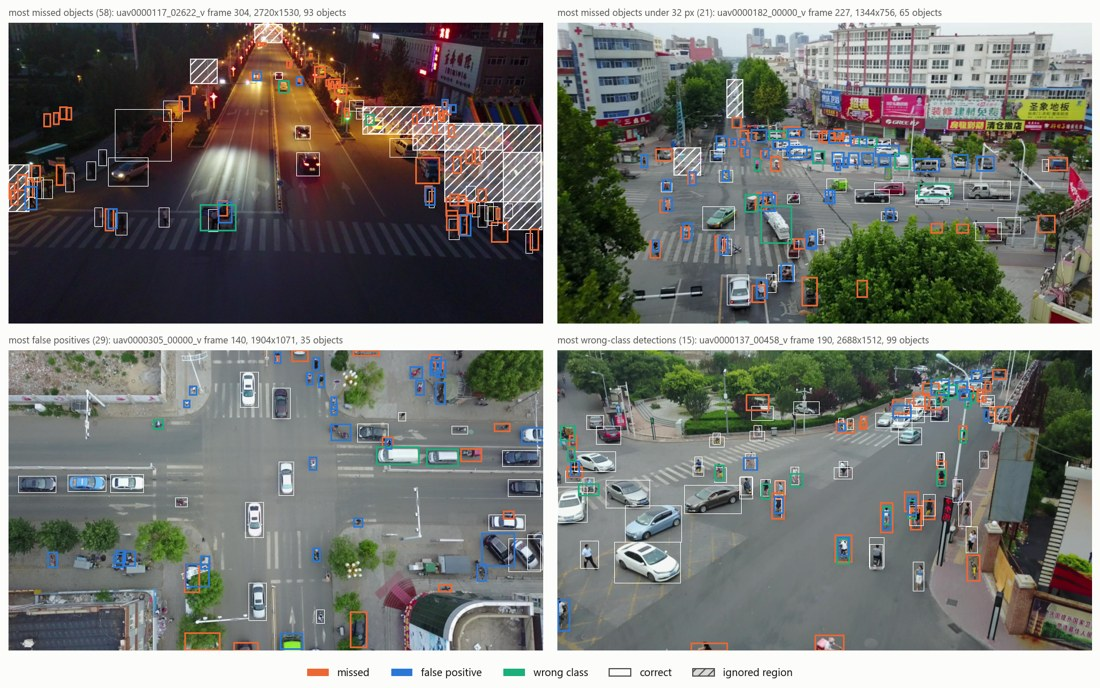

In [29]:
REFERENCE_BASELINE = Experiment(
    name="frcnn_baseline",
    change="Completed 12-epoch Faster R-CNN reference",
    epochs=12,
    lr_decay_epochs=(8, 11),
)
EXPERIMENT_REGISTRY[REFERENCE_BASELINE.name] = REFERENCE_BASELINE
reference_dir = stage_dir(2) / REFERENCE_BASELINE.name
reference_result_path = reference_dir / "result.json"
if reference_result_path.is_file():
    print("Completed 12-epoch Faster R-CNN reference")
    reference_metrics = json.loads(reference_result_path.read_text(encoding="utf-8"))
    reference_columns = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500", "fps", "train_minutes", "peak_vram_gb"]
    display(pd.DataFrame([reference_metrics])[reference_columns].round(4))
    if not (reference_dir / "failure_cases.png").is_file():
        run_failure_analysis(REFERENCE_BASELINE.name)
    display(pd.read_csv(reference_dir / "recall_breakdown.csv").round(3))
    show_saved_figure(reference_dir / "failure_cases.png")

In [30]:
BASELINE = Experiment(name=f"frcnn_baseline_{TRIAL_EPOCHS}ep", change="Reference: torchvision defaults, long side 1333, batch 2, lr 0.0025")
EXPERIMENTS = [
    BASELINE,
    replace(BASELINE, name=f"frcnn_lr_005_{TRIAL_EPOCHS}ep", lr=0.005, change="Learning rate doubled to 0.005"),
    replace(BASELINE, name=f"frcnn_long_1024_{TRIAL_EPOCHS}ep", long_side=1024, change="Long side 1024: faster, but objects are smaller"),
    replace(BASELINE, name=f"frcnn_anchors_16_256_{TRIAL_EPOCHS}ep", anchor_sizes=(16, 32, 64, 128, 256), change="Anchors 16-256: shape coverage 98.0% against 74.5% (section 1)"),
]
run_experiments(EXPERIMENTS)

frcnn_baseline_5ep {'mAP': 0.1941, 'AP50': 0.397, 'AP_small': 0.0924, 'fps': 5.1871, 'train_minutes': 47.9227}
frcnn_lr_005_5ep {'mAP': 0.1966, 'AP50': 0.4004, 'AP_small': 0.0935, 'fps': 14.782, 'train_minutes': 63.1029}
frcnn_long_1024_5ep {'mAP': 0.1791, 'AP50': 0.3729, 'AP_small': 0.0854, 'fps': 22.389, 'train_minutes': 31.5984}
frcnn_anchors_16_256_5ep {'mAP': 0.1969, 'AP50': 0.4163, 'AP_small': 0.1016, 'fps': 14.9693, 'train_minutes': 72.27}


,name,model,change,long_side,batch_size,epochs,lr,anchor_sizes,focal_alpha,focal_gamma,center_sampling_radius,num_queries,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,fps,train_minutes,peak_vram_gb
1,frcnn_baseline_5ep,faster_rcnn_r50_fpn_v1,"Reference: torchvision defaults, long side 133...",1333,2,5,0.0025,32-64-128-256-512,0.25,2.0,1.5,300,0.1941,0.3970,0.1664,0.0924,0.1775,0.3584,0.3011,5.1871,47.9227,7.8574
2,frcnn_lr_005_5ep,faster_rcnn_r50_fpn_v1,Learning rate doubled to 0.005,1333,2,5,0.0050,32-64-128-256-512,0.25,2.0,1.5,300,0.1966,0.4004,0.1663,0.0935,0.1830,0.3634,0.3027,14.7820,63.1029,9.7324
3,frcnn_long_1024_5ep,faster_rcnn_r50_fpn_v1,"Long side 1024: faster, but objects are smaller",1024,2,5,0.0025,32-64-128-256-512,0.25,2.0,1.5,300,0.1791,0.3729,0.1522,0.0854,0.1588,0.3433,0.2925,22.3890,31.5984,6.8301
4,frcnn_anchors_16_256_5ep,faster_rcnn_r50_fpn_v1,Anchors 16-256: shape coverage 98.0% against 7...,1333,2,5,0.0025,16-32-64-128-256,0.25,2.0,1.5,300,0.1969,0.4163,0.1638,0.1016,0.1844,0.3463,0.3099,14.9693,72.2700,9.7324


,name,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
1,frcnn_baseline_5ep,0.2582,0.1593,0.3742,0.2075,0.2566,0.1953,0.0012,0.1009
2,frcnn_lr_005_5ep,0.2590,0.1727,0.3795,0.2152,0.2474,0.1873,0.0040,0.1081
3,frcnn_long_1024_5ep,0.2358,0.1480,0.3513,0.2056,0.2223,0.1728,0.0053,0.0918
4,frcnn_anchors_16_256_5ep,0.2605,0.1927,0.3785,0.2181,0.2191,0.1923,0.0011,0.1127


learning_curves.png


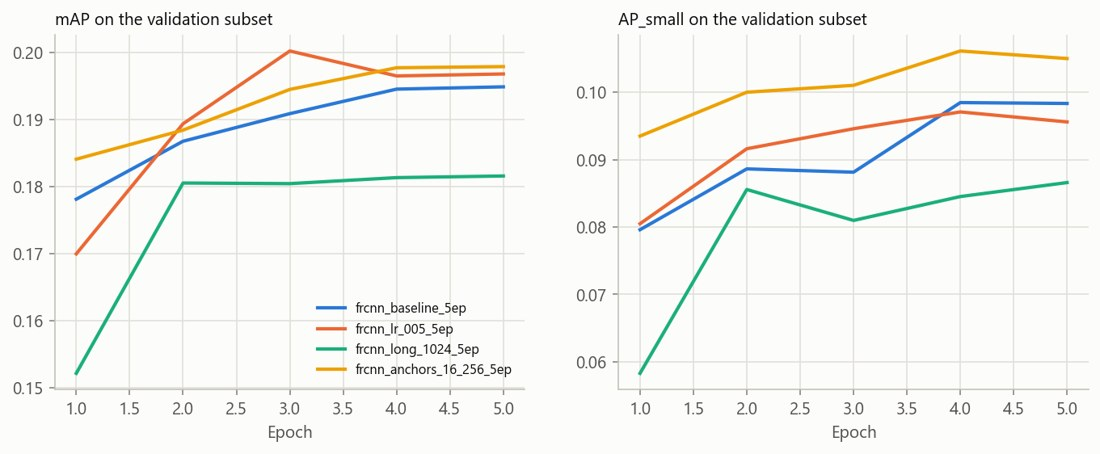

In [31]:
frcnn_results = results_table([2])
display(frcnn_results[RESULT_COLUMNS].round(4))
display(frcnn_results[["name"] + [f"AP_{name}" for name in CLASS_NAMES]].round(4))
plot_learning_curves([FRCNN_DIR / name for name in frcnn_results.name], FRCNN_DIR / "learning_curves.png")
show_saved_figure(FRCNN_DIR / "learning_curves.png")

#### Results: Faster R-CNN
Baseline (torchvision defaults, 5 epochs): mAP 0.1941.
- **Small gain: anchors 16–256.** mAP 0.1969 (+0.0028) and AP_small 0.0924 → 0.1016, the best AP_small in sections 2–5. This run is the starting point of every later Faster R-CNN (sections 6.6–6.8).
- **Small gain: learning rate 0.005.** mAP 0.1966 (+0.0025). Not combined with the anchors.
- **Did not work: long side 1024.** mAP 0.1791 (−0.015) and AP_small 0.0854, although training took 31.6 instead of 47.9 minutes.

The failure analysis below uses the best run, anchors 16–256.

Failure analysis for: frcnn_anchors_16_256_5ep


,group,value,objects,found,wrong_class,missed
0,class_name,bicycle,6022,0.381,0.247,0.372
1,class_name,bus,264,0.011,0.731,0.258
2,class_name,car,31821,0.619,0.023,0.358
3,class_name,motor,12025,0.381,0.103,0.516
4,class_name,person,50312,0.645,0.003,0.352
5,class_name,tricycle,5487,0.352,0.145,0.503
6,class_name,truck,1359,0.435,0.101,0.464
7,class_name,van,6842,0.300,0.400,0.300
8,size,under 16 px,380,0.032,0.000,0.968
9,size,16-32 px,21530,0.382,0.049,0.569


predicted class,bicycle,bus,car,motor,person,tricycle,truck,van
true class,,,,,,,,
bicycle,0,0,0,1135,281,70,0,0
bus,0,0,173,0,0,0,13,7
car,0,8,0,0,0,27,62,645
motor,106,0,5,0,961,171,0,0
person,15,0,0,133,0,0,0,0
tricycle,8,0,129,361,57,0,129,114
truck,0,0,32,0,0,91,0,14
van,0,2,2573,0,0,31,131,0


,detection outcome,detections
0,correct,63579
1,false positive,20483
2,in ignored region,8745
3,wrong class,7484


,clip,width,frames,mAP,AP50,AP_small
0,uav0000086_00000_v,1344,464,0.1767,0.5096,0.2042
1,uav0000117_02622_v,2720,349,0.2116,0.4434,0.0248
2,uav0000137_00458_v,2688,233,0.2932,0.6587,0.0043
3,uav0000182_00000_v,1344,363,0.1746,0.3999,0.1357
4,uav0000268_05773_v,3840,978,0.1001,0.1389,0.0008
5,uav0000305_00000_v,1904,184,0.2422,0.3698,0.0302
6,uav0000339_00001_v,1904,275,0.2349,0.4282,0.0684


most missed objects: uav0000117_02622_v frame 304, count 55
most missed objects under 32 px: uav0000182_00000_v frame 190, count 21
most false positives: uav0000137_00458_v frame 114, count 34
most wrong-class detections: uav0000339_00001_v frame 58, count 9
failure_cases.png


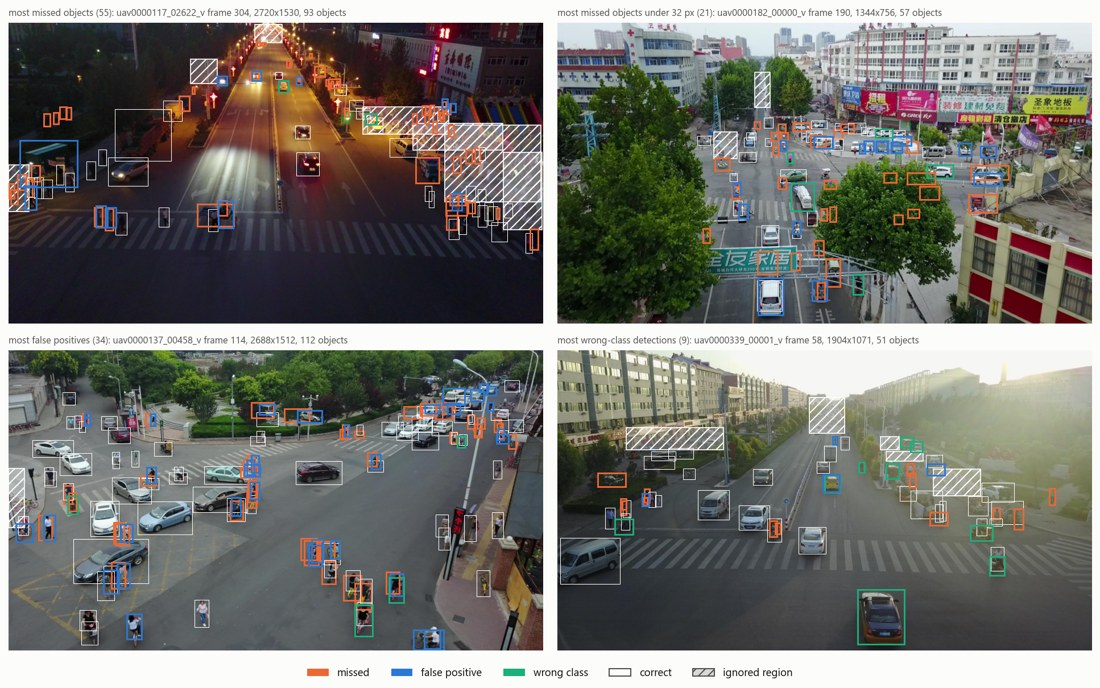

In [32]:
ANALYSED_EXPERIMENT = frcnn_results.sort_values("mAP").iloc[-1]["name"]
print("Failure analysis for:", ANALYSED_EXPERIMENT)
recall, confusion, outcomes, clips, chosen = run_failure_analysis(ANALYSED_EXPERIMENT)
display(recall.round(3), confusion, outcomes, clips.round(4))
for title, position, count in chosen:
    print(f"{title}: {val_frames[position].clip} frame {val_frames[position].frame_index}, count {count}")
show_saved_figure(FRCNN_DIR / ANALYSED_EXPERIMENT / "failure_cases.png")

## 3. RetinaNet: one-stage anchor-based detection

Everything in the shared protocol of section 2 is unchanged: frames, ignore handling, augmentation, epochs, evaluation and score threshold. Only the model and its learning rate differ.

- **Model:** torchvision `retinanet_resnet50_fpn` with COCO v1 weights (the same ResNet-50 FPN v1 family as Faster R-CNN). The classification convolutions and the regression head keep their pretrained weights; only the final classification layer is replaced.
- **Labels:** RetinaNet has one sigmoid output per class and no background output, so the 8 classes use labels 0-7 directly.
- **Learning rate:** the torchvision reference trains RetinaNet at 0.01 for batch size 16 (8 GPUs with 2 images each), so 0.01 x 2 / 16 = 0.00125.

**Experiments**
- **Anchors 16-256.** Section 1 measured, at long side 1333, how many training boxes have a default-grid anchor shape with high IoU. IoU of at least 0.5: 74.5% for 32-512 and 98.0% for 16-256. IoU of at least 0.7: 61.3% and 93.5%. These are upper bounds that ignore the grid. Sizes 8-128 add little (99.9% and 97.0%) and would leave the largest objects with no well-sized anchor.
- **Focal loss alpha 0.5.** The default alpha of 0.25 lowers the weight of positive anchors, a setting tuned on COCO. VisDrone frames contain many more objects, so positives are less rare and the weighting may suppress recall for small objects. The experiment raises the weight of positives; gamma stays at 2.

In [33]:
from torchvision.models.detection import (
    FCOS_ResNet50_FPN_Weights,
    RetinaNet_ResNet50_FPN_Weights,
    fcos_resnet50_fpn,
    retinanet_resnet50_fpn,
)
from torchvision.models.detection.fcos import FCOSClassificationHead
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.ops import box_convert, sigmoid_focal_loss

ONE_STAGE_LR = 0.00125

class ConfigurableFocalHead(RetinaNetClassificationHead):
    """RetinaNet classification head with configurable focal loss parameters.

    torchvision fixes alpha and gamma inside `compute_loss`. This method follows
    torchvision's own implementation (BSD-3-Clause) and differs only by passing them on.
    """

    def __init__(self, in_channels, num_anchors, num_classes, alpha, gamma):
        super().__init__(in_channels, num_anchors, num_classes)
        self.alpha, self.gamma = alpha, gamma

    def compute_loss(self, targets, head_outputs, matched_idxs):
        losses = []
        for target, logits, matched in zip(targets, head_outputs["cls_logits"], matched_idxs):
            foreground = matched >= 0
            labels = torch.zeros_like(logits)
            labels[foreground, target["labels"][matched[foreground]]] = 1.0
            valid = matched != self.BETWEEN_THRESHOLDS
            loss = sigmoid_focal_loss(logits[valid], labels[valid], alpha=self.alpha, gamma=self.gamma, reduction="sum")
            losses.append(loss / max(1, foreground.sum()))
        return sum(losses) / len(targets)

def retinanet_anchors(sizes):
    """Three octave scales and three aspect ratios per level, as in torchvision's default."""
    scales = tuple((s, int(s * 2 ** (1 / 3)), int(s * 2 ** (2 / 3))) for s in sizes)
    return AnchorGenerator(scales, ((0.5, 1.0, 2.0),) * len(sizes))

def build_retinanet(config):
    """COCO-pretrained RetinaNet with a new final classification layer for 8 classes."""
    model = retinanet_resnet50_fpn(
        weights=RetinaNet_ResNet50_FPN_Weights.COCO_V1,
        min_size=round(config.long_side * 0.6),
        max_size=config.long_side,
        anchor_generator=retinanet_anchors(config.anchor_sizes),
        score_thresh=SCORE_THRESHOLD,
        detections_per_img=MAX_DETECTIONS,
    )
    pretrained = model.head.classification_head
    head = ConfigurableFocalHead(model.backbone.out_channels, pretrained.num_anchors, NUM_CLASSES, config.focal_alpha, config.focal_gamma)
    head.conv.load_state_dict(pretrained.conv.state_dict())
    model.head.classification_head = head
    model.label_offset = 0
    return model

MODEL_BUILDERS["retinanet_r50_fpn_v1"] = build_retinanet

def check_focal_head():
    """With the default parameters the loss must equal torchvision's; other values must change it."""
    torch.manual_seed(0)
    logits = torch.randn(1, 200, NUM_CLASSES)
    matched = torch.randint(-2, 3, (1, 200))
    targets = [{"labels": torch.tensor([0, 3, 7])}]
    outputs = {"cls_logits": logits}
    stock = RetinaNetClassificationHead(256, 9, NUM_CLASSES).compute_loss(targets, outputs, matched)
    same = ConfigurableFocalHead(256, 9, NUM_CLASSES, 0.25, 2.0).compute_loss(targets, outputs, matched)
    other = ConfigurableFocalHead(256, 9, NUM_CLASSES, 0.5, 2.0).compute_loss(targets, outputs, matched)
    assert torch.isclose(stock, same), (stock, same)
    assert not torch.isclose(stock, other)
    print(f"focal loss: torchvision {stock:.4f}, this head {same:.4f}, with alpha 0.5 {other:.4f}")

check_focal_head()

focal loss: torchvision 2.5273, this head 2.5273, with alpha 0.5 1.7951


In [34]:
RETINANET_BASELINE = Experiment(name=f"retinanet_baseline_{TRIAL_EPOCHS}ep", change="Reference: torchvision defaults, long side 1333, batch 2, lr 0.00125", model="retinanet_r50_fpn_v1", stage=3, lr=ONE_STAGE_LR)
run_experiments([
    RETINANET_BASELINE,
    replace(RETINANET_BASELINE, name=f"retinanet_anchors_16_256_{TRIAL_EPOCHS}ep", anchor_sizes=(16, 32, 64, 128, 256), change="Anchors 16-256: IoU>=0.7 coverage 93.5% against 61.3% (section 1)"),
    replace(RETINANET_BASELINE, name=f"retinanet_alpha_05_{TRIAL_EPOCHS}ep", focal_alpha=0.5, change="Focal alpha 0.5: more weight on positive anchors in crowded frames"),
])

retinanet_baseline_5ep {'mAP': 0.1801, 'AP50': 0.3471, 'AP_small': 0.0615, 'fps': 15.5885, 'train_minutes': 46.5204}
retinanet_anchors_16_256_5ep {'mAP': 0.1628, 'AP50': 0.36, 'AP_small': 0.0588, 'fps': 15.4391, 'train_minutes': 94.7631}
retinanet_alpha_05_5ep {'mAP': 0.1811, 'AP50': 0.3522, 'AP_small': 0.0645, 'fps': 15.6522, 'train_minutes': 54.1679}


,name,model,change,long_side,batch_size,epochs,lr,anchor_sizes,focal_alpha,focal_gamma,center_sampling_radius,num_queries,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,fps,train_minutes,peak_vram_gb
5,retinanet_baseline_5ep,retinanet_r50_fpn_v1,"Reference: torchvision defaults, long side 133...",1333,2,5,0.0012,32-64-128-256-512,0.25,2.0,1.5,300,0.1801,0.3471,0.1663,0.0615,0.1648,0.3512,0.3429,15.5885,46.5204,7.7266
6,retinanet_anchors_16_256_5ep,retinanet_r50_fpn_v1,Anchors 16-256: IoU>=0.7 coverage 93.5% agains...,1333,2,5,0.0012,16-32-64-128-256,0.25,2.0,1.5,300,0.1628,0.3600,0.1253,0.0588,0.1523,0.2999,0.3655,15.4391,94.7631,6.7285
7,retinanet_alpha_05_5ep,retinanet_r50_fpn_v1,Focal alpha 0.5: more weight on positive ancho...,1333,2,5,0.0012,32-64-128-256-512,0.50,2.0,1.5,300,0.1811,0.3522,0.1675,0.0645,0.1647,0.3532,0.3309,15.6522,54.1679,6.7402


,name,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
5,retinanet_baseline_5ep,0.2348,0.1397,0.3597,0.1989,0.2207,0.1805,0.0292,0.0770
6,retinanet_anchors_16_256_5ep,0.2307,0.1511,0.3378,0.1901,0.1293,0.1639,0.0073,0.0921
7,retinanet_alpha_05_5ep,0.2348,0.1397,0.3622,0.2062,0.2190,0.1896,0.0222,0.0750


learning_curves.png


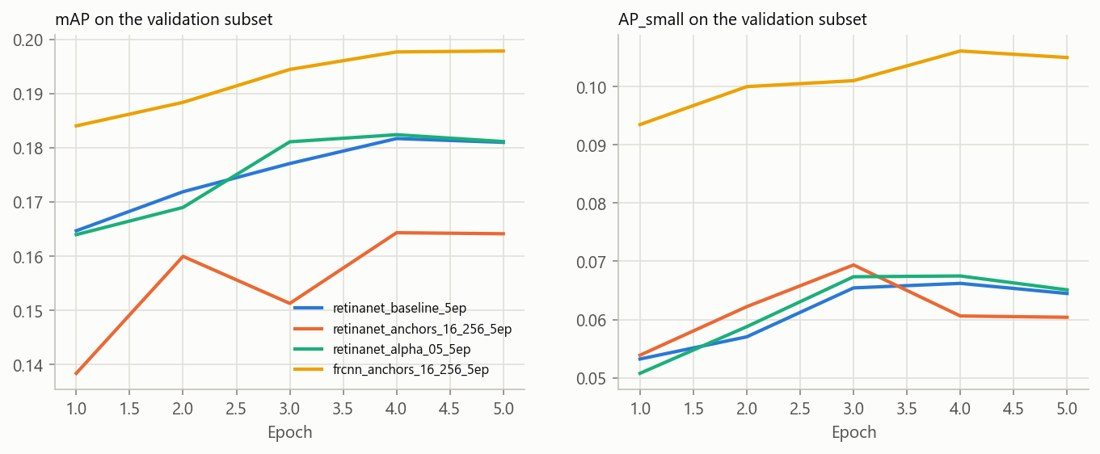

In [35]:
display(results_table([3])[RESULT_COLUMNS].round(4))
display(results_table([3])[["name"] + [f"AP_{name}" for name in CLASS_NAMES]].round(4))
retinanet_runs = [stage_dir(3) / name for name in results_table([3]).name] + [best_run([2])]
stage_dir(3).mkdir(parents=True, exist_ok=True)
plot_learning_curves(retinanet_runs, stage_dir(3) / "learning_curves.png")
show_saved_figure(stage_dir(3) / "learning_curves.png")

#### Results: RetinaNet
Baseline: mAP 0.1801, below the Faster R-CNN baseline (0.1941).
- **Small gain: focal alpha 0.5.** mAP 0.1811 (+0.001) and AP_small 0.0615 → 0.0645. This run is the RetinaNet member of the ensembles in section 6.
- **Did not work: anchors 16–256.** mAP 0.1628 (−0.017). AP50 rose (0.3471 → 0.3600) but AP75 fell (0.1663 → 0.1253): more objects are found, but the boxes are less precise. Training also took 94.8 instead of 46.5 minutes. The same anchors helped Faster R-CNN, whose second stage refines the boxes.

## 4. FCOS: one-stage anchor-free detection

Same protocol again. Model: torchvision `fcos_resnet50_fpn` with COCO v1 weights, only the final classification layer replaced. The torchvision reference also uses 0.01 for batch size 16, so the learning rate is again 0.00125.

**The default score threshold of 0.2 is lowered to the shared 0.05**, and the detection limit raised to 500. Otherwise FCOS would be compared on a shorter list of detections, which lowers AP.

## How assignment differs from the anchor-based models
Both anchor-based detectors decide positives by the **IoU between an object and a predefined box**:
- **RetinaNet:** an anchor is positive at IoU of at least 0.5 and background below 0.4; anchors in between are not used. Each object also claims its best anchor, even below 0.5.
- **Faster R-CNN:** the proposal network uses 0.7 and 0.3, then a second stage classifies the proposals.

So a small object can fail to match well simply because of anchor shapes and grid positions.

FCOS has no anchor shapes (torchvision's "anchor" here is only a stride-sized cell marking a location). A location on the feature map is positive for an object when all of these hold:
1. It is inside the object's box.
2. It is within `center_sampling_radius` x stride of the box centre.
3. Its longest distance to a box side is within that level's range: 0-64 px for P3, 64-128 px for P4 and so on.

If a location qualifies for several objects, it goes to the smallest one. It predicts the four distances to the box sides, and a centre-ness score down-weights predictions far from the centre.

Section 1 found that 96.5% of objects fall into P3 at long side 1333, so nearly all objects compete for the stride-8 grid. A location can predict only one object, which is the main risk in crowded frames.

**Experiments**
- **Centre sampling radius 1.0.** Radius 1.5 limits positives to 12 px around the centre on P3. Objects under 24 px are unaffected, because the box itself is the tighter limit, and a larger radius would not help them. A smaller radius of 8 px gives crowded objects fewer ambiguous locations, at the cost of fewer positives for objects over 16 px.
- **Long side 1024.** The same change as for Faster R-CNN, to compare how much each family depends on resolution.

In [36]:
def build_fcos(config):
    """COCO-pretrained FCOS with a new final classification layer for 8 classes."""
    model = fcos_resnet50_fpn(
        weights=FCOS_ResNet50_FPN_Weights.COCO_V1,
        min_size=round(config.long_side * 0.6),
        max_size=config.long_side,
        center_sampling_radius=config.center_sampling_radius,
        score_thresh=SCORE_THRESHOLD,
        detections_per_img=MAX_DETECTIONS,
    )
    pretrained = model.head.classification_head
    head = FCOSClassificationHead(model.backbone.out_channels, pretrained.num_anchors, NUM_CLASSES)
    head.conv.load_state_dict(pretrained.conv.state_dict())
    model.head.classification_head = head
    model.label_offset = 0
    return model


MODEL_BUILDERS["fcos_r50_fpn_v1"] = build_fcos

FCOS_BASELINE = Experiment(name=f"fcos_baseline_{TRIAL_EPOCHS}ep", change="Reference: torchvision defaults, long side 1333, batch 2, lr 0.00125", model="fcos_r50_fpn_v1", stage=4, lr=ONE_STAGE_LR, anchor_sizes=())
run_experiments([
    FCOS_BASELINE,
    replace(FCOS_BASELINE, name=f"fcos_radius_1_{TRIAL_EPOCHS}ep", center_sampling_radius=1.0, change="Centre sampling radius 1.0: fewer ambiguous positives in crowds"),
    replace(FCOS_BASELINE, name=f"fcos_long_1024_{TRIAL_EPOCHS}ep", long_side=1024, change="Long side 1024: same change as for Faster R-CNN"),
])

fcos_baseline_5ep {'mAP': 0.1888, 'AP50': 0.3752, 'AP_small': 0.0865, 'fps': 14.9077, 'train_minutes': 47.6054}
fcos_radius_1_5ep {'mAP': 0.1985, 'AP50': 0.3999, 'AP_small': 0.0925, 'fps': 14.8598, 'train_minutes': 49.5239}
fcos_long_1024_5ep {'mAP': 0.1586, 'AP50': 0.3183, 'AP_small': 0.0597, 'fps': 23.7102, 'train_minutes': 30.9778}


,name,model,change,long_side,batch_size,epochs,lr,anchor_sizes,focal_alpha,focal_gamma,center_sampling_radius,num_queries,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,fps,train_minutes,peak_vram_gb
8,fcos_baseline_5ep,fcos_r50_fpn_v1,"Reference: torchvision defaults, long side 133...",1333,2,5,0.0012,NaN,0.25,2.0,1.5,300,0.1888,0.3752,0.1695,0.0865,0.1690,0.3522,0.4146,14.9077,47.6054,3.4297
9,fcos_radius_1_5ep,fcos_r50_fpn_v1,Centre sampling radius 1.0: fewer ambiguous po...,1333,2,5,0.0012,NaN,0.25,2.0,1.0,300,0.1985,0.3999,0.1742,0.0925,0.1775,0.3638,0.4309,14.8598,49.5239,3.5508
10,fcos_long_1024_5ep,fcos_r50_fpn_v1,Long side 1024: same change as for Faster R-CNN,1024,2,5,0.0012,NaN,0.25,2.0,1.5,300,0.1586,0.3183,0.1412,0.0597,0.1397,0.3164,0.3699,23.7102,30.9778,2.5000


,name,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
8,fcos_baseline_5ep,0.2641,0.1476,0.3819,0.2370,0.1769,0.1908,0.0127,0.0998
9,fcos_radius_1_5ep,0.2677,0.1971,0.3831,0.2324,0.1775,0.2045,0.0087,0.1166
10,fcos_long_1024_5ep,0.2334,0.0748,0.3635,0.2173,0.1359,0.1568,0.0037,0.0836


learning_curves.png


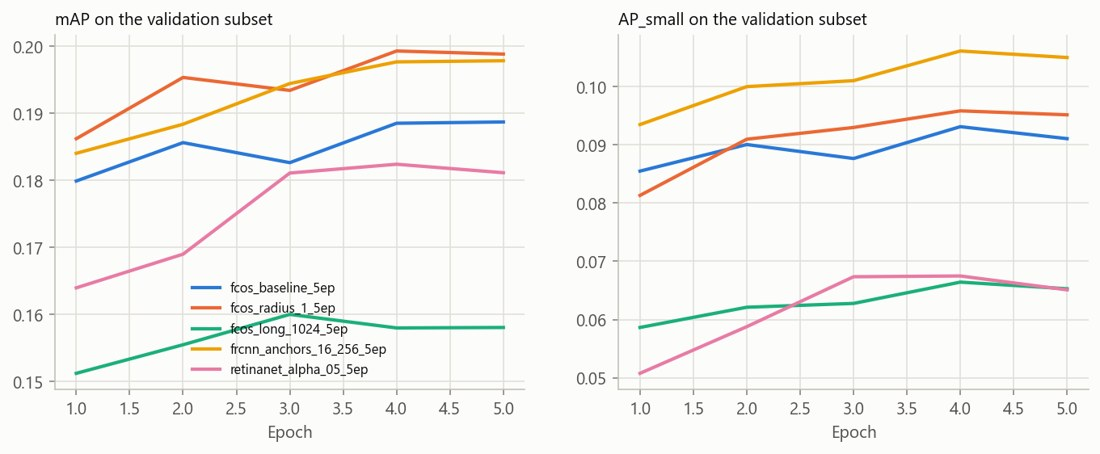

Share of objects found, by object size (best run of each family):


,frcnn_anchors_16_256_5ep,retinanet_alpha_05_5ep,fcos_radius_1_5ep
value,,,
under 16 px,0.032,0.026,0.018
16-32 px,0.382,0.281,0.335
32-96 px,0.572,0.531,0.543
96 px and over,0.772,0.811,0.788


In [37]:
display(results_table([4])[RESULT_COLUMNS].round(4))
display(results_table([4])[["name"] + [f"AP_{name}" for name in CLASS_NAMES]].round(4))
family_runs = [best_run([2]), best_run([3]), best_run([4])]
fcos_runs = [stage_dir(4) / name for name in results_table([4]).name]
plot_learning_curves(fcos_runs + family_runs[:2], stage_dir(4) / "learning_curves.png")
show_saved_figure(stage_dir(4) / "learning_curves.png")
print("Share of objects found, by object size (best run of each family):")
display(recall_comparison(family_runs, "size").round(3))

#### Results: FCOS
Baseline: mAP 0.1888.
- **Worked well: centre sampling radius 1.0.** mAP 0.1985 (+0.0097), the best single model of sections 2–5. AP_small 0.0865 → 0.0925 and AP_bicycle 0.148 → 0.197. Section 6 continues from this run.
- **Did not work: long side 1024.** mAP 0.1586 (−0.030), twice the loss of the same change for Faster R-CNN (−0.015).

## 5. RT-DETR: query-based detection

**Model:** `RTDetrForObjectDetection` from Hugging Face Transformers (Apache 2.0), with the COCO-only checkpoint `PekingU/rtdetr_r50vd` (Apache 2.0 on its model card). The ResNet-50 backbone is the same depth as the other families, though its weights and variant differ (ResNet-50-vd).

**How it differs:** there are no anchors and no NMS. The encoder scores every feature location, the best `num_queries` become decoder queries, and in training each object is matched to exactly one query by Hungarian matching. Denoising queries (noisy copies of the real boxes) stabilize that matching during training.

**The adapter below** gives RT-DETR the same interface as the torchvision models, so training and evaluation use the same code. It does these things for the model:
- **Resize and pad** to the long side and a multiple of 32. Images are scaled to [0, 1] with no mean and standard deviation, as the checkpoint's `preprocessor_config.json` specifies (`do_normalize: false`).
- **Loss in full precision.** The official code turns off mixed precision for the loss. Transformers computes the loss inside `forward`, so the adapter wraps it. Otherwise tiny normalized boxes would go through 16-bit IoU calculations.
- **Decoding.** Transformers' post-processing returns at most `num_queries` results. Here the same sigmoid and top-k over all query-class pairs are used, up to the shared limit of 500 and with the shared score threshold.

## Settings against the official configuration
| Setting | Official RT-DETR | Here | Why |
|---|---|---|---|
| Optimizer | AdamW, lr 1e-4, backbone 1e-5, weight decay 1e-4, clip 0.1 | same | Reference values |
| Epochs | 72 | 5 | Same budget as the CNN comparison runs |
| Learning-rate decay | none | near the starts of epochs 4 and 5 | Same schedule as the CNN comparison runs |
| Weight EMA | yes | no | Not used for the other families |
| Batch size | 16 | 2 | GPU memory; learning rate not scaled, since scaling is not standard for AdamW |
| Input size | 640 x 640, with multi-scale augmentation | long side 1333, flip only | section 1: 54% of objects are under 16 px at 640 and 8.5% at 1333 |

## Experiments
- **Long side 640,** the model's native size, to measure directly what resolution is worth for small objects.
- **500 queries.** Section 1: up to 180 objects in a frame and over 100 in 6.4% of validation frames, so 300 queries leave limited room in dense scenes. This also costs memory.

Denoising adds up to 2 queries per object, so a 180-object frame has 660 decoder queries at the default setting.

In [38]:
from transformers import RTDetrForObjectDetection

RT_DETR_CHECKPOINT = "PekingU/rtdetr_r50vd"

def in_full_precision(loss_function):
    """Run the loss outside autocast on 32-bit floats, as the official RT-DETR code does."""

    def wrapped(*args, **kwargs):
        cast = lambda v: v.float() if torch.is_tensor(v) and v.is_floating_point() else v
        with torch.amp.autocast("cuda", enabled=False):
            return loss_function(*[cast(v) for v in args], **{key: cast(v) for key, v in kwargs.items()})

    return wrapped

class RTDetrDetector(torch.nn.Module):
    """Gives RT-DETR the torchvision interface: a list of images in, boxes in original pixels out."""

    label_offset = 0

    def __init__(self, network, long_side):
        super().__init__()
        self.network, self.long_side = network, long_side

    def prepare_batch(self, images):
        """Resize to the long side and pad bottom and right. Returns pixels and per-image xyxy scales."""
        resized, scales = [], []
        for image in images:
            height, width = image.shape[-2:]
            scale = self.long_side / max(height, width)
            new_height, new_width = round(height * scale), round(width * scale)
            resized.append(torch.nn.functional.interpolate(image[None], size=(new_height, new_width), mode="bilinear", align_corners=False)[0])
            scales.append(image.new_tensor([new_width / width, new_height / height] * 2))
        pad_height = int(np.ceil(max(r.shape[-2] for r in resized) / 32)) * 32
        pad_width = int(np.ceil(max(r.shape[-1] for r in resized) / 32)) * 32
        pixels = images[0].new_zeros(len(images), 3, pad_height, pad_width)
        for position, image in enumerate(resized):
            pixels[position, :, : image.shape[-2], : image.shape[-1]] = image
        return pixels, scales

    @staticmethod
    def network_targets(targets, scales, size):
        """Pixel xyxy boxes to centre-size boxes relative to the padded image."""
        norm = targets[0]["boxes"].new_tensor([size[1], size[0], size[1], size[0]])
        return [
            {"class_labels": t["labels"], "boxes": box_convert(t["boxes"] * s, "xyxy", "cxcywh") / norm}
            for t, s in zip(targets, scales)
        ]

    @staticmethod
    def decode(logits, pred_boxes, images, scales, size):
        """Top detections per image, in original pixels, as torchvision detectors return them."""
        norm = logits.new_tensor([size[1], size[0], size[1], size[0]])
        scores_per_image = logits.sigmoid().flatten(1)
        boxes_per_image = box_convert(pred_boxes, "cxcywh", "xyxy") * norm
        outputs = []
        for scores, boxes, image, scale in zip(scores_per_image, boxes_per_image, images, scales):
            scores, index = scores.topk(min(MAX_DETECTIONS, scores.numel()))
            keep = scores > SCORE_THRESHOLD
            scores, index = scores[keep], index[keep]
            boxes = boxes[index // NUM_CLASSES] / scale
            boxes[:, [0, 2]] = boxes[:, [0, 2]].clamp(0, image.shape[-1])
            boxes[:, [1, 3]] = boxes[:, [1, 3]].clamp(0, image.shape[-2])
            outputs.append({"boxes": boxes, "labels": index % NUM_CLASSES, "scores": scores})
        return outputs

    def forward(self, images, targets=None):
        pixels, scales = self.prepare_batch(images)
        size = pixels.shape[-2:]
        if targets is not None:
            return {"detection_loss": self.network(pixel_values=pixels, labels=self.network_targets(targets, scales, size)).loss}
        outputs = self.network(pixel_values=pixels)
        return self.decode(outputs.logits, outputs.pred_boxes, images, scales, size)

def build_rt_detr(config):
    """COCO-pretrained RT-DETR with new class outputs. `ignore_mismatched_sizes` drops only the 80-class layers."""
    network = RTDetrForObjectDetection.from_pretrained(
        RT_DETR_CHECKPOINT,
        num_labels=NUM_CLASSES,
        num_queries=config.num_queries,
        ignore_mismatched_sizes=True,
    )
    assert network.config.anchor_image_size is None and network.config.eval_size is None, "anchors must follow the input size"
    network.loss_function = in_full_precision(network.loss_function)
    return RTDetrDetector(network, config.long_side)

MODEL_BUILDERS["rt_detr_r50vd"] = build_rt_detr

def check_rt_detr_adapter():
    """Boxes must survive the trip to network coordinates and back; low scores must be dropped."""
    detector = RTDetrDetector(None, long_side=1333)
    images = [torch.zeros(3, 1080, 1920), torch.zeros(3, 1530, 2720)]
    boxes = [torch.tensor([[10.0, 20.0, 110.0, 220.0]]), torch.tensor([[2600.0, 1400.0, 2700.0, 1500.0]])]
    targets = [{"boxes": b, "labels": torch.tensor([3])} for b in boxes]
    pixels, scales = detector.prepare_batch(images)
    size = pixels.shape[-2:]
    assert size[0] % 32 == 0 and size[1] % 32 == 0 and size[1] >= 1333 and max(size) < 1333 + 32, size
    network_boxes = torch.stack([t["boxes"] for t in detector.network_targets(targets, scales, size)])[:, 0]
    assert (network_boxes >= 0).all() and (network_boxes <= 1).all()
    logits = torch.full((2, 5, NUM_CLASSES), -10.0)
    logits[:, 0, 3] = 5.0
    pred_boxes = torch.zeros(2, 5, 4)
    pred_boxes[:, 0] = network_boxes
    outputs = detector.decode(logits, pred_boxes, images, scales, size)
    for output, expected in zip(outputs, boxes):
        assert len(output["boxes"]) == 1 and output["labels"].item() == 3, output
        assert torch.allclose(output["boxes"], expected, atol=0.01), (output["boxes"], expected)

    seen = {}
    half = torch.ones(2, dtype=torch.float16)
    in_full_precision(lambda value, other=None: seen.update(value=value.dtype, other=other.dtype))(half, other=half)
    assert seen == {"value": torch.float32, "other": torch.float32}, seen
    print(f"RT-DETR adapter correct: padded size {tuple(size)}, boxes recovered, loss inputs converted to 32-bit")

check_rt_detr_adapter()

c:\Users\marki\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RT-DETR adapter correct: padded size (768, 1344), boxes recovered, loss inputs converted to 32-bit


In [39]:
RT_DETR_BASELINE = Experiment(
    name=f"rtdetr_baseline_{TRIAL_EPOCHS}ep",
    change="Reference with the official optimizer, long side 1333, batch 2 and 300 queries",
    model="rt_detr_r50vd",
    stage=5,
    lr=1e-4,
    backbone_lr=1e-5,
    optimizer="adamw",
    clip_grad_norm=0.1,
    anchor_sizes=(),
)
run_experiments([
    RT_DETR_BASELINE,
    replace(RT_DETR_BASELINE, name=f"rtdetr_long_640_{TRIAL_EPOCHS}ep", long_side=640, change="Long side 640: the model's native input size"),
    replace(RT_DETR_BASELINE, name=f"rtdetr_queries_500_{TRIAL_EPOCHS}ep", num_queries=500, change="500 queries: more room for dense scenes"),
])

rtdetr_baseline_5ep {'mAP': 0.1429, 'AP50': 0.3194, 'AP_small': 0.0747, 'fps': 15.4431, 'train_minutes': 76.6268}
rtdetr_long_640_5ep {'mAP': 0.0807, 'AP50': 0.1837, 'AP_small': 0.0226, 'fps': 38.4203, 'train_minutes': 44.5473}
rtdetr_queries_500_5ep {'mAP': 0.1488, 'AP50': 0.331, 'AP_small': 0.0756, 'fps': 15.7188, 'train_minutes': 78.5353}


,name,model,change,long_side,batch_size,epochs,lr,anchor_sizes,focal_alpha,focal_gamma,center_sampling_radius,num_queries,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,fps,train_minutes,peak_vram_gb
1,frcnn_baseline_5ep,faster_rcnn_r50_fpn_v1,"Reference: torchvision defaults, long side 133...",1333,2,5,0.0025,32-64-128-256-512,0.25,2.0,1.5,300,0.1941,0.3970,0.1664,0.0924,0.1775,0.3584,0.3011,5.1871,47.9227,7.8574
2,frcnn_lr_005_5ep,faster_rcnn_r50_fpn_v1,Learning rate doubled to 0.005,1333,2,5,0.0050,32-64-128-256-512,0.25,2.0,1.5,300,0.1966,0.4004,0.1663,0.0935,0.1830,0.3634,0.3027,14.7820,63.1029,9.7324
3,frcnn_long_1024_5ep,faster_rcnn_r50_fpn_v1,"Long side 1024: faster, but objects are smaller",1024,2,5,0.0025,32-64-128-256-512,0.25,2.0,1.5,300,0.1791,0.3729,0.1522,0.0854,0.1588,0.3433,0.2925,22.3890,31.5984,6.8301
4,frcnn_anchors_16_256_5ep,faster_rcnn_r50_fpn_v1,Anchors 16-256: shape coverage 98.0% against 7...,1333,2,5,0.0025,16-32-64-128-256,0.25,2.0,1.5,300,0.1969,0.4163,0.1638,0.1016,0.1844,0.3463,0.3099,14.9693,72.2700,9.7324
5,retinanet_baseline_5ep,retinanet_r50_fpn_v1,"Reference: torchvision defaults, long side 133...",1333,2,5,0.0012,32-64-128-256-512,0.25,2.0,1.5,300,0.1801,0.3471,0.1663,0.0615,0.1648,0.3512,0.3429,15.5885,46.5204,7.7266
6,retinanet_anchors_16_256_5ep,retinanet_r50_fpn_v1,Anchors 16-256: IoU>=0.7 coverage 93.5% agains...,1333,2,5,0.0012,16-32-64-128-256,0.25,2.0,1.5,300,0.1628,0.3600,0.1253,0.0588,0.1523,0.2999,0.3655,15.4391,94.7631,6.7285
7,retinanet_alpha_05_5ep,retinanet_r50_fpn_v1,Focal alpha 0.5: more weight on positive ancho...,1333,2,5,0.0012,32-64-128-256-512,0.50,2.0,1.5,300,0.1811,0.3522,0.1675,0.0645,0.1647,0.3532,0.3309,15.6522,54.1679,6.7402
8,fcos_baseline_5ep,fcos_r50_fpn_v1,"Reference: torchvision defaults, long side 133...",1333,2,5,0.0012,NaN,0.25,2.0,1.5,300,0.1888,0.3752,0.1695,0.0865,0.1690,0.3522,0.4146,14.9077,47.6054,3.4297
9,fcos_radius_1_5ep,fcos_r50_fpn_v1,Centre sampling radius 1.0: fewer ambiguous po...,1333,2,5,0.0012,NaN,0.25,2.0,1.0,300,0.1985,0.3999,0.1742,0.0925,0.1775,0.3638,0.4309,14.8598,49.5239,3.5508
10,fcos_long_1024_5ep,fcos_r50_fpn_v1,Long side 1024: same change as for Faster R-CNN,1024,2,5,0.0012,NaN,0.25,2.0,1.5,300,0.1586,0.3183,0.1412,0.0597,0.1397,0.3164,0.3699,23.7102,30.9778,2.5000


,name,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
1,frcnn_baseline_5ep,0.2582,0.1593,0.3742,0.2075,0.2566,0.1953,0.0012,0.1009
2,frcnn_lr_005_5ep,0.2590,0.1727,0.3795,0.2152,0.2474,0.1873,0.0040,0.1081
3,frcnn_long_1024_5ep,0.2358,0.1480,0.3513,0.2056,0.2223,0.1728,0.0053,0.0918
4,frcnn_anchors_16_256_5ep,0.2605,0.1927,0.3785,0.2181,0.2191,0.1923,0.0011,0.1127
5,retinanet_baseline_5ep,0.2348,0.1397,0.3597,0.1989,0.2207,0.1805,0.0292,0.0770
6,retinanet_anchors_16_256_5ep,0.2307,0.1511,0.3378,0.1901,0.1293,0.1639,0.0073,0.0921
7,retinanet_alpha_05_5ep,0.2348,0.1397,0.3622,0.2062,0.2190,0.1896,0.0222,0.0750
8,fcos_baseline_5ep,0.2641,0.1476,0.3819,0.2370,0.1769,0.1908,0.0127,0.0998
9,fcos_radius_1_5ep,0.2677,0.1971,0.3831,0.2324,0.1775,0.2045,0.0087,0.1166
10,fcos_long_1024_5ep,0.2334,0.0748,0.3635,0.2173,0.1359,0.1568,0.0037,0.0836


learning_curves_epochs.png


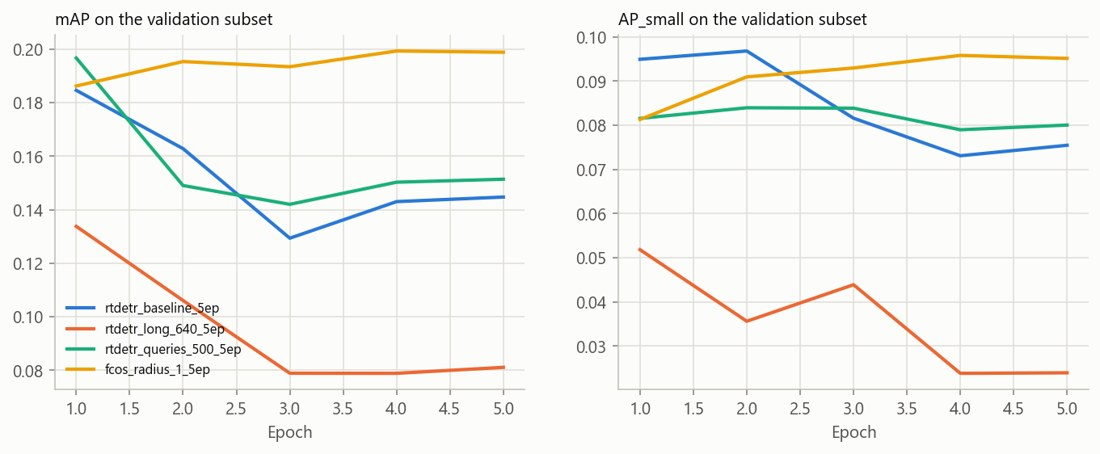

learning_curves_hours.png


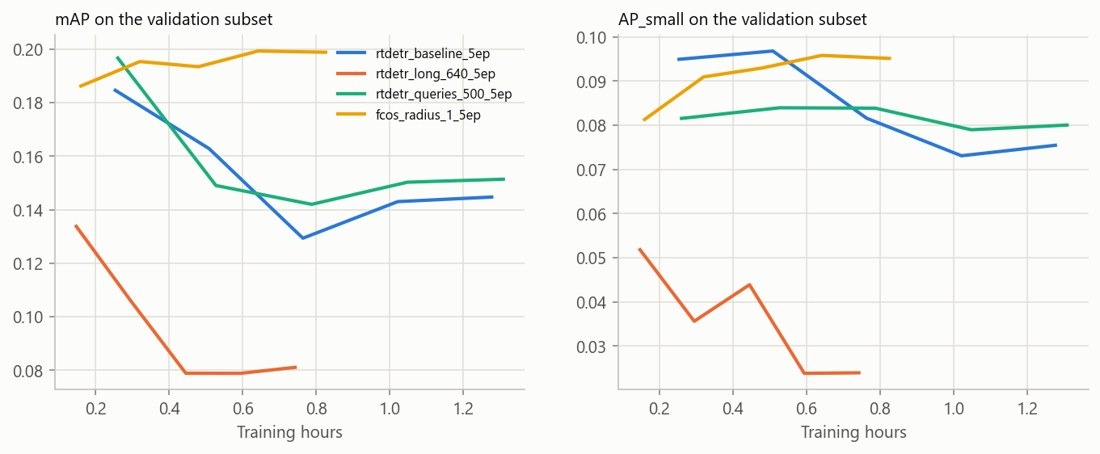

,epoch,lr,loss,val_subset_mAP,val_subset_AP50,val_subset_AP_small
0,0,0.0001,17.2470,0.1967,0.3998,0.0816
1,1,0.0001,13.9266,0.1490,0.3169,0.0840
2,2,0.0000,13.2710,0.1420,0.3159,0.0839
3,3,0.0000,12.5816,0.1503,0.3282,0.0790
4,4,0.0000,12.4280,0.1514,0.3283,0.0801


Share of objects found, by object size:


,rtdetr_queries_500_5ep,fcos_radius_1_5ep
value,,
under 16 px,0.0,0.018
16-32 px,0.0,0.335
32-96 px,0.0,0.543
96 px and over,0.0,0.788


Share of objects found, by number of objects in the frame:


,rtdetr_queries_500_5ep,fcos_radius_1_5ep
value,,
1-25 objects,0.0,0.154
26-50 objects,0.0,0.563
51-100 objects,0.0,0.565
over 100 objects,0.0,0.659


In [40]:
display(results_table([2, 3, 4, 5])[RESULT_COLUMNS].round(4))
display(results_table([2, 3, 4, 5])[["name"] + [f"AP_{name}" for name in CLASS_NAMES]].round(4))

rtdetr_runs = [stage_dir(5) / name for name in results_table([5]).name]
best_cnn = best_run([2, 3, 4])
plot_learning_curves(rtdetr_runs + [best_cnn], stage_dir(5) / "learning_curves_epochs.png")
plot_learning_curves(rtdetr_runs + [best_cnn], stage_dir(5) / "learning_curves_hours.png", by_hours=True)
show_saved_figure(stage_dir(5) / "learning_curves_epochs.png")
show_saved_figure(stage_dir(5) / "learning_curves_hours.png")

display(pd.read_csv(best_run([5]) / "history.csv")[["epoch", "lr", "loss", "val_subset_mAP", "val_subset_AP50", "val_subset_AP_small"]].round(4))

final_runs = [best_run([5]), best_cnn]
print("Share of objects found, by object size:")
display(recall_comparison(final_runs, "size").round(3))
print("Share of objects found, by number of objects in the frame:")
display(recall_comparison(final_runs, "density").round(3))

#### Results: RT-DETR
Baseline: mAP 0.1429, below every CNN baseline after the same 5 epochs.
- **Worked well: 500 queries.** mAP 0.1488 (+0.0059), with AR500 0.2936 → 0.2962.
- **Did not work: long side 640, the checkpoint's native size.** mAP 0.0807 (−0.062) and AP_small 0.0747 → 0.0226: at 640 most objects are too small for the model.

On its own RT-DETR stays below the CNN detectors, but its checkpoints add the most when fused with them (sections 6.9 and 6.10). The "share of objects found" tables count only boxes that score at least 0.5 (the failure-analysis operating point). RT-DETR's scores are lower than the CNN detectors' (section 6.10), so almost none of its boxes reach 0.5 and its share shows as 0; its mAP above does not depend on that cut.

## 6. Pipeline experiments and submission

The subsections are in the order they were run. Each one starts from the best model so far, and the code picks that model from the runs registered earlier in the notebook, so the order cannot change without changing which model a later step uses. The table sorts them by outcome instead. Each subsection writes to `outputs/<number>_<name>/`.

| Subsection | Experiment | Output folder | Outcome |
|---|---|---|---|
| 6.9 | Detector fusion: from one detector to four | `6.9_fusion` | **worked well**: 0.199 → 0.2322, LB 0.2570 |
| 6.10 | Mirrored views, a lower score threshold and an RT-DETR group | `6.10_ensemble` | **worked well**: 0.2322 → 0.2516, LB 0.3073 |
| 6.1 | FCOS box regression loss (DIoU) | `6.1_fcos_box_loss` | small gain: +0.0005 |
| 6.6 | Faster R-CNN crop training | `6.6_crop_training` | small gain: +0.0014, LB 0.2258; tiled inference did not work |
| 6.8 | Proposal diagnostics and a larger RPN budget | `6.8_rpn_budget` | diagnostic, then a small gain: +0.0011 |
| 6.5 | FCOS inference resolution and fine-tuning | `6.5_fcos_resolution` | did not work |
| 6.7 | Faster R-CNN crop training follow-up | `6.7_crop_followup` | did not work: −0.0030 |
| 6.2 | First test export: best single detector | `6.2_first_export` | first Kaggle file, LB 0.2046 |
| 6.3 | Inference speed recheck | `6.3_speed_recheck` | check |
| 6.4 | Video-grouped cross-validation | `6.4_cross_validation` | check |
| 6.11 | Selected ensemble | `submissions` | the selected file |

### 6.1 FCOS box regression loss

> **Outcome: small gain.** DIoU gave 0.1990 against 0.1985 with GIoU at radius 1.0 (+0.0005, a tie), and 0.1884 against 0.1888 at radius 1.5. The radius-1.0 DIoU model was kept: it is the FCOS member of every later ensemble.

The best trial so far is FCOS with centre sampling radius 1.0 (`fcos_radius_1_5ep`, section 4). Its AP50 is about twice its mAP (0.400 against 0.199, AP75 0.174): most objects are found, but the boxes are not tight enough for the stricter IoU thresholds. Most VisDrone objects are small, so a shift of a few pixels already costs a large part of the IoU.

**Loss modification: DIoU instead of GIoU for the box term.** torchvision's FCOS fixes the box loss to GIoU inside `FCOSHead.compute_loss`. DIoU (Zheng et al., *Distance-IoU Loss*, AAAI 2020; `torchvision.ops.distance_box_iou_loss`) is 1 - IoU plus the squared distance between the box centres, divided by the squared diagonal of the smallest box enclosing both. GIoU instead adds the empty share of that enclosing box.

For a predicted box of the right size but shifted, GIoU's extra term barely changes while the boxes overlap, and once one box contains the other it is zero. DIoU still pulls the centres together directly. That targets the AP75 gap above.

**Why not CIoU**, the paper's other loss, which adds an aspect-ratio term: torchvision's version divides by the predicted box height without a safety margin. FCOS predicts four ReLU distances, so a predicted box can have zero width or height, and CIoU then returns NaN or non-finite gradients. This was found in a test before training. DIoU has no such division, and `check_box_loss_head` confirms its value and gradient stay finite for a zero-size box.

`FCOSHeadWithBoxLoss` keeps torchvision's matching, classification loss, centre-ness loss and normalization, and recomputes only the box term. `check_box_loss_head` confirms that with GIoU it reproduces torchvision's value exactly, and that DIoU changes only the box term. The class reuses the existing head's layers, so its weights load exactly like the section 4 models.

**Runs (same 5-epoch protocol as every trial):**
- `fcos_radius_1_diou_5ep`: the best configuration with DIoU.
- `fcos_diou_5ep`: DIoU with the default radius 1.5.

**Ablation.** With `fcos_baseline_5ep` (radius 1.5, GIoU) and `fcos_radius_1_5ep` (radius 1.0, GIoU) from section 4, the four runs separate the effect of each change: radius 1.5 or 1.0, times GIoU or DIoU, everything else equal.

In [41]:
from torchvision.models.detection.fcos import FCOSHead
from torchvision.ops import distance_box_iou_loss, generalized_box_iou_loss

BOX_LOSSES = {"giou": generalized_box_iou_loss, "diou": distance_box_iou_loss}

class FCOSHeadWithBoxLoss(FCOSHead):
    """torchvision's FCOS head with a choice of IoU-based box loss.

    torchvision fixes GIoU inside `FCOSHead.compute_loss`. This head keeps that method for the
    classification and centre-ness terms and recomputes only the box term with the chosen loss,
    with torchvision's matching and normalization. It reuses the layers of an existing head.
    """

    def __init__(self, head, box_loss):
        torch.nn.Module.__init__(self)
        self.box_coder, self.classification_head, self.regression_head = head.box_coder, head.classification_head, head.regression_head
        self.box_loss = box_loss

    def box_regression_loss(self, targets, head_outputs, anchors, matched_idxs, box_loss):
        gt_boxes = torch.stack([
            t["boxes"][m.clip(min=0)] if len(t["labels"]) else t["boxes"].new_zeros((len(m), 4))
            for t, m in zip(targets, matched_idxs)
        ])
        foreground = torch.stack(matched_idxs) >= 0
        predicted = self.box_coder.decode(head_outputs["bbox_regression"], torch.stack(anchors))
        loss = BOX_LOSSES[box_loss](predicted[foreground].float(), gt_boxes[foreground].float(), reduction="sum")
        return loss / max(1, foreground.sum().item())

    def compute_loss(self, targets, head_outputs, anchors, matched_idxs):
        losses = super().compute_loss(targets, head_outputs, anchors, matched_idxs)
        losses["bbox_regression"] = self.box_regression_loss(targets, head_outputs, anchors, matched_idxs, self.box_loss)
        return losses

def check_box_loss_head():
    """With GIoU the recomputed box term must equal torchvision's; DIoU must change only the box term,
    and stay finite for a zero-size predicted box."""
    generator = torch.Generator().manual_seed(0)
    stock = FCOSHead(256, 1, NUM_CLASSES).eval()
    head = FCOSHeadWithBoxLoss(stock, "diou")
    grid = torch.stack(torch.meshgrid(torch.arange(16.0), torch.arange(16.0), indexing="xy"), dim=-1).reshape(-1, 2) * 8
    anchors = [torch.cat([grid, grid + 8], dim=1)] * 2
    centres = grid + 4
    with torch.no_grad():
        outputs = stock([torch.randn(2, 256, 16, 16, generator=generator)])
    targets, matched_idxs = [], []
    for _ in range(2):
        corner = torch.rand(6, 2, generator=generator) * 90
        boxes = torch.cat([corner, corner + 12 + torch.rand(6, 2, generator=generator) * 30], dim=1)
        inside = ((centres[:, None] > boxes[None, :, :2]) & (centres[:, None] < boxes[None, :, 2:])).all(dim=-1)
        matched_idxs.append(torch.where(inside.any(dim=1), inside.float().argmax(dim=1), torch.tensor(-1)))
        targets.append({"boxes": boxes, "labels": torch.randint(0, NUM_CLASSES, (6,), generator=generator)})
    reference = stock.compute_loss(targets, outputs, anchors, matched_idxs)
    giou = head.box_regression_loss(targets, outputs, anchors, matched_idxs, "giou")
    changed = head.compute_loss(targets, outputs, anchors, matched_idxs)
    assert all(torch.isfinite(v) for v in [*reference.values(), *changed.values()])
    assert torch.allclose(giou, reference["bbox_regression"], rtol=1e-5), (giou, reference["bbox_regression"])
    assert torch.equal(changed["classification"], reference["classification"]) and torch.equal(changed["bbox_ctrness"], reference["bbox_ctrness"])
    assert not torch.isclose(changed["bbox_regression"], reference["bbox_regression"]), "DIoU did not change the box term"
    assert set(head.state_dict()) == set(stock.state_dict()), "the head must load the same weights as torchvision's"
    zero_size = torch.tensor([[10.0, 10.0, 10.0, 10.0]], requires_grad=True)
    loss = distance_box_iou_loss(zero_size, torch.tensor([[8.0, 8.0, 14.0, 16.0]]), reduction="sum")
    loss.backward()
    assert torch.isfinite(loss) and torch.isfinite(zero_size.grad).all()
    print(f"box loss: torchvision GIoU {reference['bbox_regression']:.4f}, this head GIoU {giou:.4f}, DIoU {changed['bbox_regression']:.4f}; "
          f"other terms unchanged; DIoU finite for a zero-size box ({loss.item():.4f})")

check_box_loss_head()

def build_fcos_box_loss(config):
    """Section 4's FCOS, with the box loss chosen by `config.box_loss`."""
    model = build_fcos(config)
    model.head = FCOSHeadWithBoxLoss(model.head, config.box_loss)
    return model

MODEL_BUILDERS["fcos_r50_fpn_v1_box_loss"] = build_fcos_box_loss

FCOS_DIOU = replace(FCOS_BASELINE, name=f"fcos_diou_{TRIAL_EPOCHS}ep", model="fcos_r50_fpn_v1_box_loss", stage=6, box_loss="diou", change="DIoU box loss instead of GIoU, radius 1.5")
run_experiments([
    replace(FCOS_DIOU, name=f"fcos_radius_1_diou_{TRIAL_EPOCHS}ep", center_sampling_radius=1.0, change="DIoU box loss instead of GIoU, radius 1.0"),
    FCOS_DIOU,
])

box loss: torchvision GIoU 0.9976, this head GIoU 0.9976, DIoU 1.0732; other terms unchanged; DIoU finite for a zero-size box (1.0500)
fcos_radius_1_diou_5ep {'mAP': 0.199, 'AP50': 0.4012, 'AP_small': 0.093, 'fps': 15.0192, 'train_minutes': 47.3856}
fcos_diou_5ep {'mAP': 0.1884, 'AP50': 0.3742, 'AP_small': 0.0885, 'fps': 14.8842, 'train_minutes': 47.4481}


,name,change,center_sampling_radius,box_loss,long_side,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,fps,train_minutes
8,fcos_baseline_5ep,"Reference: torchvision defaults, long side 133...",1.5,giou,1333,0.1888,0.3752,0.1695,0.0865,0.1690,0.3522,0.4146,14.9077,47.6054
9,fcos_radius_1_5ep,Centre sampling radius 1.0: fewer ambiguous po...,1.0,giou,1333,0.1985,0.3999,0.1742,0.0925,0.1775,0.3638,0.4309,14.8598,49.5239
10,fcos_long_1024_5ep,Long side 1024: same change as for Faster R-CNN,1.5,giou,1024,0.1586,0.3183,0.1412,0.0597,0.1397,0.3164,0.3699,23.7102,30.9778
14,fcos_radius_1_diou_5ep,"DIoU box loss instead of GIoU, radius 1.0",1.0,diou,1333,0.1990,0.4012,0.1742,0.0930,0.1788,0.3609,0.4319,15.0192,47.3856
15,fcos_diou_5ep,"DIoU box loss instead of GIoU, radius 1.5",1.5,diou,1333,0.1884,0.3742,0.1688,0.0885,0.1693,0.3482,0.4182,14.8842,47.4481


,name,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
8,fcos_baseline_5ep,0.2641,0.1476,0.3819,0.2370,0.1769,0.1908,0.0127,0.0998
9,fcos_radius_1_5ep,0.2677,0.1971,0.3831,0.2324,0.1775,0.2045,0.0087,0.1166
10,fcos_long_1024_5ep,0.2334,0.0748,0.3635,0.2173,0.1359,0.1568,0.0037,0.0836
14,fcos_radius_1_diou_5ep,0.2669,0.1972,0.3844,0.2340,0.1790,0.2038,0.0130,0.1137
15,fcos_diou_5ep,0.2654,0.1491,0.3804,0.2327,0.1771,0.1921,0.0128,0.0974


AP75         AP_small             mAP        
box_loss                  diou    giou     diou    giou    diou    giou
center_sampling_radius                                                 
1.0                     0.1742  0.1742   0.0930  0.0925  0.1990  0.1985
1.5                     0.1688  0.1695   0.0885  0.0865  0.1884  0.1888

learning_curves.png


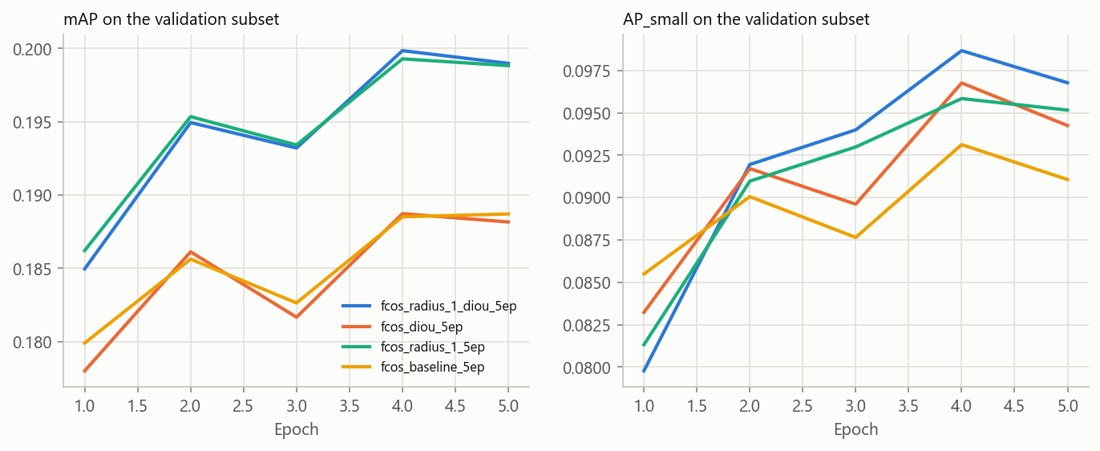

Share of objects found, by object size:


,fcos_radius_1_diou_5ep,fcos_radius_1_5ep
value,,
under 16 px,0.016,0.018
16-32 px,0.337,0.335
32-96 px,0.544,0.543
96 px and over,0.788,0.788


In [42]:
fcos_table = results_table([4, 6]).assign(box_loss=lambda t: t["box_loss"].fillna("giou") if "box_loss" in t else "giou")
display(fcos_table[["name", "change", "center_sampling_radius", "box_loss", "long_side", "mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500", "fps", "train_minutes"]].round(4))
display(fcos_table[["name"] + [f"AP_{name}" for name in CLASS_NAMES]].round(4))

ablation = fcos_table[fcos_table.long_side == 1333].pivot_table(index="center_sampling_radius", columns="box_loss", values=["mAP", "AP75", "AP_small"])
display(ablation.round(4))

box_loss_runs = [stage_dir(6) / name for name in results_table([6]).name]
plot_learning_curves(box_loss_runs + [stage_dir(4) / "fcos_radius_1_5ep", stage_dir(4) / "fcos_baseline_5ep"], stage_dir(6) / "learning_curves.png")
show_saved_figure(stage_dir(6) / "learning_curves.png")
print("Share of objects found, by object size:")
display(recall_comparison([best_run([6]), stage_dir(4) / "fcos_radius_1_5ep"], "size").round(3))

### 6.2 First test export: best single detector

> **Outcome: first Kaggle file.** `fcos_radius_1_diou_5ep`, the best single model on validation (0.1990), scored 0.2046 on the public leaderboard, below the public baseline of 0.2216.

The test images are used here only: no training, no tuning and no annotation. Predictions come from the finished run with the highest full-validation mAP, including the 12-epoch Faster R-CNN reference when available.

**Format:** one row per image in `test_images.csv`, in the same order, as `image_id,PredictionString`. Each prediction is `class score x y width height`: class 0-7, original-image pixels, top-left corner. The string is empty when nothing is detected, and at most 500 predictions are written per image, best first. Coordinates keep 2 decimals, because a rounding error of 0.5 px matters for an object only a few pixels wide.

`validate_submission` rereads the written file and checks every rule. When `sample_submission.csv` is in `data/`, it also checks that the ids and their order match it.

In [43]:
import tempfile

FIRST_EXPORT_DIR = OUTPUT_ROOT / OUTPUT_DIRS[7]
TEST_TABLE_PATH = DATA_ROOT / "test_images.csv"
SAMPLE_SUBMISSION_PATH = DATA_ROOT / "sample_submission.csv"


class TestImages:
    """Unmodified test images, in the order of `test_images.csv`. They have no annotations."""

    def __init__(self, table):
        self.table = table

    def __getitem__(self, index):
        row = self.table.iloc[index]
        with Image.open(DATA_ROOT / row["file_name"]) as image:
            assert image.size == (row["width"], row["height"]), row["image_id"]
            pixels = np.array(image.convert("RGB"))
        return torch.from_numpy(pixels).permute(2, 0, 1).float() / 255, {"image_id": row["image_id"]}


def prediction_string(output, label_offset):
    """One image's predictions as text, best score first, with competition class IDs."""
    order = output["scores"].argsort(descending=True)[:MAX_DETECTIONS]
    parts = []
    for box, label, score in zip(output["boxes"][order].tolist(), output["labels"][order].tolist(), output["scores"][order].tolist()):
        x, y, width, height = round(box[0], 2), round(box[1], 2), round(box[2] - box[0], 2), round(box[3] - box[1], 2)
        if width > 0 and height > 0:
            parts.append(f"{label - label_offset} {score:.5f} {x:.2f} {y:.2f} {width:.2f} {height:.2f}")
    return " ".join(parts)


def validate_submission(path, table=None):
    """Raise an error at the first broken rule; return a summary when the file is valid."""
    table = pd.read_csv(TEST_TABLE_PATH) if table is None else table
    with open(path, encoding="utf-8", newline="") as file:
        rows = list(csv.reader(file))
    assert rows and rows[0] == ["image_id", "PredictionString"], f"bad header: {rows[:1]}"
    rows = rows[1:]
    assert [row[0] for row in rows] == table.image_id.tolist(), "image ids differ from test_images.csv (missing, repeated or reordered)"
    if SAMPLE_SUBMISSION_PATH.exists():
        sample = pd.read_csv(SAMPLE_SUBMISSION_PATH)
        assert sample.columns.tolist() == ["image_id", "PredictionString"], sample.columns.tolist()
        assert [row[0] for row in rows] == sample.image_id.tolist(), "image ids differ from sample_submission.csv"
    counts = []
    for row, width, height in zip(rows, table.width, table.height):
        assert len(row) == 2, f"{row[0]}: expected 2 columns"
        tokens = row[1].split()
        assert len(tokens) % 6 == 0, f"{row[0]}: predictions need 6 values each"
        assert len(tokens) / 6 <= MAX_DETECTIONS, f"{row[0]}: over {MAX_DETECTIONS} predictions"
        counts.append(len(tokens) // 6)
        for start in range(0, len(tokens), 6):
            label = tokens[start]
            score, x, y, w, h = map(float, tokens[start + 1 : start + 6])
            assert label.isdigit() and 0 <= int(label) < NUM_CLASSES, f"{row[0]}: bad class {label}"
            assert 0 <= score <= 1, f"{row[0]}: bad score {score}"
            assert w > 0 and h > 0 and x >= 0 and y >= 0, f"{row[0]}: bad box {x, y, w, h}"
            assert x + w <= width + 0.02 and y + h <= height + 0.02, f"{row[0]}: box outside the image"
    counts = np.array(counts)
    return {"images": len(rows), "predictions": int(counts.sum()), "per_image_mean": float(counts.mean()), "per_image_max": int(counts.max()), "images_without_predictions": int((counts == 0).sum())}


def check_submission_tools():
    """The string builder must follow the format, and the validator must refuse each kind of error."""
    table = pd.DataFrame({"image_id": ["clip_001_0000001", "clip_001_0000002"], "width": [1920, 1920], "height": [1080, 1080]})
    output = {"boxes": torch.tensor([[1366.0, 580.0, 1392.0, 624.0], [10.0, 10.0, 20.0, 20.0]]), "labels": torch.tensor([3, 1]), "scores": torch.tensor([0.91, 0.95])}
    assert prediction_string(output, 1) == "0 0.95000 10.00 10.00 10.00 10.00 2 0.91000 1366.00 580.00 26.00 44.00", prediction_string(output, 1)
    good = "image_id,PredictionString\r\nclip_001_0000001,2 0.91 1366 580 26 44\r\nclip_001_0000002,\r\n"
    broken = {
        "missing image": "image_id,PredictionString\r\nclip_001_0000001,\r\n",
        "repeated image": "image_id,PredictionString\r\nclip_001_0000001,\r\nclip_001_0000001,\r\n",
        "class 8": good.replace("2 0.91", "8 0.91"),
        "score above 1": good.replace("0.91", "1.91"),
        "box outside": good.replace("1366", "1900"),
        "incomplete prediction": good.replace(" 44", ""),
        "wrong header": good.replace("PredictionString", "prediction"),
    }
    with tempfile.TemporaryDirectory() as folder:
        path = Path(folder) / "submission.csv"
        path.write_text(good, encoding="utf-8", newline="")
        assert validate_submission(path, table)["predictions"] == 1
        for name, text in broken.items():
            path.write_text(text, encoding="utf-8", newline="")
            try:
                validate_submission(path, table)
            except AssertionError:
                continue
            raise RuntimeError(f"the validator accepted a file with: {name}")
    print(f"submission tools correct: valid file accepted, {len(broken)} broken files refused")


check_submission_tools()

submission tools correct: valid file accepted, 7 broken files refused


In [44]:
def load_finished_model(run_dir):
    config = EXPERIMENT_REGISTRY[run_dir.name]
    model = MODEL_BUILDERS[config.model](config)
    model.load_state_dict(torch.load(run_dir / "final.pt", map_location="cpu"))
    return model.to(DEVICE).eval()


@torch.inference_mode()
def write_submission(model, path, batch_size=2):
    """Predict every test image and write the file. A partial file never replaces a finished one."""
    table = pd.read_csv(TEST_TABLE_PATH)
    temporary = path.with_suffix(".tmp")
    with open(temporary, "w", encoding="utf-8", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(["image_id", "PredictionString"])
        for images, targets in iterate_batches(TestImages(table), range(len(table)), batch_size):
            outputs = model([image.to(DEVICE) for image in images])
            for target, output in zip(targets, outputs):
                writer.writerow([target["image_id"], prediction_string(output, model.label_offset)])
    temporary.replace(path)


FINAL_RUN = best_run([2, 3, 4, 5, 6], include_reference=True)
SUBMISSION_PATH = FIRST_EXPORT_DIR / f"submission_{FINAL_RUN.name}.csv"
print("Predictions from:", FINAL_RUN.name)
FIRST_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
if not SUBMISSION_PATH.exists():
    final_model = load_finished_model(FINAL_RUN)
    write_submission(final_model, SUBMISSION_PATH)
    del final_model
    torch.cuda.empty_cache()
print(validate_submission(SUBMISSION_PATH))

Predictions from: fcos_radius_1_diou_5ep
{'images': 3811, 'predictions': 1905500, 'per_image_mean': 500.0, 'per_image_max': 500, 'images_without_predictions': 0}


### 6.3 Inference speed recheck

> **Outcome: check.** The 5.2 fps logged for the 5-epoch baseline came from a GPU slowdown. Measured again it runs at 15.0 fps, the same as the 12-epoch run (14.9 fps).
The 5-epoch Faster R-CNN baseline's speed was measured during a GPU slowdown (5.2 fps, against 15.2 fps for the 12-epoch run with the same architecture). Both baselines are measured again here under the same conditions: after all training, with no other model in GPU memory. `gpu_memory_in_use_gb` is the whole GPU's memory in use just before each model is loaded, including other applications.

In [45]:
import gc

FPS_RECHECK_PATH = OUTPUT_ROOT / "6.3_speed_recheck" / "fps_recheck.csv"
if not FPS_RECHECK_PATH.exists():
    FPS_RECHECK_PATH.parent.mkdir(parents=True, exist_ok=True)
    rows = []
    for run_dir in (FRCNN_DIR / REFERENCE_BASELINE.name, FRCNN_DIR / BASELINE.name):
        gc.collect()
        torch.cuda.empty_cache()
        free, total = torch.cuda.mem_get_info()
        model = load_finished_model(run_dir)
        rows.append(
            {
                "name": run_dir.name,
                "fps_logged": json.loads((run_dir / "result.json").read_text())["fps"],
                "fps_recheck": measure_speed(model, val_frames),
                "gpu_memory_in_use_gb": (total - free) / 1024**3,
            }
        )
        del model
    gc.collect()
    torch.cuda.empty_cache()
    pd.DataFrame(rows).to_csv(FPS_RECHECK_PATH, index=False)
fps_recheck = pd.read_csv(FPS_RECHECK_PATH)
display(fps_recheck.round(2))

,name,fps_logged,fps_recheck,gpu_memory_in_use_gb
0,frcnn_baseline,15.16,14.93,2.82
1,frcnn_baseline_5ep,5.19,14.96,2.82


### 6.4 Video-grouped cross-validation and out-of-fold evaluation

> **Outcome: check.** Out-of-fold mAP is 0.193 ± 0.031 across the five folds (0.159 to 0.234) and 0.186 pooled. The fold models score 0.190 on the official validation set, against 0.199 for the final model, which saw all training videos.

The model selected in section 6.2 is trained five more times with the same settings, each time without one fold. A fold is a group of source videos (section 1, `cv_folds.json`), so frames of one scene are never on both sides. The official validation set is not part of any fold.

- **Per fold:** each fold model predicts the frames of its held-out videos, which it has never seen. Their scores (`oof_*`) show how much the result depends on which videos are held out. The mean and standard deviation summarize the five.
- **Pooled out-of-fold:** the held-out predictions of all five folds together cover the selected every-fifth-frame subset once, each scored frame predicted by the one model that did not train on its video. They are scored together as one evaluation.
- **Official validation:** each fold model is also scored on the official validation set (`official_val_mAP`). Every one of them saw less training data than the final model, so they are expected to be slightly lower.

**Scored frames:** every 5th frame of each held-out video, the same stride as one training epoch. FCOS keeps 500 detections per image, so scoring all 24,201 frames would hold about 12 million detections in memory. Neighbouring frames at 25 fps are nearly identical, so the 5-frame stride costs little information. The coverage check below confirms that the folds' scored frames are disjoint and together are exactly every 5th training frame.

Training uses the same protocol as every trial: 5 epochs, every 5th frame per epoch with a shifting offset, and the same learning rate schedule, so each fold sees about 80% of the frames per epoch.

In [46]:
CV_DIR = OUTPUT_ROOT / "6.4_cross_validation"
CV_STAGE = 8
OOF_STRIDE = TRAIN_FRAME_STRIDE
CV_BASE = EXPERIMENT_REGISTRY[FINAL_RUN.name]
cv_folds = json.loads((DATASET_DIR / "cv_folds.json").read_text())["by_source"]
N_FOLDS = len(set(cv_folds.values()))

def scored_frames(frames):
    return [f for f in frames if f.frame_index % OOF_STRIDE == 0]

def fold_config(fold):
    config = replace(CV_BASE, name=f"cv_fold{fold}_{CV_BASE.name}", stage=CV_STAGE, change=f"Fold {fold} of {N_FOLDS}: {CV_BASE.name} without this fold's source videos")
    EXPERIMENT_REGISTRY[config.name] = config
    return config

def check_cross_validation_setup():
    """Before any training: the folds are disjoint by source video, and their scored frames cover the training set once."""
    scored_ids = []
    for fold in range(N_FOLDS):
        fit, held_out = split_by_fold(train_frames, cv_folds, fold)
        assert not {source_video(f.clip) for f in fit} & {source_video(f.clip) for f in held_out}, fold
        assert len(fit) + len(held_out) == len(train_frames), fold
        scored_ids += [f.image_id for f in scored_frames(held_out)]
    assert len(scored_ids) == len(set(scored_ids)) and set(scored_ids) == {f.image_id for f in scored_frames(train_frames)}
    sample = [f for f in scored_frames(train_frames) if len(f.boxes) and len(f.ignore)][::300]
    perfect = evaluate_detections([d for f in sample for d in frame_to_perfect_detections(f)], [f.image_id for f in sample], split="train")
    assert perfect["AP50"] > 0.99, perfect
    print(f"cross-validation: {N_FOLDS} folds by source video, {len(scored_ids)} scored frames cover every {OOF_STRIDE}th training frame once; perfect boxes on the training split give AP50 {perfect['AP50']:.4f}")

check_cross_validation_setup()
print("Cross-validated configuration:", CV_BASE.name)

for fold in range(N_FOLDS):
    config = fold_config(fold)
    fit, held_out = split_by_fold(train_frames, cv_folds, fold)
    train_experiment(config, frames=fit, output_root=CV_DIR)
    oof_path = CV_DIR / config.name / "oof_detections.json"
    if not oof_path.exists():
        model = load_finished_model(CV_DIR / config.name)
        oof_path.write_text(json.dumps(predict(model, scored_frames(held_out))))
        del model
        torch.cuda.empty_cache()
    print(f"fold {fold}: trained on {len(fit)} frames, held-out predictions saved", flush=True)

creating index...
index created!
cross-validation: 5 folds by source video, 4822 scored frames cover every 5th training frame once; perfect boxes on the training split give AP50 1.0000
Cross-validated configuration: fcos_radius_1_diou_5ep
fold 0: trained on 19359 frames, held-out predictions saved
fold 1: trained on 19108 frames, held-out predictions saved
fold 2: trained on 19497 frames, held-out predictions saved
fold 3: trained on 19373 frames, held-out predictions saved
fold 4: trained on 19467 frames, held-out predictions saved


In [47]:
CV_SUMMARY_PATH = CV_DIR / "cv_summary.csv"
OOF_METRICS = ("mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large")
if not CV_SUMMARY_PATH.exists():
    rows, pooled_detections, pooled_ids = [], [], []
    for fold in range(N_FOLDS):
        config = fold_config(fold)
        fit, held_out = split_by_fold(train_frames, cv_folds, fold)
        ids = [f.image_id for f in scored_frames(held_out)]
        detections = json.loads((CV_DIR / config.name / "oof_detections.json").read_text())
        held_out_metrics = evaluate_detections(detections, ids, split="train")
        rows.append({
            "fold": str(fold),
            "source_videos": len({source_video(f.clip) for f in held_out}),
            "train_frames": len(fit),
            "scored_frames": len(ids),
            **{f"oof_{key}": held_out_metrics[key] for key in OOF_METRICS},
            "official_val_mAP": json.loads((CV_DIR / config.name / "result.json").read_text())["mAP"],
        })
        pooled_detections += detections
        pooled_ids += ids
    pooled = evaluate_detections(pooled_detections, pooled_ids, split="train")
    del pooled_detections
    summary = pd.DataFrame(rows)
    metric_columns = [f"oof_{key}" for key in OOF_METRICS] + ["official_val_mAP"]
    summary = pd.concat([
        summary,
        pd.DataFrame([
            {"fold": "mean", **summary[metric_columns].mean()},
            {"fold": "std", **summary[metric_columns].std()},
            {"fold": "pooled out-of-fold", "scored_frames": len(pooled_ids), **{f"oof_{key}": pooled[key] for key in OOF_METRICS}},
        ]),
    ], ignore_index=True)
    summary.to_csv(CV_SUMMARY_PATH, index=False)
cv_summary = pd.read_csv(CV_SUMMARY_PATH)
display(cv_summary.round(4))
print(f"Final model {FINAL_RUN.name}, trained on all training videos: official validation mAP {json.loads((FINAL_RUN / 'result.json').read_text())['mAP']:.4f}")

,fold,source_videos,train_frames,scored_frames,oof_mAP,oof_AP50,oof_AP75,oof_AP_small,oof_AP_medium,oof_AP_large,official_val_mAP
0,0,12.0,19359.0,963.0,0.2340,0.4542,0.2180,0.0627,0.2528,0.3402,0.1849
1,1,7.0,19108.0,1017.0,0.1644,0.3391,0.1372,0.0542,0.1644,0.3090,0.1993
2,2,10.0,19497.0,937.0,0.2054,0.3987,0.1888,0.0872,0.2102,0.3626,0.1864
3,3,10.0,19373.0,962.0,0.1589,0.3161,0.1413,0.0860,0.1483,0.3281,0.1880
4,4,9.0,19467.0,943.0,0.2006,0.3960,0.1776,0.0641,0.1347,0.3397,0.1900
5,mean,NaN,NaN,NaN,0.1927,0.3808,0.1726,0.0708,0.1821,0.3359,0.1897
6,std,NaN,NaN,NaN,0.0311,0.0544,0.0338,0.0149,0.0487,0.0196,0.0057
7,pooled out-of-fold,NaN,NaN,4822.0,0.1863,0.3709,0.1660,0.0562,0.1730,0.3451,NaN


Final model fcos_radius_1_diou_5ep, trained on all training videos: official validation mAP 0.1990


### 6.5 FCOS inference resolution and fine-tuning

> **Outcome: did not work.** Long side 1600 raised validation mAP by only 0.0012, under the +0.005 bar, so the fine-tune ran. Both extra epochs lost mAP (0.1972 and 0.1956 against 0.1990). The long-side-1600 file was still the best validation candidate and was submitted: it scored 0.1876 on the leaderboard, against 0.2046.

The section 6.2 test file (`fcos_radius_1_diou_5ep`) scored 0.2046 on the public leaderboard, below the public baseline of 0.2216. That score is only the reason for this stage. Every comparison below uses the official validation set, and leaderboard scores are not used to choose between candidates.

Two inexpensive options, with no new data, models or weights:

1. **Higher inference resolution.** The same weights, with the long side at 1600 instead of the training value 1333 (short-side limit 960 instead of 800, the same 0.6 ratio as in training). Small objects are the weakest group (AP_small 0.093). Most validation images are larger than 1333 and are shrunk, one clip from 3840×2160, so a larger input keeps more of their pixels. The score threshold, NMS and the 500-detection cap stay unchanged. A gain counts as clear only if full-validation mAP rises by at least 0.005. This threshold is fixed before the result is seen. For scale, the DIoU change (+0.0005) was a tie.
2. **Short fine-tune**, run only if option 1 gives no clear gain. Up to two extra epochs from the saved weights:
   - at the training resolution;
   - with a fresh SGD optimizer at one tenth of the training learning rate (0.000125, the rate of epoch 4 in the original schedule), held constant after the usual 500-iteration warm-up;
   - with the same loss and all other settings.

   Each extra epoch is saved as its own run. Frame selection continues the stride-5 cycle. Training epoch e uses the frames with (frame_index + e) % 5 == 0, so the five original epochs used every offset once and saw every training frame exactly once. The extra epochs use the next offsets (5 and 6, which select the same frames as epochs 1 and 2) with new flips and a new order. They give a second pass over 40% of the frames, not new frames.

The final candidate is the one with the highest full official-validation mAP. A new test file is written only if that candidate is not the section 6.2 model at its original resolution.

In [48]:
FCOS_RESOLUTION_DIR = stage_dir(9)
FCOS_RESOLUTION_DIR.mkdir(parents=True, exist_ok=True)
BASE_RUN = stage_dir(6) / "fcos_radius_1_diou_5ep"
TRAIN_LONG_SIDE = EXPERIMENT_REGISTRY[BASE_RUN.name].long_side
HIGHER_LONG_SIDE = 1600
CLEAR_GAIN = 0.005
METRICS = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]
RESOLUTION_PATH = FCOS_RESOLUTION_DIR / "inference_resolution.csv"

def set_inference_size(model, long_side):
    """Change only how the model resizes its input; weights, score threshold, NMS and the cap stay the same."""
    model.transform.min_size = (round(long_side * 0.6),)
    model.transform.max_size = long_side
    return model

def smoke_test(model, long_side, count=8):
    """Peak GPU memory when predicting the largest validation images at this resolution."""
    largest = sorted(val_frames, key=lambda f: f.width * f.height)[-count:]
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    predict(set_inference_size(model, long_side), largest)
    peak, total = torch.cuda.max_memory_allocated() / 1024**3, torch.cuda.get_device_properties(0).total_memory / 1024**3
    assert peak < 0.8 * total, f"long side {long_side} needs {peak:.1f} of {total:.1f} GB"
    print(f"smoke test: long side {long_side} on the {count} largest validation images, peak GPU memory {peak:.2f} of {total:.1f} GB")

if not RESOLUTION_PATH.exists():
    model = load_finished_model(BASE_RUN)
    assert model.transform.max_size == TRAIN_LONG_SIDE and model.transform.min_size == (round(TRAIN_LONG_SIDE * 0.6),)
    smoke_test(model, HIGHER_LONG_SIDE)
    rows = []
    for long_side in (TRAIN_LONG_SIDE, HIGHER_LONG_SIDE):
        set_inference_size(model, long_side)
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        metrics = evaluate_detections(predict(model, val_frames))
        rows.append({"long_side": long_side, **{key: metrics[key] for key in METRICS},
                     "peak_vram_gb": torch.cuda.max_memory_allocated() / 1024**3, "fps": measure_speed(model, val_frames)})
        print(f"long side {long_side}: full validation mAP {metrics['mAP']:.4f}, AP_small {metrics['AP_small']:.4f}", flush=True)
    del model
    torch.cuda.empty_cache()
    logged = json.loads((BASE_RUN / "result.json").read_text())["mAP"]
    assert abs(rows[0]["mAP"] - logged) < 0.001, (rows[0]["mAP"], logged)
    pd.DataFrame(rows).to_csv(RESOLUTION_PATH, index=False)

resolution = pd.read_csv(RESOLUTION_PATH).set_index("long_side")
display(resolution.round(4))
change = resolution.loc[HIGHER_LONG_SIDE] - resolution.loc[TRAIN_LONG_SIDE]
RUN_FINE_TUNE = change["mAP"] < CLEAR_GAIN
print(f"long side {HIGHER_LONG_SIDE} against {TRAIN_LONG_SIDE}: mAP {change['mAP']:+.4f}, AP_small {change['AP_small']:+.4f}; "
      + ("no clear gain, so the fine-tune runs" if RUN_FINE_TUNE else "clear gain, so no fine-tune"))

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,peak_vram_gb,fps
long_side,,,,,,,,
1333,0.1990,0.4012,0.1742,0.0930,0.1788,0.3609,0.8546,15.0483
1600,0.2002,0.4084,0.1714,0.1006,0.1889,0.3535,1.0967,11.4365


long side 1600 against 1333: mAP +0.0012, AP_small +0.0076; no clear gain, so the fine-tune runs


In [49]:
FINE_TUNE_EPOCHS = 2
fine_tune_runs = []
if RUN_FINE_TUNE:
    base_config = EXPERIMENT_REGISTRY[BASE_RUN.name]
    start = BASE_RUN / "final.pt"
    for extra in range(1, FINE_TUNE_EPOCHS + 1):
        offset = base_config.epochs + extra - 1
        config = replace(
            base_config, name=f"{BASE_RUN.name}_ft{extra}", stage=9, epochs=1, lr=base_config.lr * 0.1, lr_decay_epochs=(),
            init_weights=start.relative_to(PROJECT_ROOT).as_posix(), epoch_offset=offset,
            change=f"Extra epoch {extra} from {start.parent.name}: fresh SGD at lr/10, frame offset {offset} (= {offset % TRAIN_FRAME_STRIDE})",
        )
        run_experiments([config])
        fine_tune_runs.append(stage_dir(9) / config.name)
        start = fine_tune_runs[-1] / "final.pt"
    display(pd.concat([pd.read_csv(run / "history.csv").assign(run=run.name) for run in fine_tune_runs])[["run", "lr", "loss", "val_subset_mAP", "val_subset_AP_small"]].round(4))

fcos_radius_1_diou_5ep_ft1 {'mAP': 0.1972, 'AP50': 0.3995, 'AP_small': 0.0901, 'fps': 14.7592, 'train_minutes': 9.488}
fcos_radius_1_diou_5ep_ft2 {'mAP': 0.1956, 'AP50': 0.3966, 'AP_small': 0.091, 'fps': 14.8096, 'train_minutes': 9.5046}


,run,lr,loss,val_subset_mAP,val_subset_AP_small
0,fcos_radius_1_diou_5ep_ft1,0.0001,1.0200,0.1970,0.0932
0,fcos_radius_1_diou_5ep_ft2,0.0001,1.0158,0.1965,0.0930


In [50]:
rows = [{"run": BASE_RUN.name, "long_side": side, **resolution.loc[side, METRICS]} for side in resolution.index]
for run in fine_tune_runs:
    result = json.loads((run / "result.json").read_text())
    rows.append({"run": run.name, "long_side": TRAIN_LONG_SIDE, **{key: result[key] for key in METRICS}})
candidates = pd.DataFrame(rows)
candidates.to_csv(FCOS_RESOLUTION_DIR / "candidates.csv", index=False)
display(candidates.round(4))

best = candidates.sort_values("mAP").iloc[-1]
if best.run == BASE_RUN.name and best.long_side == TRAIN_LONG_SIDE:
    FINAL_SUBMISSION_PATH = SUBMISSION_PATH
    print("No candidate beats the section 6.2 model; the section 6.2 file stays the final submission.")
else:
    FINAL_SUBMISSION_PATH = FCOS_RESOLUTION_DIR / f"submission_{best.run}_long{int(best.long_side)}.csv"
    if not FINAL_SUBMISSION_PATH.exists():
        run_dir = BASE_RUN if best.run == BASE_RUN.name else FCOS_RESOLUTION_DIR / best.run
        final_model = set_inference_size(load_finished_model(run_dir), int(best.long_side))
        write_submission(final_model, FINAL_SUBMISSION_PATH)
        del final_model
        torch.cuda.empty_cache()
print(f"Final candidate: {best.run} at long side {int(best.long_side)}, validation mAP {best.mAP:.4f}, AP_small {best.AP_small:.4f}")
print("File:", FINAL_SUBMISSION_PATH)
print(validate_submission(FINAL_SUBMISSION_PATH))

,run,long_side,mAP,AP50,AP75,AP_small,AP_medium,AP_large
0,fcos_radius_1_diou_5ep,1333,0.1990,0.4012,0.1742,0.0930,0.1788,0.3609
1,fcos_radius_1_diou_5ep,1600,0.2002,0.4084,0.1714,0.1006,0.1889,0.3535
2,fcos_radius_1_diou_5ep_ft1,1333,0.1972,0.3995,0.1712,0.0901,0.1769,0.3577
3,fcos_radius_1_diou_5ep_ft2,1333,0.1956,0.3966,0.1701,0.0910,0.1776,0.3548


Final candidate: fcos_radius_1_diou_5ep at long side 1600, validation mAP 0.2002, AP_small 0.1006
File: c:\Programming\Git_repos\Year3_Sem2\artificial-intelligence\ai-homework-2\outputs\6.5_fcos_resolution\submission_fcos_radius_1_diou_5ep_long1600.csv
{'images': 3811, 'predictions': 1905405, 'per_image_mean': 499.9750721595382, 'per_image_max': 500, 'images_without_predictions': 0}


### 6.6 Faster R-CNN crop training

> **Outcome: small gain.** Crop pass 1 raised mAP from 0.1969 to 0.1983 (+0.0014) and AP_small from 0.1016 to 0.1026, below the +0.005 bar for a second pass. Its file scored 0.2258 on the leaderboard, the first above the public baseline (0.2216). Tiled inference did not work: AP50 rose (0.4181 → 0.4317) but mAP fell to 0.1853, because AP75 dropped (0.1641 → 0.1319).

Leaderboard so far:
- FCOS (section 6.2): 0.2046;
- the same model at long side 1600: 0.1876;
- public baseline: 0.2216.

These scores are only the reason for this stage. Every choice below is made on the official validation set.

The plain fine-tunes in section 6.5 lost validation mAP, so this stage changes what the detector sees, not how long it trains. Small objects are the weakest group for every model (AP_small at most 0.10). A whole frame is resized to a long side of 1333, so a 1904-pixel frame shrinks to 70% and a 2688-pixel frame to 50%. A small object then covers only a few cells of the finest feature map.

**Starting point:** `frcnn_anchors_16_256_5ep`, the Faster R-CNN with the best AP_small (0.1016) and anchors from 16 px. Its own test file is written first, with the original settings.

**Training samples.** Each pass uses the same frames as before: every 5th frame, at the next offset of the cycle. Each frame becomes, with probability 0.5, a 640×640 crop at original resolution instead of the whole frame. So crops come from every clip, in proportion to its frames.
- 75% of crops are placed around a randomly chosen small object (area below 32², COCO's definition), at a random position inside the crop.
- 25% are background crops: the position with the fewest objects among 20 random ones.
- Whole frames are used exactly as in earlier stages. They keep scene context and large objects in training.

**Boxes and ignore regions.**
- The dataset paints ignore regions before cropping, so they move with the pixels.
- A box cut by the crop edge is kept if at least half of it is visible. Otherwise its visible part is painted like an ignore region. This is the same 0.5 rule as for ignore regions, so a visible object is never taught as background.
- Crops are flipped like whole frames.

**Resize.** The detector's own resize would enlarge every 640-pixel crop to the 800-pixel short side used for whole frames. `KeepScaleTransform` skips that resize for crops, during training only. Whole frames and all inference keep the original settings. Crops are batched only with crops, because torchvision pads every image in a batch to the largest one.

**Training.**
- A fresh SGD optimizer at one tenth of the original learning rate, after the usual 500-iteration warm-up.
- Mixed precision, and the same loss and other settings.
- Each pass is saved separately and scored on the full official validation set with the original inference settings.
- A second pass runs only if the first is useful. Useful means mAP +0.005 or more, or AP_small +0.005 or more without losing mAP. This rule is fixed before the result is seen.

**Tiled inference, evaluated separately.**
- Whole-frame prediction plus 640-pixel tiles at original resolution, with 128 pixels of overlap.
- Tile boxes are shifted back to frame coordinates.
- Duplicates are merged by class-wise NMS at IoU 0.5 (the detector's own threshold), and the best 500 are kept.

**Diagnostic column.** It scores only the validation frames up to 1920 pixels wide. Test images are at most 1920 wide, but a third of the validation frames come from one 3840×2160 clip. So a resolution change can look better on validation than on the test set. This column is reported, not used for decisions.

In [51]:
CROP_DIR = stage_dir(10)
CROP_DIR.mkdir(parents=True, exist_ok=True)
FRCNN_BASE_RUN = FRCNN_DIR / "frcnn_anchors_16_256_5ep"

FRCNN_BASE_SUBMISSION = CROP_DIR / f"submission_{FRCNN_BASE_RUN.name}.csv"
if not FRCNN_BASE_SUBMISSION.exists():
    final_model = load_finished_model(FRCNN_BASE_RUN)
    write_submission(final_model, FRCNN_BASE_SUBMISSION)
    del final_model
    torch.cuda.empty_cache()
print("Original settings:", FRCNN_BASE_SUBMISSION)
print(validate_submission(FRCNN_BASE_SUBMISSION))

Original settings: c:\Programming\Git_repos\Year3_Sem2\artificial-intelligence\ai-homework-2\outputs\6.6_crop_training\submission_frcnn_anchors_16_256_5ep.csv
{'images': 3811, 'predictions': 453006, 'per_image_mean': 118.86801364471268, 'per_image_max': 244, 'images_without_predictions': 0}


,samples,clips,objects_per_sample,small_per_sample,empty_share
kind,,,,,
background,845,55,3.663,1.093,0.383
small object,1575,54,20.192,7.787,0.000
whole frame,2402,56,44.964,11.020,0.000


2420 of 4822 samples are crops (50%); 0 of 2411 batches mix a crop with a whole frame; 324 ignore regions inside crops hold only the ignore colour; in training a crop stays (640, 640) and a whole frame becomes (749, 1333); in eval a crop becomes (800, 800)
crop_examples.png


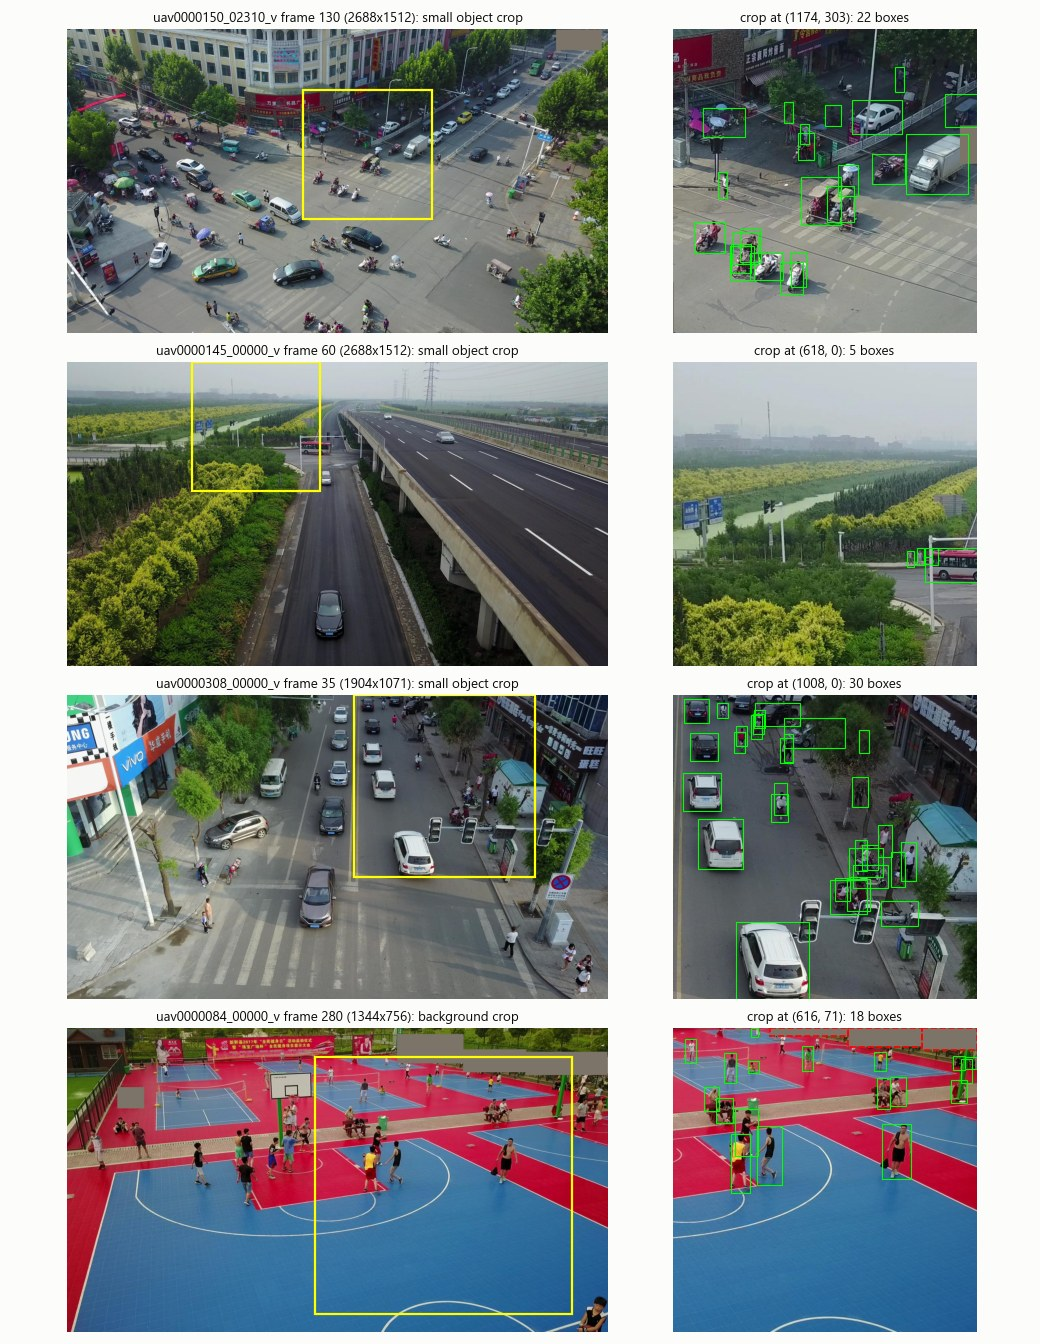

In [52]:
from matplotlib.patches import Rectangle
from torchvision.models.detection.transform import GeneralizedRCNNTransform

CROP_SIZE = 640
CROP_SHARE = 0.5
BACKGROUND_SHARE = 0.25
SMALL_AREA = 32**2
CROP_KEEP_VISIBLE = 0.5

def crop_boxes(boxes, x0, y0, size):
    """xyxy boxes in crop coordinates, clipped to the crop, and which of them are visible enough to keep."""
    shifted = torch.as_tensor(boxes, dtype=torch.float32) - torch.tensor([x0, y0, x0, y0], dtype=torch.float32)
    clipped = shifted.clamp(0, size)
    area = (shifted[:, 2] - shifted[:, 0]) * (shifted[:, 3] - shifted[:, 1])
    visible = (clipped[:, 2] - clipped[:, 0]) * (clipped[:, 3] - clipped[:, 1])
    return clipped, visible >= CROP_KEEP_VISIBLE * area, visible > 0

def crop_sample(image, target, x0, y0, size):
    """Cut a size×size window from a masked training sample.

    A box cut by the edge stays when enough of it is visible; otherwise its visible part is painted with the
    ignore colour and the box is dropped. Ignore regions need no work here: the dataset has already painted them.
    """
    image = image[:, y0 : y0 + size, x0 : x0 + size].clone()
    clipped, keep, visible = crop_boxes(target["boxes"], x0, y0, size)
    fill = torch.tensor(IGNORE_FILL_RGB, dtype=image.dtype)[:, None, None] / 255
    for x1, y1, x2, y2 in clipped[visible & ~keep].tolist():
        image[:, int(np.floor(y1)) : int(np.ceil(y2)), int(np.floor(x1)) : int(np.ceil(x2))] = fill
    return image, {**target, "boxes": clipped[keep], "labels": target["labels"][keep]}

def flip_horizontally(image, target):
    boxes = target["boxes"].clone()
    boxes[:, [0, 2]] = image.shape[-1] - target["boxes"][:, [2, 0]]
    return image.flip(-1), {**target, "boxes": boxes}

class CropMixView:
    """Training samples: whole frames exactly as TrainingView gives them, or close-up crops.

    Whether a sample is a crop, where the crop lies and whether it is flipped depend only on
    (seed, epoch, index), as in TrainingView. Crops carry keep_scale=True, see KeepScaleTransform.
    """

    def __init__(self, frames, config, epoch):
        self.frames, self.size, self.share = frames, config.crop_size, config.crop_share
        self.seed, self.epoch = config.seed, epoch
        self.whole = TrainingView(frames, config.seed, epoch)

    def rng(self, index, purpose):
        return np.random.default_rng((self.seed, self.epoch, index, purpose))

    def is_crop(self, index):
        return self.rng(index, 1).random() < self.share

    def window(self, index):
        """Top-left corner of the crop and its kind: around a random small object, or background."""
        frame, rng = self.frames[index], self.rng(index, 2)
        limit_x, limit_y = frame.width - self.size, frame.height - self.size
        assert limit_x >= 0 and limit_y >= 0, frame.path
        boxes = frame.boxes[ignored_overlap(frame.boxes, frame.ignore) < IGNORE_DROP_OVERLAP]
        centres = boxes[:, :2] + boxes[:, 2:] / 2
        small = centres[boxes[:, 2] * boxes[:, 3] < SMALL_AREA]
        if len(small) and rng.random() >= BACKGROUND_SHARE:
            cx, cy = small[rng.integers(len(small))]
            x0, y0, kind = cx - rng.uniform(0.1, 0.9) * self.size, cy - rng.uniform(0.1, 0.9) * self.size, "small object"
        else:
            def objects_inside(corner):
                x, y = corner
                return ((centres[:, 0] >= x) & (centres[:, 0] < x + self.size) & (centres[:, 1] >= y) & (centres[:, 1] < y + self.size)).sum()

            (x0, y0), kind = min(rng.uniform(0, 1, (20, 2)) * (limit_x, limit_y), key=objects_inside), "background"
        return int(np.clip(round(x0), 0, limit_x)), int(np.clip(round(y0), 0, limit_y)), kind

    def __getitem__(self, index):
        if not self.is_crop(index):
            return self.whole[index]
        image, target = self.whole.dataset[index]
        x0, y0, _ = self.window(index)
        image, target = crop_sample(image, target, x0, y0, self.size)
        if self.rng(index, 3).random() < 0.5:
            image, target = flip_horizontally(image, target)
        return image, {**target, "keep_scale": True}

def crop_mix_samples(frames, config, epoch):
    """The same frames as whole_frame_samples, each turned into a crop with probability crop_share.

    Crops are batched with crops and whole frames with whole frames: torchvision pads every image in a
    batch to the largest, so a crop next to a whole frame would cost as much as a whole frame.
    """
    view = CropMixView(frames, config, epoch)
    order = epoch_indices(frames, epoch, config.seed)
    groups = [[i for i in order if view.is_crop(i)], [i for i in order if not view.is_crop(i)]]
    batches = [group[start : start + config.batch_size] for group in groups for start in range(0, len(group), config.batch_size)]
    full = [batch for batch in batches if len(batch) == config.batch_size]
    rest = [i for batch in batches if len(batch) < config.batch_size for i in batch]
    shuffled = np.random.default_rng((config.seed, epoch, 4)).permutation(len(full))
    return view, [i for b in shuffled for i in full[b]] + rest

SAMPLERS["crop_mix"] = crop_mix_samples

class KeepScaleTransform(GeneralizedRCNNTransform):
    """torchvision's resize, except for training samples marked keep_scale (crops), which keep their size.

    Without it every 640-pixel crop would be enlarged to the 800-pixel short side used for whole frames.
    In eval mode every image is resized as before, so inference is unchanged.
    """

    def resize(self, image, target=None):
        if self.training and target is not None and target.get("keep_scale"):
            return image, target
        return super().resize(image, target)

def build_faster_rcnn_keep_scale(config):
    model = build_faster_rcnn(config)
    old = model.transform
    model.transform = KeepScaleTransform(old.min_size, old.max_size, old.image_mean, old.image_std)
    return model

MODEL_BUILDERS["faster_rcnn_r50_fpn_v1_keep_scale"] = build_faster_rcnn_keep_scale
frcnn_base = EXPERIMENT_REGISTRY[FRCNN_BASE_RUN.name]

def crop_pass(number, start):
    """Configuration of crop-mix pass `number`, starting from the weights in `start`."""
    return replace(
        frcnn_base, name=f"{FRCNN_BASE_RUN.name}_crops_pass{number}", model="faster_rcnn_r50_fpn_v1_keep_scale", stage=10,
        epochs=1, lr=frcnn_base.lr * 0.1, lr_decay_epochs=(), init_weights=start.relative_to(PROJECT_ROOT).as_posix(),
        epoch_offset=frcnn_base.epochs + number - 1, sampler="crop_mix", crop_share=CROP_SHARE, crop_size=CROP_SIZE,
        change=f"Crop-mix pass {number} from {start.parent.name}: {CROP_SHARE:.0%} {CROP_SIZE} px crops at original resolution, fresh SGD at lr/10",
    )

CROP_PASS_1 = crop_pass(1, FRCNN_BASE_RUN / "final.pt")

def check_crop_geometry():
    """Synthetic cases with known answers: shifted, clipped, dropped-and-painted and outside boxes, and the flip."""
    image = torch.zeros(3, 100, 200)
    image[:, 20:30, 60:80] = 1.0
    boxes = torch.tensor([[60.0, 20, 80, 30], [45, 40, 55, 50], [42, 60, 52, 70], [150, 10, 160, 20]])
    target = {"boxes": boxes, "labels": torch.tensor([0, 1, 2, 3])}
    crop, cropped = crop_sample(image, target, 50, 10, 60)
    assert cropped["labels"].tolist() == [0, 1], cropped
    assert torch.equal(cropped["boxes"], torch.tensor([[10.0, 10, 30, 20], [0, 30, 5, 40]]))
    assert torch.allclose(crop[:, 50:60, 0:2], torch.tensor(IGNORE_FILL_RGB)[:, None, None] / 255)
    assert (crop[:, 10:20, 10:30] == 1).all() and (crop == 1).sum() == crop[:, 10:20, 10:30].numel()
    flipped, mirrored = flip_horizontally(crop, cropped)
    x1, y1, x2, y2 = mirrored["boxes"][0].int().tolist()
    assert torch.equal(mirrored["boxes"][0], torch.tensor([30.0, 10, 50, 20])) and (flipped[:, y1:y2, x1:x2] == 1).all()

def check_crop_mix(config, examples=4):
    """Real-sample checks of boxes, ignore regions and the resize; pass statistics; a figure of examples."""
    check_crop_geometry()
    view, order = crop_mix_samples(train_frames, config, config.epoch_offset)
    crops = [i for i in order if view.is_crop(i)]
    pairs = [order[i : i + config.batch_size] for i in range(0, len(order), config.batch_size)]
    mixed = sum(len({view.is_crop(i) for i in pair}) > 1 for pair in pairs)

    fill = torch.tensor(IGNORE_FILL_RGB, dtype=torch.float32)[:, None, None] / 255
    checked = 0
    for index in crops[:300]:
        frame = train_frames[index]
        x0, y0, _ = view.window(index)
        image, target = crop_sample(*view.whole.dataset[index], x0, y0, CROP_SIZE)
        assert image.shape == (3, CROP_SIZE, CROP_SIZE) and ((target["boxes"] >= 0) & (target["boxes"] <= CROP_SIZE)).all()
        regions, _, inside = crop_boxes(xywh_to_xyxy(frame.ignore).reshape(-1, 4), x0, y0, CROP_SIZE)
        for x1, y1, x2, y2 in regions[inside].tolist():
            core = image[:, int(np.ceil(y1)) : int(np.floor(y2)), int(np.ceil(x1)) : int(np.floor(x2))]
            if core.numel():
                assert torch.allclose(core, fill.expand_as(core)), frame.path
                checked += 1

    transform = build_faster_rcnn_keep_scale(config).transform
    crop_image, crop_target = view[crops[0]]
    whole_image, whole_target = view[next(i for i in order if not view.is_crop(i))]
    sizes = transform.train()([crop_image, whole_image], [crop_target, whole_target])[0].image_sizes
    assert tuple(sizes[0]) == (CROP_SIZE, CROP_SIZE) and abs(max(sizes[1]) - config.long_side) <= 1, sizes
    eval_sizes = transform.eval()([crop_image])[0].image_sizes
    assert abs(min(eval_sizes[0]) - min(transform.min_size)) <= 1, eval_sizes

    rows = []
    for index in order:
        frame = train_frames[index]
        boxes = frame.boxes[ignored_overlap(frame.boxes, frame.ignore) < IGNORE_DROP_OVERLAP]
        if view.is_crop(index):
            x0, y0, kind = view.window(index)
            _, keep, _ = crop_boxes(xywh_to_xyxy(boxes).reshape(-1, 4), x0, y0, CROP_SIZE)
            boxes = boxes[keep.numpy()]
        else:
            kind = "whole frame"
        rows.append({"kind": kind, "clip": frame.clip, "objects": len(boxes), "small": int((boxes[:, 2] * boxes[:, 3] < SMALL_AREA).sum())})
    samples = pd.DataFrame(rows)
    summary = samples.groupby("kind").agg(samples=("objects", "size"), clips=("clip", "nunique"), objects_per_sample=("objects", "mean"),
                                          small_per_sample=("small", "mean"), empty_share=("objects", lambda o: (o == 0).mean()))
    display(summary.round(3))
    print(f"{len(crops)} of {len(order)} samples are crops ({len(crops) / len(order):.0%}); {mixed} of {len(pairs)} batches mix a crop "
          f"with a whole frame; {checked} ignore regions inside crops hold only the ignore colour; in training a crop stays "
          f"{tuple(sizes[0])} and a whole frame becomes {tuple(sizes[1])}; in eval a crop becomes {tuple(eval_sizes[0])}")

    chosen, clips = [], set()
    for index in crops:
        kind = view.window(index)[2]
        wanted = "background" if len(chosen) == examples - 1 else "small object"
        if kind == wanted and train_frames[index].clip not in clips:
            chosen.append(index)
            clips.add(train_frames[index].clip)
        if len(chosen) == examples:
            break
    figure, axes = plt.subplots(len(chosen), 2, figsize=(13, 4.2 * len(chosen)), gridspec_kw={"width_ratios": [1.6, 1]}, squeeze=False)
    for row, index in zip(axes, chosen):
        frame = train_frames[index]
        x0, y0, kind = view.window(index)
        whole, whole_target = view.whole.dataset[index]
        image, target = crop_sample(whole, whole_target, x0, y0, CROP_SIZE)
        row[0].imshow(whole.permute(1, 2, 0).numpy())
        row[0].add_patch(Rectangle((x0, y0), CROP_SIZE, CROP_SIZE, fill=False, edgecolor="yellow", linewidth=2))
        row[0].set_title(f"{frame.clip} frame {frame.frame_index} ({frame.width}x{frame.height}): {kind} crop")
        row[1].imshow(image.permute(1, 2, 0).numpy())
        for x1, y1, x2, y2 in target["boxes"].tolist():
            row[1].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=1))
        regions, _, inside = crop_boxes(xywh_to_xyxy(frame.ignore).reshape(-1, 4), x0, y0, CROP_SIZE)
        for x1, y1, x2, y2 in regions[inside].tolist():
            row[1].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=1.5, linestyle="--"))
        row[1].set_title(f"crop at ({x0}, {y0}): {len(target['boxes'])} boxes")
        for axis in row:
            axis.axis("off")
    figure.tight_layout()
    figure.savefig(CROP_DIR / "crop_examples.png", dpi=80)
    plt.close(figure)
    show_saved_figure(CROP_DIR / "crop_examples.png")

check_crop_mix(CROP_PASS_1)

In [53]:
import gc

import psutil

def benchmark_training(config, steps=100, warmup=10):
    """Training throughput from the starting weights, over `steps` optimizer steps after `warmup` steps.

    Each step is split into waiting for the loader and GPU work (synchronized), so a slow setup shows which
    of the two limits it. Mixed precision and the bounded prefetch are the same as in training. The weights are discarded.
    """
    set_seed(config.seed)
    model = MODEL_BUILDERS[config.model](config).to(DEVICE)
    model.load_state_dict(torch.load(PROJECT_ROOT / config.init_weights, map_location="cpu"))
    model.train()
    parameters = [p for p in model.parameters() if p.requires_grad]
    optimizer, scaler = build_optimizer(model, config), torch.amp.GradScaler("cuda")
    view, order = SAMPLERS[config.sampler](train_frames, config, config.epoch_offset)
    batches = iterate_batches(view, order, config.batch_size)
    waiting = computing = 0.0
    images_seen = 0
    for step in range(warmup + steps):
        if step == warmup:
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
        started = time.perf_counter()
        images, targets = next(batches)
        loaded = time.perf_counter()
        train_step(model, optimizer, scaler, parameters, images, targets, config)
        torch.cuda.synchronize()
        if step >= warmup:
            waiting += loaded - started
            computing += time.perf_counter() - loaded
            images_seen += len(images)
    batches.close()
    result = {
        "setup": config.sampler,
        "images_per_second": images_seen / (waiting + computing),
        "loader_wait_share": waiting / (waiting + computing),
        "gpu_ms_per_image": 1000 * computing / images_seen,
        "peak_vram_allocated_gb": torch.cuda.max_memory_allocated() / 1024**3,
        "peak_vram_reserved_gb": torch.cuda.max_memory_reserved() / 1024**3,
        "ram_available_gb": psutil.virtual_memory().available / 1024**3,
        "notebook_process_ram_gb": psutil.Process().memory_info().rss / 1024**3,
    }
    del model, optimizer, scaler
    gc.collect()
    torch.cuda.empty_cache()
    return result

SPEED_PATH = CROP_DIR / "training_speed.csv"
if not SPEED_PATH.exists():
    whole_frames = replace(CROP_PASS_1, model=frcnn_base.model, sampler="whole_frames", crop_share=0.0, crop_size=0)
    pd.DataFrame([benchmark_training(whole_frames), benchmark_training(CROP_PASS_1)]).to_csv(SPEED_PATH, index=False)
speed = pd.read_csv(SPEED_PATH)
display(speed.round(3))
print(f"crop mix: {speed.images_per_second[1] / speed.images_per_second[0]:.2f}x the images per second of whole frames")

,setup,images_per_second,loader_wait_share,gpu_ms_per_image,peak_vram_allocated_gb,peak_vram_reserved_gb,ram_available_gb,notebook_process_ram_gb
0,whole_frames,7.965,0.004,125.089,3.730,7.484,10.312,2.256
1,crop_mix,10.401,0.004,95.729,3.572,4.336,10.436,2.209


crop mix: 1.31x the images per second of whole frames


In [54]:
USEFUL_GAIN = 0.005
SECOND_PASS_TIME_ALLOWS = True

def run_result(run_dir):
    return json.loads((run_dir / "result.json").read_text())

base_scores = run_result(FRCNN_BASE_RUN)
run_experiments([CROP_PASS_1])
crop_runs = [stage_dir(10) / CROP_PASS_1.name]
first = run_result(crop_runs[0])
gain = {key: first[key] - base_scores[key] for key in ("mAP", "AP_small")}
useful = gain["mAP"] >= USEFUL_GAIN or (gain["AP_small"] >= USEFUL_GAIN and gain["mAP"] >= 0)
print(f"pass 1 against the starting model: mAP {gain['mAP']:+.4f}, AP_small {gain['AP_small']:+.4f}; "
      + ("useful, so a second pass runs" if useful and SECOND_PASS_TIME_ALLOWS else "not useful enough for a second pass"))
if useful and SECOND_PASS_TIME_ALLOWS:
    second = crop_pass(2, crop_runs[0] / "final.pt")
    run_experiments([second])
    crop_runs.append(stage_dir(10) / second.name)

TEST_SIZED_IDS = sorted(f.image_id for f in val_frames if f.width <= 1920)
TEST_SIZED = set(TEST_SIZED_IDS)
compared = {"FCOS, section 6.2 file": stage_dir(6) / "fcos_radius_1_diou_5ep", "Faster R-CNN start": FRCNN_BASE_RUN, **{run.name: run for run in crop_runs}}
rows = []
for label, run in compared.items():
    result = run_result(run)
    detections = json.loads((run / "val_detections.json").read_text())
    subset = evaluate_detections([d for d in detections if d["image_id"] in TEST_SIZED], TEST_SIZED_IDS)
    del detections
    rows.append({"model": label, **{key: result[key] for key in METRICS}, **{f"AP_{name}": result[f"AP_{name}"] for name in CLASS_NAMES},
                 "mAP_val_up_to_1920": subset["mAP"], "AP_small_val_up_to_1920": subset["AP_small"]})
comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv(CROP_DIR / "comparison.csv")
print(f"diagnostic subset: {len(TEST_SIZED_IDS)} of {len(val_frames)} validation frames, up to 1920 pixels wide")
display(comparison[METRICS + ["mAP_val_up_to_1920", "AP_small_val_up_to_1920"]].round(4))
display(comparison[[f"AP_{name}" for name in CLASS_NAMES]].round(4))
display(pd.concat([pd.read_csv(run / "history.csv").assign(run=run.name) for run in crop_runs])[["run", "lr", "loss", "val_subset_mAP", "val_subset_AP_small"]].round(4))

frcnn_anchors_16_256_5ep_crops_pass1 {'mAP': 0.1983, 'AP50': 0.4181, 'AP_small': 0.1026, 'fps': 14.9577, 'train_minutes': 31.4808}


pass 1 against the starting model: mAP +0.0014, AP_small +0.0010; not useful enough for a second pass
diagnostic subset: 1286 of 2846 validation frames, up to 1920 pixels wide


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,mAP_val_up_to_1920,AP_small_val_up_to_1920
model,,,,,,,,
"FCOS, section 6.2 file",0.1990,0.4012,0.1742,0.0930,0.1788,0.3609,0.2202,0.1101
Faster R-CNN start,0.1969,0.4163,0.1638,0.1016,0.1844,0.3463,0.2100,0.1193
frcnn_anchors_16_256_5ep_crops_pass1,0.1983,0.4181,0.1641,0.1026,0.1832,0.3443,0.2104,0.1205


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
model,,,,,,,,
"FCOS, section 6.2 file",0.2669,0.1972,0.3844,0.2340,0.1790,0.2038,0.0130,0.1137
Faster R-CNN start,0.2605,0.1927,0.3785,0.2181,0.2191,0.1923,0.0011,0.1127
frcnn_anchors_16_256_5ep_crops_pass1,0.2599,0.1946,0.3746,0.2193,0.2334,0.1857,0.0105,0.1082


,run,lr,loss,val_subset_mAP,val_subset_AP_small
0,frcnn_anchors_16_256_5ep_crops_pass1,0.0002,0.6271,0.1984,0.1065


In [55]:
from torchvision.ops import batched_nms

TILE_SIZE, TILE_OVERLAP, TILE_BATCH = 640, 128, 4
TILE_NMS_IOU = 0.5

def tile_starts(length, tile=TILE_SIZE, overlap=TILE_OVERLAP):
    """Tile start positions covering 0..length, with at least `overlap` pixels shared by neighbours."""
    if length <= tile:
        return [0]
    return list(range(0, length - tile, tile - overlap)) + [length - tile]

class TiledDetector:
    """Whole-frame prediction at the original settings plus overlapping tiles at original resolution.

    Tile boxes are shifted back to frame coordinates, duplicates are merged with class-wise NMS, and the
    best MAX_DETECTIONS are kept. Called like the detector, so predict() and write_submission() use it unchanged.
    """

    def __init__(self, model):
        self.model, self.label_offset = model.eval(), model.label_offset
        self.whole_size = (model.transform.min_size, model.transform.max_size)

    def eval(self):
        return self

    def __call__(self, images):
        return [self.predict_one(image) for image in images]

    def predict_one(self, image):
        transform = self.model.transform
        transform.min_size, transform.max_size = self.whole_size
        parts = [self.model([image])[0]]
        transform.min_size, transform.max_size = (TILE_SIZE,), TILE_SIZE
        corners = [(x, y) for y in tile_starts(image.shape[-2]) for x in tile_starts(image.shape[-1])]
        for start in range(0, len(corners), TILE_BATCH):
            chunk = corners[start : start + TILE_BATCH]
            outputs = self.model([image[:, y : y + TILE_SIZE, x : x + TILE_SIZE] for x, y in chunk])
            for (x, y), output in zip(chunk, outputs):
                parts.append({**output, "boxes": output["boxes"] + output["boxes"].new_tensor([x, y, x, y])})
        transform.min_size, transform.max_size = self.whole_size
        boxes, scores, labels = (torch.cat([part[key] for part in parts]) for key in ("boxes", "scores", "labels"))
        keep = batched_nms(boxes, scores, labels, TILE_NMS_IOU)[:MAX_DETECTIONS]
        return {"boxes": boxes[keep], "scores": scores[keep], "labels": labels[keep]}

TILED_RUN = crop_runs[-1]
TILED_PATH = CROP_DIR / f"tiled_{TILED_RUN.name}.json"
if not TILED_PATH.exists():
    tiled = TiledDetector(load_finished_model(TILED_RUN))
    detections = predict(tiled, val_frames)
    metrics = evaluate_detections(detections)
    subset = evaluate_detections([d for d in detections if d["image_id"] in TEST_SIZED], TEST_SIZED_IDS)
    del detections
    TILED_PATH.write_text(json.dumps({**metrics, "mAP_val_up_to_1920": subset["mAP"], "AP_small_val_up_to_1920": subset["AP_small"],
                                      "fps": measure_speed(tiled, val_frames, passes=2)}, indent=2))
    del tiled
    torch.cuda.empty_cache()
tiled_scores = json.loads(TILED_PATH.read_text())

candidates = pd.DataFrame(
    [{"candidate": FRCNN_BASE_RUN.name, "run": FRCNN_BASE_RUN, "tiled": False, **{key: base_scores[key] for key in METRICS}}]
    + [{"candidate": run.name, "run": run, "tiled": False, **{key: run_result(run)[key] for key in METRICS}} for run in crop_runs]
    + [{"candidate": f"{TILED_RUN.name}, tiled", "run": TILED_RUN, "tiled": True, **{key: tiled_scores[key] for key in METRICS}}]
)
candidates.drop(columns="run").to_csv(CROP_DIR / "candidates.csv", index=False)
display(candidates.drop(columns="run").round(4))
best = candidates.sort_values("mAP").iloc[-1]
if best.run == FRCNN_BASE_RUN:
    CROP_SUBMISSION = FRCNN_BASE_SUBMISSION
else:
    CROP_SUBMISSION = CROP_DIR / f"submission_{best.run.name}{'_tiled' if best.tiled else ''}.csv"
    if not CROP_SUBMISSION.exists():
        final_model = load_finished_model(best.run)
        write_submission(TiledDetector(final_model) if best.tiled else final_model, CROP_SUBMISSION)
        del final_model
        torch.cuda.empty_cache()
print(f"Best candidate: {best.candidate}, validation mAP {best.mAP:.4f}, AP_small {best.AP_small:.4f}")
print("File:", CROP_SUBMISSION)
print(validate_submission(CROP_SUBMISSION))

,candidate,tiled,mAP,AP50,AP75,AP_small,AP_medium,AP_large
0,frcnn_anchors_16_256_5ep,False,0.1969,0.4163,0.1638,0.1016,0.1844,0.3463
1,frcnn_anchors_16_256_5ep_crops_pass1,False,0.1983,0.4181,0.1641,0.1026,0.1832,0.3443
2,"frcnn_anchors_16_256_5ep_crops_pass1, tiled",True,0.1853,0.4317,0.1319,0.1012,0.1869,0.3121


Best candidate: frcnn_anchors_16_256_5ep_crops_pass1, validation mAP 0.1983, AP_small 0.1026
File: c:\Programming\Git_repos\Year3_Sem2\artificial-intelligence\ai-homework-2\outputs\6.6_crop_training\submission_frcnn_anchors_16_256_5ep_crops_pass1.csv
{'images': 3811, 'predictions': 466232, 'per_image_mean': 122.33849383363946, 'per_image_max': 256, 'images_without_predictions': 0}


### 6.7 Faster R-CNN crop training follow-up

> **Outcome: did not work.** Pass 2 scored 0.1953 against 0.1983 for pass 1 (−0.0030), so pass 3 was not run and pass 1 stayed the Faster R-CNN file.

The section 6.6 file from crop pass 1 scored 0.2258 on the public leaderboard, above the public baseline of 0.2216. That file and its checkpoint stay as the fallback. As before, the score is only the reason for this stage. Every choice below is made on the official validation set.

**Pass 2.** One more full pass from the pass 1 weights.
- The crop mix, model and inference settings are the same as in pass 1.
- The frames are new. Pass 2 uses frame offset 6, the frames with (frame_index + 1) % 5 == 0. Pass 1 used offset 5, which picks the offset-0 frames. So none of the frames that pass 2 crops was cropped in pass 1, and the crop positions and flips come from a new random seed.
- The learning rate is pass 1's: a fresh SGD at one tenth of the original rate (0.00025, the rate of epoch 3 in the original schedule), with the usual 500-iteration warm-up. Only the frames change between the two passes.
- Checkpoints: `train_experiment` saves `last.pt` at the end of every epoch, and a pass is one epoch. An interrupted pass therefore restarts from its beginning. There is no checkpoint partway through a pass.

**GPU memory cap.** During pass 1 the alternating crop and whole-frame batch sizes let PyTorch's memory cache grow to 7.9 of 8.2 GB, although at most 3.7 GB was in use. With the display on the same GPU, Windows moved memory into shared system RAM. Utilization stayed at 100% while power fell from 99 W to about 55 W, so the pass took 31.5 minutes instead of about 8. The loader was waiting only 0.4% of the time. Capping the process at 75% of GPU memory makes PyTorch free its cache before it grows past about 6 GB. This changes speed only, not the computation.

**Decision rule, fixed before the result.** Pass 2 replaces pass 1 only if both of these hold:
- its full official-validation mAP is higher;
- it stays higher when any single validation clip is left out.

The clip check uses the predictions both runs saved during evaluation, so no inference runs again. A gain that one clip reverses depends on that clip and does not count. Otherwise pass 1 stays the recommended file. (Sections 6.5 and 6.6 used a 0.005 bar for a different question: whether a result justified more training time.)

**Pass 3, only after a clear pass 2 gain.** A short pass from the pass 2 weights:
- 1,200 training images: the first 600 batches of the next pass, at frame offset 7, about half of them crops;
- one hundredth of the original learning rate (0.000025, the rate of the last original epoch);
- a 100-iteration warm-up, so that the short pass is not mostly warm-up.

It must beat pass 2 under the same rule.

In [56]:
CROP_FOLLOWUP_DIR = stage_dir(11)
CROP_FOLLOWUP_DIR.mkdir(parents=True, exist_ok=True)

GPU_MEMORY_CAP = 0.75
torch.cuda.set_per_process_memory_fraction(GPU_MEMORY_CAP)

PASS_1_RUN = CROP_DIR / CROP_PASS_1.name
PASS_1_SUBMISSION = CROP_DIR / f"submission_{CROP_PASS_1.name}.csv"
CROP_PASS_2 = replace(crop_pass(2, PASS_1_RUN / "final.pt"), stage=11)
PASS_2_RUN = CROP_FOLLOWUP_DIR / CROP_PASS_2.name
PASS_2_SUBMISSION = CROP_FOLLOWUP_DIR / f"submission_{CROP_PASS_2.name}.csv"
VAL_CLIPS = sorted({f.clip for f in val_frames})

def saved_scores(run_dir):
    return json.loads((run_dir / "result.json").read_text())

def clip_check(new_run, old_run):
    """Both runs' mAP with each validation clip left out, from the predictions saved during evaluation."""
    new, old = (json.loads((run / "val_detections.json").read_text()) for run in (new_run, old_run))
    rows = []
    for clip in VAL_CLIPS:
        kept_ids = [f.image_id for f in val_frames if f.clip != clip]
        kept = set(kept_ids)
        new_map, old_map = (evaluate_detections([d for d in detections if d["image_id"] in kept], kept_ids)["mAP"] for detections in (new, old))
        rows.append({"clip_left_out": clip, "frames_left_out": len(val_frames) - len(kept_ids), "mAP_new": new_map, "mAP_old": old_map, "gain": new_map - old_map})
    return pd.DataFrame(rows)

def clear_gain(new_run, old_run, check_path):
    """The section 6.7 rule: higher full-validation mAP, and still higher with any single validation clip left out."""
    gain = saved_scores(new_run)["mAP"] - saved_scores(old_run)["mAP"]
    if gain <= 0:
        print(f"{new_run.name} against {old_run.name}: full-validation mAP {gain:+.4f}, no gain")
        return False
    if not check_path.exists():
        clip_check(new_run, old_run).to_csv(check_path, index=False)
    check = pd.read_csv(check_path)
    display(check.round(4))
    clear = bool((check.gain > 0).all())
    print(f"{new_run.name} against {old_run.name}: full-validation mAP {gain:+.4f}; with one of {len(VAL_CLIPS)} clips left out, "
          f"the gain is {check.gain.min():+.4f} to {check.gain.max():+.4f}; "
          + ("a clear gain" if clear else "leaving out one clip reverses it, so not a clear gain"))
    return clear

def export(run_dir, path):
    if not path.exists():
        final_model = load_finished_model(run_dir)
        write_submission(final_model, path)
        del final_model
        torch.cuda.empty_cache()
    print("File:", path)
    print(validate_submission(path))

check_crop_geometry()
view, order = crop_mix_samples(train_frames, CROP_PASS_2, CROP_PASS_2.epoch_offset)
_, pass_1_order = crop_mix_samples(train_frames, CROP_PASS_1, CROP_PASS_1.epoch_offset)
crops = [i for i in order if view.is_crop(i)]
kinds = Counter(view.window(i)[2] for i in crops)
print(f"pass 2: {len(order)} samples, {len(crops)} crops ({len(crops) / len(order):.0%}; {kinds['small object']} on a small object, "
      f"{kinds['background']} background) from {len({train_frames[i].clip for i in crops})} of {len({f.clip for f in train_frames})} clips; "
      f"{len(set(order) & set(pass_1_order))} frames shared with pass 1")
del view, order, pass_1_order, crops

run_experiments([CROP_PASS_2])
PASS_2_CLEAR = clear_gain(PASS_2_RUN, PASS_1_RUN, CROP_FOLLOWUP_DIR / "clip_check_pass2.csv")
if PASS_2_CLEAR:
    export(PASS_2_RUN, PASS_2_SUBMISSION)

pass 2: 4827 samples, 2392 crops (50%; 1557 on a small object, 835 background) from 56 of 56 clips; 0 frames shared with pass 1
frcnn_anchors_16_256_5ep_crops_pass2 {'mAP': 0.1953, 'AP50': 0.4113, 'AP_small': 0.1018, 'fps': 15.345, 'train_minutes': 7.2552}
frcnn_anchors_16_256_5ep_crops_pass2 against frcnn_anchors_16_256_5ep_crops_pass1: full-validation mAP -0.0030, no gain


In [57]:
PASS_3_IMAGES = 1200
THIRD_PASS_TIME_ALLOWS = True

def short_crop_mix_samples(frames, config, epoch):
    """The first PASS_3_IMAGES samples of a crop-mix pass: whole batches in random order, about half of them crops."""
    view, order = crop_mix_samples(frames, config, epoch)
    return view, order[:PASS_3_IMAGES]

SAMPLERS["crop_mix_short"] = short_crop_mix_samples
CROP_PASS_3 = replace(
    crop_pass(3, PASS_2_RUN / "final.pt"), stage=11, lr=frcnn_base.lr * 0.01, warmup_iterations=100, sampler="crop_mix_short",
    change=f"Short crop-mix pass 3 from {PASS_2_RUN.name}: {PASS_3_IMAGES} images, fresh SGD at lr/100, 100-iteration warm-up",
)
PASS_3_RUN = CROP_FOLLOWUP_DIR / CROP_PASS_3.name
PASS_3_SUBMISSION = CROP_FOLLOWUP_DIR / f"submission_{CROP_PASS_3.name}.csv"
PASS_3_BETTER = False
if PASS_2_CLEAR and THIRD_PASS_TIME_ALLOWS:
    run_experiments([CROP_PASS_3])
    PASS_3_BETTER = clear_gain(PASS_3_RUN, PASS_2_RUN, CROP_FOLLOWUP_DIR / "clip_check_pass3.csv")
    if PASS_3_BETTER:
        export(PASS_3_RUN, PASS_3_SUBMISSION)
else:
    print("pass 3 not run: pass 2 shows no clear gain over pass 1")

pass 3 not run: pass 2 shows no clear gain over pass 1


In [58]:
followup_runs = {"crop pass 1 (section 6.6)": PASS_1_RUN, "crop pass 2": PASS_2_RUN}
if (PASS_3_RUN / "result.json").exists():
    followup_runs["crop pass 3"] = PASS_3_RUN
test_sized_ids = sorted(f.image_id for f in val_frames if f.width <= 1920)
test_sized = set(test_sized_ids)
rows = []
for label, run in followup_runs.items():
    result = saved_scores(run)
    detections = json.loads((run / "val_detections.json").read_text())
    subset = evaluate_detections([d for d in detections if d["image_id"] in test_sized], test_sized_ids)
    del detections
    rows.append({"model": label, **{key: result[key] for key in METRICS}, **{f"AP_{name}": result[f"AP_{name}"] for name in CLASS_NAMES},
                 "mAP_val_up_to_1920": subset["mAP"], "AP_small_val_up_to_1920": subset["AP_small"], "train_minutes": result["train_minutes"]})
followup_comparison = pd.DataFrame(rows).set_index("model")
followup_comparison.to_csv(CROP_FOLLOWUP_DIR / "comparison.csv")
display(followup_comparison[METRICS + ["mAP_val_up_to_1920", "AP_small_val_up_to_1920", "train_minutes"]].round(4))
display(followup_comparison[[f"AP_{name}" for name in CLASS_NAMES]].round(4))
display(pd.concat([pd.read_csv(run / "history.csv").assign(run=run.name) for run in list(followup_runs.values())[1:]])
        [["run", "train_seconds", "lr", "loss", "val_subset_mAP", "val_subset_AP_small"]].round(4))

CROP_FOLLOWUP_SUBMISSION = PASS_3_SUBMISSION if PASS_3_BETTER else PASS_2_SUBMISSION if PASS_2_CLEAR else PASS_1_SUBMISSION
print("Recommended file:", CROP_FOLLOWUP_SUBMISSION)
print(validate_submission(CROP_FOLLOWUP_SUBMISSION))

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,mAP_val_up_to_1920,AP_small_val_up_to_1920,train_minutes
model,,,,,,,,,
crop pass 1 (section 6.6),0.1983,0.4181,0.1641,0.1026,0.1832,0.3443,0.2104,0.1205,31.4808
crop pass 2,0.1953,0.4113,0.1632,0.1018,0.1826,0.3367,0.2100,0.1195,7.2552


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
model,,,,,,,,
crop pass 1 (section 6.6),0.2599,0.1946,0.3746,0.2193,0.2334,0.1857,0.0105,0.1082
crop pass 2,0.2614,0.2000,0.3758,0.2051,0.2208,0.1884,0.0033,0.1074


,run,train_seconds,lr,loss,val_subset_mAP,val_subset_AP_small
0,frcnn_anchors_16_256_5ep_crops_pass2,435.31,0.0002,0.6157,0.1972,0.1069


Recommended file: c:\Programming\Git_repos\Year3_Sem2\artificial-intelligence\ai-homework-2\outputs\6.6_crop_training\submission_frcnn_anchors_16_256_5ep_crops_pass1.csv
{'images': 3811, 'predictions': 466232, 'per_image_mean': 122.33849383363946, 'per_image_max': 256, 'images_without_predictions': 0}


### 6.8 Faster R-CNN proposal diagnostics

> **Outcome: diagnostic, then a small gain.** Proposals are the first step that loses small objects: 21% of them have no proposal at IoU 0.5. Raising the test-time RPN budget from 1,000 to 3,000 gave +0.0011 mAP on all frames, +0.0010 on the frames up to 1920 wide and +0.0016 without the 4K clip, at 11.7 instead of 15.5 fps. It was kept.

An audit of the validation predictions found that only 56.1% of small objects have a prediction of the correct class at IoU ≥ 0.50, and only 12.4% at IoU ≥ 0.75. Even without the class, 39% have no prediction at IoU ≥ 0.50, and no image reaches the 500-box cap. This stage traces torchvision's Faster R-CNN inference step by step, to find which step loses those objects. It uses the Faster R-CNN checkpoint with the highest full-validation mAP and makes no change to the model.

**Screening set.** 40 evenly spaced labeled frames from each of the 7 validation clips (280 frames), fixed before any result.

**Objects.** Every non-crowd annotation of the official COCO ground truth. Crowd entries are the ignore regions. Size groups follow COCO: small below 32², large from 96².

**Steps traced, each mapped back to original pixels before any IoU is computed:**
1. **Proposals.** The RPN's output (up to 1,000 per image), before the RoI head.
2. **Head outputs before filtering.** For every proposal, the refined box of each class and the class scores, before score filtering and NMS.
3. **Final detections.** The unchanged model's output, the same boxes as in the test files.

A replay of torchvision's own post-processing on step 2 must reproduce step 3 exactly. This checks the trace and the coordinate mapping.

**Losses.** For each object without a correct-class final box at the IoU threshold, the first step that lost it:
- **no proposal:** neither a proposal nor any refined box of the object's class reaches the IoU;
- **refinement:** a proposal reaches it, but none of the refined boxes of the object's class does;
- objects whose refined box reaches the IoU are attributed to the score filter or NMS below, even when their proposal does not reach it.
- **score filter:** a well-placed refined box of the right class exists, but its class score is below 0.05. The record says whether background or another class wins on that proposal.
- **NMS:** such a box scores at least 0.05 but is removed by NMS. The cap of 500 is never reached.

In [59]:
from torchvision.models.detection.transform import resize_boxes
from torchvision.ops import box_iou
from torchvision.ops import boxes as box_ops

RPN_DIR = stage_dir(12)
RPN_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENT_REGISTRY.setdefault(CROP_PASS_1.name, CROP_PASS_1)
SCREEN_PER_CLIP = 40
SMALL_AREA, LARGE_AREA = 32**2, 96**2
IOU_LEVELS = (0.5, 0.75)

def screening_frames(per_clip=SCREEN_PER_CLIP):
    """`per_clip` evenly spaced frames of every validation clip."""
    chosen = []
    for clip in VAL_CLIPS:
        frames = [f for f in val_frames if f.clip == clip]
        chosen += [frames[i] for i in np.linspace(0, len(frames) - 1, per_clip).round().astype(int)]
    return chosen

SCREEN_FRAMES = screening_frames()
SCREEN_IDS = [f.image_id for f in SCREEN_FRAMES]
frcnn_runs = [FRCNN_BASE_RUN, PASS_1_RUN, PASS_2_RUN] + ([PASS_3_RUN] if (PASS_3_RUN / "result.json").exists() else [])
DIAGNOSTIC_RUN = max(frcnn_runs, key=lambda run: saved_scores(run)["mAP"])
print(f"{len(SCREEN_FRAMES)} screening frames from {len(VAL_CLIPS)} clips; checkpoint {DIAGNOSTIC_RUN.name} "
      f"(full-validation mAP {saved_scores(DIAGNOSTIC_RUN)['mAP']:.4f})")

@torch.inference_mode()
def trace(model, image):
    """torchvision's Faster R-CNN inference for one image, step by step.

    Returns the RPN proposals, every proposal's refined box per class and class scores before score filtering
    and NMS (boxes in original pixels), and the final detections of the unchanged model.
    """
    original = image.shape[-2:]
    batch, _ = model.transform([image])
    resized = batch.image_sizes[0]
    features = model.backbone(batch.tensors)
    proposals, _ = model.rpn(batch, features)
    heads = model.roi_heads
    logits, regression = heads.box_predictor(heads.box_head(heads.box_roi_pool(features, proposals, batch.image_sizes)))
    refined = box_ops.clip_boxes_to_image(heads.box_coder.decode(regression, proposals), resized)
    scores = torch.softmax(logits, -1)
    replayed = replay_postprocess(heads, refined, scores)
    final = model([image])[0]
    replayed = resize_boxes(replayed, resized, original)
    assert len(replayed) == len(final["boxes"]) and torch.allclose(replayed, final["boxes"], atol=0.01), "trace differs from the model"
    to_original = lambda boxes: resize_boxes(boxes.reshape(-1, 4), resized, original).reshape(boxes.shape)
    return {"proposals": to_original(proposals[0]), "refined": to_original(refined), "scores": scores, "final": final}

def replay_postprocess(heads, refined, scores):
    """torchvision's RoIHeads.postprocess_detections for one image; returns the kept boxes in resized pixels."""
    classes = scores.shape[1]
    boxes, scores = refined[:, 1:].reshape(-1, 4), scores[:, 1:].reshape(-1)
    labels = torch.arange(1, classes, device=scores.device).repeat(len(refined))
    keep = torch.where(scores > heads.score_thresh)[0]
    boxes, scores, labels = boxes[keep], scores[keep], labels[keep]
    keep = box_ops.remove_small_boxes(boxes, min_size=1e-2)
    boxes, scores, labels = boxes[keep], scores[keep], labels[keep]
    keep = box_ops.batched_nms(boxes, scores, labels, heads.nms_thresh)[: heads.detections_per_img]
    return boxes[keep]

def best_iou(objects, boxes):
    return box_iou(objects, boxes).max(1).values if len(boxes) and len(objects) else torch.zeros(len(objects), device=objects.device)

def object_rows(frame, traced, offset):
    """One row per non-crowd object: the best IoU each step reaches, and why it was lost before the final output."""
    annotations = [a for a in coco_ground_truth("val").imgToAnns[frame.image_id] if not a["iscrowd"]]
    if not annotations:
        return []
    objects = torch.tensor(xywh_to_xyxy([a["bbox"] for a in annotations]), dtype=torch.float32, device=DEVICE)
    classes = torch.tensor([a["category_id"] - 1 + offset for a in annotations], device=DEVICE)
    final = traced["final"]
    ious = {
        "proposal": best_iou(objects, traced["proposals"]),
        "final_any_class": best_iou(objects, final["boxes"]),
        "final_correct_class": torch.stack([best_iou(objects[i : i + 1], final["boxes"][final["labels"] == c])[0] for i, c in enumerate(classes)]),
    }
    rows = []
    for i, (annotation, label) in enumerate(zip(annotations, classes.tolist())):
        refined_ious = box_iou(objects[i : i + 1], traced["refined"][:, label])[0]
        row = {"image_id": frame.image_id, "clip": frame.clip, "width": frame.width, "area": annotation["area"],
               "size": "small" if annotation["area"] < SMALL_AREA else "large" if annotation["area"] >= LARGE_AREA else "medium",
               "class": CLASS_NAMES[label - offset], **{f"iou_{step}": value[i].item() for step, value in ious.items()},
               "iou_refined": refined_ious.max().item()}
        for level in IOU_LEVELS:
            placed = refined_ious >= level
            row[f"lost_at_{level}"] = lost_step(row, level, placed, traced["scores"][:, label], traced["scores"].argmax(1))
        rows.append(row)
    return rows

def lost_step(row, level, placed, class_scores, winners):
    """The first step that loses an object; `placed` marks refined boxes of its class that reach `level`."""
    if row["iou_final_correct_class"] >= level:
        return "found"
    if not placed.any():
        return "no proposal" if row["iou_proposal"] < level else "refinement"
    best = torch.where(placed, class_scores, torch.zeros_like(class_scores)).argmax()
    if class_scores[best] < SCORE_THRESHOLD:
        return "score filter: background wins" if winners[best] == 0 else "score filter: another class wins"
    return "NMS"

def trace_objects(model, frames):
    """object_rows for every frame, and the number of proposals per frame."""
    rows, proposal_counts = [], []
    for index, (images, targets) in enumerate(iterate_batches(VisDroneDataset(frames, mask_ignored=False), range(len(frames)), 1)):
        assert targets[0]["image_id"] == frames[index].image_id
        traced = trace(model, images[0].to(DEVICE))
        proposal_counts.append(len(traced["proposals"]))
        rows += object_rows(frames[index], traced, model.label_offset)
    print(f"trace reproduced the model's output on all {len(frames)} frames; proposals per image: "
          f"mean {np.mean(proposal_counts):.0f}, min {min(proposal_counts)}, max {max(proposal_counts)}")
    return pd.DataFrame(rows), proposal_counts

OBJECTS_PATH = RPN_DIR / "screening_objects.csv"
if not OBJECTS_PATH.exists():
    model = load_finished_model(DIAGNOSTIC_RUN)
    objects, _ = trace_objects(model, SCREEN_FRAMES)
    objects.to_csv(OBJECTS_PATH, index=False)
    del model
    torch.cuda.empty_cache()
screening_objects = pd.read_csv(OBJECTS_PATH)

def coverage_table(objects):
    """Share of objects that each step reaches at each IoU level, by size."""
    table = {}
    for size, group in [("small", objects[objects["size"] == "small"]), ("medium", objects[objects["size"] == "medium"]),
                        ("large", objects[objects["size"] == "large"]), ("all", objects)]:
        row = {"objects": len(group)}
        for level in IOU_LEVELS:
            for step in ("proposal", "refined", "final_any_class", "final_correct_class"):
                row[f"{step}_{level}"] = (group[f"iou_{step}"] >= level).mean()
        table[size] = row
    return pd.DataFrame(table).T

coverage = coverage_table(screening_objects)
coverage.to_csv(RPN_DIR / "screening_coverage.csv")
display(coverage.round(3))
losses = pd.concat({f"IoU {level}": screening_objects.groupby("size")[f"lost_at_{level}"].value_counts(normalize=True).unstack(fill_value=0)
                    for level in IOU_LEVELS}).reindex(columns=["found", "no proposal", "refinement", "score filter: background wins",
                                                                   "score filter: another class wins", "NMS"], fill_value=0)
losses.to_csv(RPN_DIR / "screening_losses.csv")
display(losses.round(3))

WIDTH_GROUPS = {"up to 1920": lambda w: w <= 1920, "2688-2720": lambda w: 1920 < w < 3840, "3840 (4K)": lambda w: w >= 3840}
small = screening_objects[screening_objects["size"] == "small"]
by_width = pd.DataFrame({name: coverage_table(small[small.width.map(test)]).loc["small"] for name, test in WIDTH_GROUPS.items()}).T
by_width.to_csv(RPN_DIR / "screening_small_by_width.csv")
display(by_width.round(3))

280 screening frames from 7 clips; checkpoint frcnn_anchors_16_256_5ep_crops_pass1 (full-validation mAP 0.1983)


,objects,proposal_0.5,refined_0.5,final_any_class_0.5,final_correct_class_0.5,proposal_0.75,refined_0.75,final_any_class_0.75,final_correct_class_0.75
small,2306.0,0.778,0.751,0.621,0.566,0.333,0.343,0.150,0.124
medium,9676.0,0.906,0.898,0.831,0.772,0.535,0.610,0.410,0.365
large,1764.0,0.990,0.990,0.977,0.931,0.815,0.887,0.782,0.724
all,13746.0,0.895,0.885,0.815,0.758,0.537,0.601,0.414,0.371


found  no proposal  refinement  score filter: background wins  score filter: another class wins    NMS
         size                                                                                                          
IoU 0.5  large   0.931        0.009       0.001                          0.020                             0.028  0.011
         medium  0.772        0.087       0.014                          0.048                             0.030  0.048
         small   0.566        0.211       0.038                          0.094                             0.016  0.075
IoU 0.75 large   0.724        0.086       0.027                          0.016                             0.033  0.113
         medium  0.365        0.325       0.065                          0.030                             0.032  0.183
         small   0.124        0.564       0.093                          0.046                             0.006  0.167

,objects,proposal_0.5,refined_0.5,final_any_class_0.5,final_correct_class_0.5,proposal_0.75,refined_0.75,final_any_class_0.75,final_correct_class_0.75
up to 1920,2050.0,0.835,0.806,0.677,0.621,0.369,0.380,0.166,0.138
2688-2720,182.0,0.390,0.319,0.242,0.181,0.055,0.066,0.027,0.016
3840 (4K),74.0,0.162,0.284,0.014,0.000,0.000,0.000,0.000,0.000


#### Larger RPN proposal budget

Read from the tables above (small objects, IoU 0.50, all screening frames):
- **Proposals are the first step that loses them.** About 22% of small objects have no proposal, and in frames up to 1920 pixels wide about 16%. In the larger frames most small objects have none, because the resize shrinks them.
- **The budget binds.** Every screening image used all 1,000 proposals that torchvision keeps at test time. At most 1,000 candidates per pyramid level enter the RPN's NMS, and 1,000 leave it. Frames hold dozens to hundreds of objects, and the finest level, where small objects are found, has the most candidates.
- **Later losses are reported but not changed here.** After a well-placed refined box exists, the 0.05 score filter and NMS lose most of the rest. Changing them would be a separate experiment.

**The experiment.** The same checkpoint with the test-time RPN budget raised from 1,000 to 3,000, both before and after the RPN's NMS. Nothing else changes: resize, RPN NMS, score threshold, detection NMS and the 500 cap. The original settings are the control.

**Rules, fixed before the result.**
1. **Screening set.** The larger budget goes on to full validation only if both of these hold:
   - screening mAP is higher;
   - more small objects get a correct-class box at IoU 0.50.
2. **Full official validation.** A new test file is written only if all three of these hold:
   - full-validation mAP is higher;
   - mAP on the frames up to 1920 pixels wide is higher;
   - the gain remains with the 4K clip left out.

   The control's numbers are the saved section 6.6 predictions, made with the same code and settings.

In [60]:
RPN_TEST_BUDGET = 3000
CONTROL_BUDGET = 1000

def set_rpn_budget(model, budget):
    """Test-time proposals kept before and after the RPN's NMS; training values and everything else stay as they are."""
    model.rpn._pre_nms_top_n["testing"] = budget
    model.rpn._post_nms_top_n["testing"] = budget
    return model

BUDGET_SCREEN_PATH = RPN_DIR / "screening_rpn_budget.csv"
if not BUDGET_SCREEN_PATH.exists():
    model = load_finished_model(DIAGNOSTIC_RUN)
    assert model.rpn.pre_nms_top_n() == model.rpn.post_nms_top_n() == CONTROL_BUDGET
    rows = []
    for budget in (CONTROL_BUDGET, RPN_TEST_BUDGET):
        set_rpn_budget(model, budget)
        objects, counts = (screening_objects, None) if budget == CONTROL_BUDGET else trace_objects(model, SCREEN_FRAMES)
        if budget != CONTROL_BUDGET:
            objects.to_csv(RPN_DIR / f"screening_objects_rpn{budget}.csv", index=False)
        table = coverage_table(objects)
        metrics = evaluate_detections(predict(model, SCREEN_FRAMES), SCREEN_IDS)
        rows.append({"rpn_budget": budget, **{f"screen_{key}": metrics[key] for key in ("mAP", "AP75", "AP_small")},
                     **{f"small_{column}": table.loc["small", column] for column in table.columns if column != "objects"},
                     "fps": measure_speed(model, val_frames)})
    del model
    torch.cuda.empty_cache()
    pd.DataFrame(rows).to_csv(BUDGET_SCREEN_PATH, index=False)
budget_screen = pd.read_csv(BUDGET_SCREEN_PATH).set_index("rpn_budget")
display(budget_screen.T.round(4))
change = budget_screen.loc[RPN_TEST_BUDGET] - budget_screen.loc[CONTROL_BUDGET]
BUDGET_HELPS_ON_SCREEN = change["screen_mAP"] > 0 and change["small_final_correct_class_0.5"] > 0
print(f"RPN budget {RPN_TEST_BUDGET} against {CONTROL_BUDGET} on the screening set: mAP {change['screen_mAP']:+.4f}, "
      f"small objects with a correct-class box at IoU 0.50 {change['small_final_correct_class_0.5']:+.3f}, "
      f"with a proposal at IoU 0.50 {change['small_proposal_0.5']:+.3f}; "
      + ("it helps, so full validation follows" if BUDGET_HELPS_ON_SCREEN else "no help, so no full validation"))

rpn_budget,1000,3000
screen_mAP,0.2172,0.2186
screen_AP75,0.1848,0.1848
screen_AP_small,0.1065,0.1065
small_proposal_0.5,0.7780,0.8335
small_refined_0.5,0.7511,0.8122
small_final_any_class_0.5,0.6210,0.6370
small_final_correct_class_0.5,0.5663,0.5828
small_proposal_0.75,0.3326,0.3859
small_refined_0.75,0.3426,0.4493
small_final_any_class_0.75,0.1496,0.1535


RPN budget 3000 against 1000 on the screening set: mAP +0.0013, small objects with a correct-class box at IoU 0.50 +0.016, with a proposal at IoU 0.50 +0.056; it helps, so full validation follows


In [61]:
FOUR_K_CLIP = next(clip for clip in VAL_CLIPS if next(f for f in val_frames if f.clip == clip).width >= 3840)
VALIDATION_SPLITS = {
    "all frames": [f.image_id for f in val_frames],
    "frames up to 1920 wide": [f.image_id for f in val_frames if f.width <= 1920],
    "without the 4K clip": [f.image_id for f in val_frames if f.clip != FOUR_K_CLIP],
}
BUDGET_DETECTIONS_PATH = RPN_DIR / f"val_detections_rpn{RPN_TEST_BUDGET}.json"
BUDGET_SUBMISSION = RPN_DIR / f"submission_{DIAGNOSTIC_RUN.name}_rpn{RPN_TEST_BUDGET}.csv"
EXPORT_BUDGET = False
if BUDGET_HELPS_ON_SCREEN:
    if not BUDGET_DETECTIONS_PATH.exists():
        model = set_rpn_budget(load_finished_model(DIAGNOSTIC_RUN), RPN_TEST_BUDGET)
        BUDGET_DETECTIONS_PATH.write_text(json.dumps(predict(model, val_frames)))
        del model
        torch.cuda.empty_cache()
    settings = {CONTROL_BUDGET: json.loads((DIAGNOSTIC_RUN / "val_detections.json").read_text()),
                RPN_TEST_BUDGET: json.loads(BUDGET_DETECTIONS_PATH.read_text())}
    rows = []
    for budget, detections in settings.items():
        for split, ids in VALIDATION_SPLITS.items():
            kept = set(ids)
            metrics = evaluate_detections([d for d in detections if d["image_id"] in kept], ids)
            rows.append({"rpn_budget": budget, "frames": split, "images": len(ids), **{key: metrics[key] for key in METRICS},
                         "fps": budget_screen.loc[budget, "fps"]})
    del settings
    full_budget = pd.DataFrame(rows).set_index(["frames", "rpn_budget"])
    full_budget.to_csv(RPN_DIR / "full_validation_rpn_budget.csv")
    display(full_budget.round(4))
    assert abs(full_budget.loc[("all frames", CONTROL_BUDGET), "mAP"] - saved_scores(DIAGNOSTIC_RUN)["mAP"]) < 1e-6
    gains = {split: full_budget.loc[(split, RPN_TEST_BUDGET), "mAP"] - full_budget.loc[(split, CONTROL_BUDGET), "mAP"] for split in VALIDATION_SPLITS}
    EXPORT_BUDGET = all(gain > 0 for gain in gains.values())
    print("mAP gain of the larger budget: " + ", ".join(f"{split} {gain:+.4f}" for split, gain in gains.items()) + "; "
          + ("supported, so a test file is written" if EXPORT_BUDGET else "not supported, so no new test file"))
    if EXPORT_BUDGET:
        if not BUDGET_SUBMISSION.exists():
            model = set_rpn_budget(load_finished_model(DIAGNOSTIC_RUN), RPN_TEST_BUDGET)
            write_submission(model, BUDGET_SUBMISSION)
            del model
            torch.cuda.empty_cache()
        print("File:", BUDGET_SUBMISSION)
        print(validate_submission(BUDGET_SUBMISSION))
RPN_SUBMISSION = BUDGET_SUBMISSION if EXPORT_BUDGET else PASS_1_SUBMISSION
print("Recommended file:", RPN_SUBMISSION)

,,images,mAP,AP50,AP75,AP_small,AP_medium,AP_large,fps
frames,rpn_budget,,,,,,,,
all frames,1000,2846,0.1983,0.4181,0.1641,0.1026,0.1832,0.3443,15.478
frames up to 1920 wide,1000,1286,0.2104,0.4249,0.1897,0.1205,0.2203,0.4177,15.478
without the 4K clip,1000,1868,0.2240,0.4685,0.1890,0.1159,0.2156,0.3571,15.478
all frames,3000,2846,0.1993,0.4219,0.1650,0.1030,0.1847,0.3450,11.672
frames up to 1920 wide,3000,1286,0.2115,0.4283,0.1903,0.1207,0.2216,0.4191,11.672
without the 4K clip,3000,1868,0.2256,0.4730,0.1905,0.1162,0.2177,0.3582,11.672


mAP gain of the larger budget: all frames +0.0011, frames up to 1920 wide +0.0010, without the 4K clip +0.0016; supported, so a test file is written
File: c:\Programming\Git_repos\Year3_Sem2\artificial-intelligence\ai-homework-2\outputs\6.8_rpn_budget\submission_frcnn_anchors_16_256_5ep_crops_pass1_rpn3000.csv
{'images': 3811, 'predictions': 611421, 'per_image_mean': 160.4358436106009, 'per_image_max': 415, 'images_without_predictions': 0}
Recommended file: c:\Programming\Git_repos\Year3_Sem2\artificial-intelligence\ai-homework-2\outputs\6.8_rpn_budget\submission_frcnn_anchors_16_256_5ep_crops_pass1_rpn3000.csv


### 6.9 Detector fusion: from one detector to four

> **Outcome: worked well.** Fusing the Faster R-CNN and FCOS files raised validation mAP from 0.199 to 0.224. A third and a fourth detector raised it to 0.2322, and that four-detector file scored 0.2570 on the public leaderboard. Changing the fusion settings and a longer Faster R-CNN run did not help.

**Fusion** (`fuse` below) combines two detectors' boxes per image and class:
- Each detector's scores are weighted, by w and 1 − w.
- Two boxes that are each other's best match at IoU of at least 0.55 are merged. The merged box is their score-weighted average and its score is the sum of the two weighted scores.
- An unmatched box keeps its weighted score. The best 500 boxes are kept.

More detectors are added one at a time, by fusing the ensemble so far with the next detector. Section 6.10 uses the same `fuse`.

**Steps.** Each step is scored first on a screening set (every 10th validation frame of each clip). It goes on only if it beats the current ensemble there by more than 0.001, then on full validation, and then on the frames up to 1920 pixels wide (the test image sizes).
1. **Two detectors:** Faster R-CNN (crop pass 1 with the RPN budget of 3000, section 6.8) and FCOS (radius 1.0, DIoU, section 6.2), with weight 0.5 each. The fusion has to beat both detectors on all frames, on the frames up to 1920 wide, and without the 4K clip.
2. **Fusion settings:** looser pairing (IoU 0.45), duplicate removal after fusion (NMS at IoU 0.75), and more weight on Faster R-CNN (0.65).
3. **Third detector:** RetinaNet with focal alpha 0.5 or RT-DETR with 500 queries, with weight 0.8 on the pair.
4. **Fourth detector:** RT-DETR with 500 queries at weight 0.85 on the trio, against more weight for RetinaNet (0.65) or a lighter RT-DETR (0.93).
5. **New members**, each scored inside the step 4 chain after every epoch: RT-DETR with 500 queries trained again from the COCO checkpoint, and a Faster R-CNN trained further with class-aware crops. Epoch 1 of the RT-DETR retrain replaced the section 5 RT-DETR; that chain is the four-detector file.

In [62]:
import functools

from pycocotools import mask as coco_mask

FUSION_DIR = OUTPUT_ROOT / "6.9_fusion"
COMPONENTS_DIR = FUSION_DIR / "components"
SUBMISSIONS_DIR = OUTPUT_ROOT / "submissions"
FUSION_MATCH_IOU = 0.55
EMPTY_ROWS = np.empty((0, 6))

def load_validation(path):
    """Saved validation detections as {image_id: rows of [class, score, x, y, width, height]}."""
    images = defaultdict(list)
    for row in json.loads(Path(path).read_bytes()):
        images[row["image_id"]].append([row["category_id"] - 1, row["score"], *row["bbox"]])
    return {key: np.asarray(rows) for key, rows in images.items()}

@functools.cache
def saved_validation(path):
    """load_validation, read once per file."""
    return load_validation(path)

def read_submission(path):
    """A saved test file as {image_id: rows of [class, score, x, y, width, height]}."""
    with Path(path).open(newline="", encoding="utf-8-sig") as file:
        return {row["image_id"]: np.fromstring(row["PredictionString"], sep=" ").reshape(-1, 6) for row in csv.DictReader(file)}

def suppress_duplicates(rows, threshold):
    """Suppress lower-scoring boxes of the same class at high overlap."""
    keep = np.ones(len(rows), dtype=bool)
    for label in range(NUM_CLASSES):
        indices = np.flatnonzero(rows[:, 0] == label)
        if len(indices) < 2:
            continue
        boxes = rows[indices, 2:].copy()
        overlap = coco_mask.iou(boxes, boxes, np.zeros(len(boxes), dtype=np.uint8))
        for position, index in enumerate(indices):
            if keep[index]:
                keep[indices[position + 1:][overlap[position, position + 1:] >= threshold]] = False
    return rows[keep]

def fuse(first, second, weight, match_iou=FUSION_MATCH_IOU, nms_iou=None):
    """Pair mutual best overlaps within each class, then average paired boxes; keep the best 500."""
    first = first.copy()
    second = second.copy()
    first[:, 1] *= weight
    second[:, 1] *= 1 - weight
    used = np.zeros(len(second), dtype=bool)
    for label in range(NUM_CLASSES):
        a, = np.where(first[:, 0] == label)
        b, = np.where(second[:, 0] == label)
        if not len(a) or not len(b):
            continue
        overlap = coco_mask.iou(first[a, 2:].copy(), second[b, 2:].copy(), np.zeros(len(b), dtype=np.uint8))
        partner = overlap.argmax(axis=1)
        mutual = overlap.argmax(axis=0)[partner] == np.arange(len(a))
        matched = mutual & (overlap[np.arange(len(a)), partner] >= match_iou)
        left, right = a[matched], b[partner[matched]]
        score_a = first[left, 1]
        score_b = second[right, 1]
        total = score_a + score_b
        first[left, 2:] = (score_a[:, None] * first[left, 2:] + score_b[:, None] * second[right, 2:]) / total[:, None]
        first[left, 1] = total
        used[right] = True
    rows = np.concatenate((first, second[~used]))
    rows = rows[np.argsort(-rows[:, 1], kind="stable")]
    if nms_iou is not None:
        rows = suppress_duplicates(rows, nms_iou)
    return rows[:MAX_DETECTIONS]

def evaluate_rows(coco, rows_by_id, ids=None):
    """mAP, AP75 and AP_small of {image_id: rows}, over `ids` or over every image in `rows_by_id`."""
    rows = [
        {"image_id": image_id, "category_id": int(label) + 1, "score": float(score), "bbox": box}
        for image_id, rows in rows_by_id.items() if ids is None or image_id in ids
        for label, score, *box in rows.tolist()
    ]
    with contextlib.redirect_stdout(StringIO()):
        metric = COCOeval(coco, coco.loadRes(rows), "bbox")
        metric.params.maxDets = [1, 100, MAX_DETECTIONS]
        if ids is not None:
            metric.params.imgIds = sorted(ids)
        metric.evaluate()
        metric.accumulate()
        metric.summarize()
    precision = metric.eval["precision"][:, :, :, 0, -1]
    return {"mAP": float(precision[precision >= 0].mean()), "AP75": float(metric.stats[2]), "AP_small": float(metric.stats[3])}

def write_rows_submission(path, rows_for):
    """Write rows_for(image_id) for every test image in order, checking every rule; a partial file never replaces a finished one."""
    with open(TEST_TABLE_PATH, newline="", encoding="utf-8-sig") as file:
        index = list(csv.DictReader(file))
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".tmp")
    with temporary.open("w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["image_id", "PredictionString"])
        for item in index:
            width, height = int(item["width"]), int(item["height"])
            parts = []
            for label, score, x, y, w, h in rows_for(item["image_id"]):
                assert label == int(label) and 0 <= label < NUM_CLASSES and 0 <= score <= 1
                assert 0 <= x <= width and 0 <= y <= height and w > 0 and h > 0
                assert x + w <= width + 0.02 and y + h <= height + 0.02
                parts.append(f"{int(label)} {score:.7f} {x:.3f} {y:.3f} {w:.3f} {h:.3f}")
            writer.writerow([item["image_id"], " ".join(parts)])
    temporary.replace(path)

def write_fusion_submission(path, first_path, second_path, weight=0.5, match_iou=FUSION_MATCH_IOU, nms_iou=None, extra_paths=()):
    """Fuse saved test files exactly like the validation files; `extra_paths` are (file, weight of the ensemble so far)."""
    first, second = read_submission(first_path), read_submission(second_path)
    test_ids = set(pd.read_csv(TEST_TABLE_PATH).image_id)
    assert set(first) == set(second) == test_ids
    extra = []
    for source, existing_weight in extra_paths:
        predictions = read_submission(source)
        assert set(predictions) == set(first)
        extra.append((predictions, existing_weight))

    def rows_for(key):
        rows = fuse(first[key], second[key], weight, match_iou, nms_iou)
        for predictions, existing_weight in extra:
            rows = fuse(rows, predictions[key], existing_weight)
        return rows

    write_rows_submission(path, rows_for)

FUSION_DIR.mkdir(parents=True, exist_ok=True)
fusion_coco = coco_ground_truth()
clip_images = defaultdict(list)
for image in fusion_coco.imgs.values():
    clip_images[image["file_name"].replace("\\", "/").split("/")[-2]].append(image["id"])
FUSION_SCREEN = {i for ids in clip_images.values() for i in sorted(ids)[::10]}
FUSION_SUBSETS = {
    "all": None,
    "up_to_1920": {i for i, image in fusion_coco.imgs.items() if image["width"] <= 1920},
    "without_4k": {i for i, image in fusion_coco.imgs.items() if image["width"] < 3840},
}

FRCNN_VAL, FRCNN_TEST = BUDGET_DETECTIONS_PATH, BUDGET_SUBMISSION
FCOS_VAL, FCOS_TEST = FINAL_RUN / "val_detections.json", SUBMISSION_PATH
RETINANET_VAL = stage_dir(3) / "retinanet_alpha_05_5ep" / "val_detections.json"
RTDETR_VAL = stage_dir(5) / "rtdetr_queries_500_5ep" / "val_detections.json"

@functools.cache
def fused_pair():
    """Step 1's Faster R-CNN + FCOS fusion for every validation image."""
    frcnn, fcos = saved_validation(FRCNN_VAL), saved_validation(FCOS_VAL)
    return {i: fuse(frcnn.get(i, EMPTY_ROWS), fcos.get(i, EMPTY_ROWS), 0.5) for i in fusion_coco.imgs}

In [63]:
TWO_DETECTORS_PATH = FUSION_DIR / "two_detectors.json"
TWO_DETECTOR_SUBMISSION = FUSION_DIR / "submission_frcnn_fcos_fusion.csv"
if not TWO_DETECTORS_PATH.exists():
    singles = {"frcnn_rpn3000": saved_validation(FRCNN_VAL), "fcos": saved_validation(FCOS_VAL), "fusion": fused_pair()}
    scores = {name: {} for name in singles}
    for key, ids in FUSION_SUBSETS.items():
        for name, rows in singles.items():
            scores[name][key] = evaluate_rows(fusion_coco, rows, ids)
    TWO_DETECTORS_PATH.write_text(json.dumps(scores, indent=2))
two_detectors = json.loads(TWO_DETECTORS_PATH.read_text())
FUSION_HELPS = all(two_detectors["fusion"][key]["mAP"] > max(two_detectors["frcnn_rpn3000"][key]["mAP"], two_detectors["fcos"][key]["mAP"])
                   for key in FUSION_SUBSETS)
if FUSION_HELPS and not TWO_DETECTOR_SUBMISSION.exists():
    write_fusion_submission(TWO_DETECTOR_SUBMISSION, FRCNN_TEST, FCOS_TEST)
print("mAP of each detector alone and of their fusion:")
display(pd.DataFrame({name: {key: value["mAP"] for key, value in subsets.items()} for name, subsets in two_detectors.items()}).T.round(4))
print("The fusion beats both detectors on every subset:", FUSION_HELPS)

mAP of each detector alone and of their fusion:


,all,up_to_1920,without_4k
frcnn_rpn3000,0.1993,0.2115,0.2256
fcos,0.1990,0.2202,0.2248
fusion,0.2240,0.2401,0.2529


The fusion beats both detectors on every subset: True


In [64]:
FUSION_SETTINGS_PATH = FUSION_DIR / "fusion_settings.json"
FUSION_SETTINGS = {
    "current": (0.5, 0.55, None),
    "looser_pairing": (0.5, 0.45, None),
    "deduplicate": (0.5, 0.55, 0.75),
    "favor_frcnn": (0.65, 0.55, None),
}

def score_fusion_setting(setting, ids=None):
    frcnn, fcos = saved_validation(FRCNN_VAL), saved_validation(FCOS_VAL)
    rows = {i: fuse(frcnn.get(i, EMPTY_ROWS), fcos.get(i, EMPTY_ROWS), *setting) for i in (fusion_coco.imgs if ids is None else ids)}
    return evaluate_rows(fusion_coco, rows, ids)

if not FUSION_SETTINGS_PATH.exists():
    results = {name: {"screen": score_fusion_setting(setting, FUSION_SCREEN), "settings": setting} for name, setting in FUSION_SETTINGS.items()}
    winner = max(results, key=lambda name: results[name]["screen"]["mAP"])
    if winner != "current" and results[winner]["screen"]["mAP"] > results["current"]["screen"]["mAP"] + 0.001:
        results[winner]["full"] = score_fusion_setting(FUSION_SETTINGS[winner])
        if results[winner]["full"]["mAP"] > two_detectors["fusion"]["all"]["mAP"] + 0.001:
            results[winner]["up_to_1920"] = score_fusion_setting(FUSION_SETTINGS[winner], FUSION_SUBSETS["up_to_1920"])
            if results[winner]["up_to_1920"]["mAP"] > two_detectors["fusion"]["up_to_1920"]["mAP"]:
                write_fusion_submission(FUSION_DIR / "submission_frcnn_fcos_fusion_candidate.csv", FRCNN_TEST, FCOS_TEST, *FUSION_SETTINGS[winner])
    FUSION_SETTINGS_PATH.write_text(json.dumps(results, indent=2))
fusion_settings = json.loads(FUSION_SETTINGS_PATH.read_text())
display(pd.DataFrame({name: value["screen"] for name, value in fusion_settings.items()}).T.round(4))

,mAP,AP75,AP_small
current,0.2228,0.1921,0.1161
looser_pairing,0.2228,0.1920,0.1165
deduplicate,0.2228,0.1921,0.1161
favor_frcnn,0.2207,0.1885,0.1167


In [65]:
THIRD_DETECTOR_PATH = FUSION_DIR / "third_detector.json"
FOUR_DETECTORS_PATH = FUSION_DIR / "four_detectors.json"
THIRD_CANDIDATES = {"retinanet_alpha_05_5ep": RETINANET_VAL, "rtdetr_queries_500_5ep": RTDETR_VAL}
FOURTH_SETTINGS = {"add_rtdetr": (0.8, 0.85), "more_retinanet": (0.65, None), "add_rtdetr_light": (0.8, 0.93)}

def with_third(extra, ids):
    pair = fused_pair()
    return {i: fuse(pair[i], extra.get(i, EMPTY_ROWS), 0.8) for i in ids}

def score_four(setting, ids=None):
    retina, query = saved_validation(RETINANET_VAL), saved_validation(RTDETR_VAL)
    retina_weight, query_weight = setting
    pair, predictions = fused_pair(), {}
    for i in (fusion_coco.imgs if ids is None else ids):
        merged = fuse(pair[i], retina.get(i, EMPTY_ROWS), retina_weight)
        if query_weight is not None:
            merged = fuse(merged, query.get(i, EMPTY_ROWS), query_weight)
        predictions[i] = merged
    return evaluate_rows(fusion_coco, predictions, ids)

if not THIRD_DETECTOR_PATH.exists():
    results = {name: {"screen": evaluate_rows(fusion_coco, with_third(saved_validation(path), FUSION_SCREEN), FUSION_SCREEN)}
               for name, path in THIRD_CANDIDATES.items()}
    winner = max(results, key=lambda name: results[name]["screen"]["mAP"])
    if results[winner]["screen"]["mAP"] > fusion_settings["current"]["screen"]["mAP"] + 0.001:
        extra = saved_validation(THIRD_CANDIDATES[winner])
        results[winner]["full"] = evaluate_rows(fusion_coco, with_third(extra, fusion_coco.imgs))
        if results[winner]["full"]["mAP"] > two_detectors["fusion"]["all"]["mAP"] + 0.001:
            ids = FUSION_SUBSETS["up_to_1920"]
            results[winner]["up_to_1920"] = evaluate_rows(fusion_coco, with_third(extra, ids), ids)
    THIRD_DETECTOR_PATH.write_text(json.dumps(results, indent=2))
third_detector = json.loads(THIRD_DETECTOR_PATH.read_text())

if not FOUR_DETECTORS_PATH.exists():
    baseline = third_detector["retinanet_alpha_05_5ep"]
    results = {name: {"settings": setting, "screen": score_four(setting, FUSION_SCREEN)} for name, setting in FOURTH_SETTINGS.items()}
    winner = max(results, key=lambda name: results[name]["screen"]["mAP"])
    if results[winner]["screen"]["mAP"] > baseline["screen"]["mAP"] + 0.001:
        results[winner]["full"] = score_four(FOURTH_SETTINGS[winner])
        if results[winner]["full"]["mAP"] > baseline["full"]["mAP"] + 0.001:
            results[winner]["up_to_1920"] = score_four(FOURTH_SETTINGS[winner], FUSION_SUBSETS["up_to_1920"])
    FOUR_DETECTORS_PATH.write_text(json.dumps(results, indent=2))
four_detectors = json.loads(FOUR_DETECTORS_PATH.read_text())

def step_row(step, configuration, scores, kept):
    return {"step": step, "configuration": configuration, "screen_mAP": scores.get("screen", {}).get("mAP"),
            "mAP": scores.get("full", scores.get("all", {})).get("mAP"), "mAP_val_up_to_1920": scores.get("up_to_1920", {}).get("mAP"), "kept": kept}

setting_names = {"current": "weight 0.5, pairing IoU 0.55 (as in step 1)", "looser_pairing": "pairing IoU 0.45",
                 "deduplicate": "duplicate removal at IoU 0.75", "favor_frcnn": "Faster R-CNN weight 0.65"}
print("Fusion steps (empty cells were not scored, because an earlier rule stopped the step):")
display(pd.DataFrame([
    step_row(1, "Faster R-CNN alone", two_detectors["frcnn_rpn3000"], ""),
    step_row(1, "FCOS alone", two_detectors["fcos"], ""),
    step_row(1, "Faster R-CNN + FCOS, weight 0.5", two_detectors["fusion"], "yes"),
    *[step_row(2, setting_names[name], scores, "" if name == "current" else "no") for name, scores in fusion_settings.items()],
    step_row(3, "+ RetinaNet alpha 0.5, weight 0.8", third_detector["retinanet_alpha_05_5ep"], "yes"),
    step_row(3, "+ RT-DETR 500 queries, weight 0.8", third_detector["rtdetr_queries_500_5ep"], "no"),
    step_row(4, "+ RT-DETR 500 queries, weight 0.85", four_detectors["add_rtdetr"], "yes"),
    step_row(4, "RetinaNet weight 0.65 instead", four_detectors["more_retinanet"], "no"),
    step_row(4, "+ RT-DETR 500 queries, weight 0.93", four_detectors["add_rtdetr_light"], "no"),
]).round(4))

Fusion steps (empty cells were not scored, because an earlier rule stopped the step):


,step,configuration,screen_mAP,mAP,mAP_val_up_to_1920,kept
0,1,Faster R-CNN alone,NaN,0.1993,0.2115,
1,1,FCOS alone,NaN,0.1990,0.2202,
2,1,"Faster R-CNN + FCOS, weight 0.5",NaN,0.2240,0.2401,yes
3,2,"weight 0.5, pairing IoU 0.55 (as in step 1)",0.2228,NaN,NaN,
4,2,pairing IoU 0.45,0.2228,NaN,NaN,no
5,2,duplicate removal at IoU 0.75,0.2228,NaN,NaN,no
6,2,Faster R-CNN weight 0.65,0.2207,NaN,NaN,no
7,3,"+ RetinaNet alpha 0.5, weight 0.8",0.2296,0.2291,0.2485,yes
8,3,"+ RT-DETR 500 queries, weight 0.8",0.2265,NaN,NaN,no
9,4,"+ RT-DETR 500 queries, weight 0.85",0.2328,0.2310,0.2504,yes


#### Step 5: new members for the four-detector chain
Two members were trained again, each validated inside the step 4 chain after every epoch, in place of the member of its family. An epoch is kept only if the chain's mAP rises on all frames and on the frames up to 1920 wide; it then writes its test file and the four-detector submission.
- **RT-DETR retrain** (`outputs/6.9_fusion/rtdetr_retrain/`): 500 queries, from the COCO checkpoint, with the section 5 optimizer settings; epoch 1 with warm-up to the full learning rate, epoch 2 at a quarter of it. Epoch 1 replaced the section 5 RT-DETR; both epochs are members of the RT-DETR group in section 6.10.
- **Overnight Faster R-CNN** (`outputs/6.9_fusion/overnight_frcnn/`): three more epochs from crop pass 1 with the RPN budget of 3000, every 3rd frame, a cosine learning rate from 0.0006, and 55% crops of 512, 640 or 704 pixels resized to 640. Crops are centred on an object chosen with weights that favour rare classes (by the number of object tracks) and small objects. Seed 9026.

The component test files of RetinaNet and the section 5 RT-DETR, which the four-detector files fuse, are written first.

In [66]:
import math

RETINANET_TEST = COMPONENTS_DIR / "submission_retinanet_alpha_05_5ep.csv"
RTDETR_STAGE5_TEST = COMPONENTS_DIR / "submission_rtdetr_queries_500_5ep.csv"
COMPONENTS_DIR.mkdir(parents=True, exist_ok=True)
for run_dir, path in ((stage_dir(3) / "retinanet_alpha_05_5ep", RETINANET_TEST), (stage_dir(5) / "rtdetr_queries_500_5ep", RTDETR_STAGE5_TEST)):
    if not path.exists():
        model = load_finished_model(run_dir)
        write_submission(model, path, batch_size=2)
        del model
        torch.cuda.empty_cache()
    print(path.name, validate_submission(path))

RTDETR_RETRAIN_DIR = FUSION_DIR / "rtdetr_retrain"
OVERNIGHT_DIR = FUSION_DIR / "overnight_frcnn"
OVERNIGHT_SEED = 9026
MIN_FREE_RAM = 3 * 1024**3

def available_ram():
    """Free physical memory in bytes on Windows; elsewhere the check is skipped."""
    if platform.system() != "Windows":
        return float("inf")
    import ctypes

    class MemoryStatus(ctypes.Structure):
        _fields_ = [
            ("length", ctypes.c_ulong), ("load", ctypes.c_ulong),
            ("total_phys", ctypes.c_ulonglong), ("avail_phys", ctypes.c_ulonglong),
            ("total_page", ctypes.c_ulonglong), ("avail_page", ctypes.c_ulonglong),
            ("total_virtual", ctypes.c_ulonglong), ("avail_virtual", ctypes.c_ulonglong),
            ("avail_extended_virtual", ctypes.c_ulonglong),
        ]

    status = MemoryStatus()
    status.length = ctypes.sizeof(status)
    if not ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(status)):
        raise OSError("Unable to query available RAM")
    return status.avail_phys

def class_aware_crop_samples(frames, config, epoch, class_weights, stride=3):
    """The overnight Faster R-CNN's samples: section 6.6's crop mix with multiscale, class-aware crops."""

    class ClassAwareCrops(CropMixView):
        def __getitem__(self, index):
            if not self.is_crop(index):
                return self.whole[index]
            rng = self.rng(index, 2)
            frame = self.frames[index]
            size = int(rng.choice([512, 640, 704]))
            image, target = self.whole.dataset[index]
            boxes = target["boxes"].numpy()
            labels = target["labels"].numpy()
            limits = np.array([frame.width - size, frame.height - size])
            centres = (boxes[:, :2] + boxes[:, 2:]) / 2
            area = np.prod(boxes[:, 2:] - boxes[:, :2], axis=1)
            if len(boxes) and rng.random() >= 0.15:
                weights = class_weights[labels] * np.where(area < 32**2, 2.0, 1.0)
                centre = centres[rng.choice(len(boxes), p=weights / weights.sum())]
                corner = centre - rng.uniform(0.2, 0.8, 2) * size
            else:
                corners = rng.random((12, 2)) * limits
                inside = ((centres >= corners[:, None]) & (centres < corners[:, None] + size)).all(axis=2)
                corner = corners[inside.sum(axis=1).argmin()]
            x, y = np.clip(np.rint(corner), 0, limits).astype(int)
            image, target = crop_sample(image, target, x, y, size)
            if size != 640:
                image = torch.nn.functional.interpolate(image[None], size=(640, 640), mode="bilinear", align_corners=False, antialias=True)[0]
                target["boxes"] = target["boxes"] * (640 / size)
            if self.rng(index, 3).random() < 0.5:
                image, target = flip_horizontally(image, target)
            return image, {**target, "keep_scale": True}

    view = ClassAwareCrops(frames, config, epoch)
    indices = epoch_indices(frames, epoch, config.seed, stride=stride)
    crops, whole = [], []
    for index in indices:
        (crops if view.is_crop(index) else whole).append(index)
    batches = [group[i:i + 2] for group in (crops, whole) for i in range(0, len(group), 2)]
    full = [batch for batch in batches if len(batch) == 2]
    tail = [index for batch in batches if len(batch) == 1 for index in batch]
    shuffle = np.random.default_rng((config.seed, epoch, 4)).permutation(len(full))
    return view, [index for position in shuffle for index in full[position]] + tail

def four_detector_chain(new_val_path, detector, frames):
    """The step 4 chain with the new member in place of its family's member: mAP on all frames and up to 1920 wide."""
    first = load_validation(new_val_path if detector == "frcnn" else FRCNN_VAL)
    second = load_validation(FCOS_VAL)
    third = load_validation(RETINANET_VAL)
    fourth = load_validation(new_val_path if detector == "rtdetr" else RTDETR_VAL)
    merged = {}
    for frame in frames:
        i = frame.image_id
        pair = fuse(first.get(i, EMPTY_ROWS), second.get(i, EMPTY_ROWS), 0.5)
        trio = fuse(pair, third.get(i, EMPTY_ROWS), 0.8)
        merged[i] = fuse(trio, fourth.get(i, EMPTY_ROWS), 0.85)
    full = evaluate_rows(fusion_coco, merged)
    narrow = evaluate_rows(fusion_coco, merged, {frame.image_id for frame in frames if frame.width <= 1920})
    return full, narrow

def validate_member(model, run_dir, epoch, best, detector, frames):
    """Score one epoch alone and inside the chain; keep it, with its test files, only if the chain improves."""
    print(f"Validating epoch {epoch + 1} on {len(frames)} images", flush=True)
    torch.cuda.empty_cache()
    batch_size = 2 if detector == "rtdetr" else 1
    predictions = predict(model, frames, batch_size=batch_size)
    prediction_path = run_dir / f"epoch_{epoch + 1}_val.json"
    prediction_path.write_text(json.dumps(predictions))
    single = evaluate_detections(predictions)
    del predictions
    full, narrow = four_detector_chain(prediction_path, detector, frames)
    result = {"single": single, "ensemble_full": full, "ensemble_up_to_1920": narrow}
    print(json.dumps(result), flush=True)
    if full["mAP"] > best["mAP"] and narrow["mAP"] > best["narrow_mAP"]:
        component = run_dir / f"{detector}_epoch_{epoch + 1}.csv"
        write_submission(model, component, batch_size=batch_size)
        validate_submission(component)
        submission = run_dir / f"submission_four_detectors_epoch_{epoch + 1}.csv"
        write_fusion_submission(submission, component if detector == "frcnn" else FRCNN_TEST, FCOS_TEST,
                                extra_paths=((RETINANET_TEST, 0.8), (component if detector == "rtdetr" else RTDETR_STAGE5_TEST, 0.85)))
        torch.save(model.state_dict(), run_dir / f"best_epoch_{epoch + 1}.pt")
        best = {"mAP": full["mAP"], "narrow_mAP": narrow["mAP"], "submission": str(submission.relative_to(PROJECT_ROOT))}
        result["recommended_submission"] = best["submission"]
    (run_dir / f"epoch_{epoch + 1}_metrics.json").write_text(json.dumps(result, indent=2))
    return best

def train_member(detector, run_dir, frames=None, validation_frames=None):
    """Train a new RT-DETR ("rtdetr") or Faster R-CNN ("frcnn") member. Resumes from last.pt after a stop."""
    frames = train_frames if frames is None else frames
    validation_frames = val_frames if validation_frames is None else validation_frames
    run_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = run_dir / "last.pt"
    torch.cuda.set_per_process_memory_fraction(0.80 if detector == "rtdetr" else 0.75)
    seed = SEED if detector == "rtdetr" else OVERNIGHT_SEED
    set_seed(seed)
    tracks = [set() for _ in range(NUM_CLASSES)]
    for frame in frames:
        for label, track in zip(frame.labels, frame.track_ids):
            tracks[label].add((frame.clip, int(track)))
    counts = np.array([len(group) for group in tracks])
    class_weights = np.clip(np.sqrt(counts.max() / counts), 1, 4)
    if detector == "rtdetr":
        epochs = 2
        config = Experiment(name="rtdetr_retrain", change="Keep epoch 1, reduce LR for epoch 2", model="rt_detr_r50vd", seed=seed,
                            lr=1e-4, backbone_lr=1e-5, optimizer="adamw", clip_grad_norm=0.1, anchor_sizes=(), num_queries=500, epochs=epochs)
        model = build_rt_detr(config).to(DEVICE)
    else:
        epochs = 3
        config = Experiment(name="overnight_frcnn", change="Stride 3, class-aware multiscale crops", anchor_sizes=(16, 32, 64, 128, 256),
                            seed=OVERNIGHT_SEED, lr=0.0006, crop_size=640, crop_share=0.55, epochs=epochs)
        assert min(min(f.width, f.height) for f in frames) >= 704
        model = set_rpn_budget(build_faster_rcnn_keep_scale(config), 3000).to(DEVICE)
    optimizer = build_optimizer(model, config)
    scaler = torch.amp.GradScaler("cuda")
    parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
    baseline = four_detectors["add_rtdetr"]
    best = {"mAP": baseline["full"]["mAP"], "narrow_mAP": baseline["up_to_1920"]["mAP"], "submission": None}
    first_epoch = first_step = 0
    if checkpoint_path.exists():
        state = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scaler.load_state_dict(state["scaler"])
        torch.set_rng_state(state["cpu_rng"])
        torch.cuda.set_rng_state(state["gpu_rng"])
        first_epoch, first_step, best = state["epoch"], state["step"], state["best"]
        del state
    elif detector == "frcnn":
        model.load_state_dict(torch.load(PASS_1_RUN / "final.pt", map_location="cpu", weights_only=True))

    def checkpoint(epoch, step):
        temporary = checkpoint_path.with_suffix(".tmp")
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                    "cpu_rng": torch.get_rng_state(), "gpu_rng": torch.cuda.get_rng_state(),
                    "epoch": epoch, "step": step, "best": best}, temporary)
        temporary.replace(checkpoint_path)

    print(f"Starting epoch {first_epoch + 1}, step {first_step}; class weights {class_weights.round(2).tolist()}", flush=True)
    for epoch in range(first_epoch, epochs):
        if detector == "rtdetr":
            view, indices = whole_frame_samples(frames, config, epoch)
        else:
            view, indices = class_aware_crop_samples(frames, config, epoch, class_weights)
        steps = math.ceil(len(indices) / 2)
        resume = first_step if epoch == first_epoch else 0
        started = time.monotonic()
        model.train()
        batches = iterate_batches(view, indices[resume * 2:], 2, threads=4, prefetch=4)
        for step, (images, targets) in enumerate(batches, resume + 1):
            if detector == "rtdetr":
                factor = min(1.0, step / config.warmup_iterations) if epoch == 0 else 0.25
                lr = config.lr * factor
                optimizer.param_groups[0]["lr"] = lr
                optimizer.param_groups[1]["lr"] = lr
                optimizer.param_groups[2]["lr"] = config.backbone_lr * factor
            else:
                progress = (epoch + (step - 1) / steps) / epochs
                lr = config.lr * (0.15 + 0.85 * (1 + math.cos(math.pi * progress)) / 2)
                if epoch == 0:
                    lr *= min(1.0, 0.1 + step / 300)
                optimizer.param_groups[0]["lr"] = lr
            loss, _ = train_step(model, optimizer, scaler, parameters, images, targets, config)
            if step % 50 == 0 or step in (1, 10):
                free = available_ram()
                print(f"epoch {epoch + 1}/{epochs} step {step}/{steps} loss {loss.item():.3f} LR {lr:.6f} "
                      f"elapsed {(time.monotonic() - started) / 60:.1f} min", flush=True)
                if free < MIN_FREE_RAM:
                    checkpoint(epoch, step)
                    print("Paused safely below 3 GB available RAM. Run this cell again to resume.", flush=True)
                    return best
            if step % 300 == 0:
                checkpoint(epoch, step)
        checkpoint(epoch, steps)
        if detector == "rtdetr":
            torch.save(model.state_dict(), run_dir / f"epoch_{epoch + 1}.pt")
        best = validate_member(model, run_dir, epoch, best, detector, validation_frames)
        checkpoint(epoch + 1, 0)
        torch.cuda.empty_cache()
    (run_dir / "summary.json").write_text(json.dumps(best, indent=2))
    print("Training complete:", best, flush=True)
    del model, optimizer
    torch.cuda.empty_cache()
    return best

submission_retinanet_alpha_05_5ep.csv {'images': 3811, 'predictions': 566897, 'per_image_mean': 148.752820781947, 'per_image_max': 290, 'images_without_predictions': 0}
submission_rtdetr_queries_500_5ep.csv {'images': 3811, 'predictions': 262750, 'per_image_mean': 68.94515875098399, 'per_image_max': 255, 'images_without_predictions': 0}


In [67]:
import math

for detector, run_dir in (("rtdetr", RTDETR_RETRAIN_DIR), ("frcnn", OVERNIGHT_DIR)):
    if not (run_dir / "summary.json").exists():
        train_member(detector, run_dir)

new_members = []
for name, run_dir, epochs in (("RT-DETR retrain", RTDETR_RETRAIN_DIR, (1, 2)), ("overnight Faster R-CNN", OVERNIGHT_DIR, (1, 2, 3))):
    for epoch in epochs:
        scores = json.loads((run_dir / f"epoch_{epoch}_metrics.json").read_text())
        new_members.append({"new member": name, "epoch": epoch, "alone_mAP": scores["single"]["mAP"], "four_detector_mAP": scores["ensemble_full"]["mAP"],
                            "four_detector_mAP_val_up_to_1920": scores["ensemble_up_to_1920"]["mAP"], "kept": "yes" if "recommended_submission" in scores else ""})
print("Each new member in place of its family's member, against the step 4 chain "
      f"({four_detectors['add_rtdetr']['full']['mAP']:.4f}, {four_detectors['add_rtdetr']['up_to_1920']['mAP']:.4f} up to 1920 wide):")
display(pd.DataFrame(new_members).round(4))

RTDETR_KEPT_EPOCH = max(epoch for epoch in (1, 2) if "recommended_submission" in json.loads((RTDETR_RETRAIN_DIR / f"epoch_{epoch}_metrics.json").read_text()))
FOUR_DETECTOR_SUBMISSION = SUBMISSIONS_DIR / "submission_best.csv"
if not FOUR_DETECTOR_SUBMISSION.exists():
    write_fusion_submission(FOUR_DETECTOR_SUBMISSION, FRCNN_TEST, FCOS_TEST,
                            extra_paths=((RETINANET_TEST, 0.8), (RTDETR_RETRAIN_DIR / f"rtdetr_epoch_{RTDETR_KEPT_EPOCH}.csv", 0.85)))
print("Four-detector file:", FOUR_DETECTOR_SUBMISSION.relative_to(PROJECT_ROOT), validate_submission(FOUR_DETECTOR_SUBMISSION))

Each new member in place of its family's member, against the step 4 chain (0.2310, 0.2504 up to 1920 wide):


,new member,epoch,alone_mAP,four_detector_mAP,four_detector_mAP_val_up_to_1920,kept
0,RT-DETR retrain,1,0.1944,0.2322,0.2518,yes
1,RT-DETR retrain,2,0.1728,0.2319,0.2514,
2,overnight Faster R-CNN,1,0.1897,0.2272,0.2459,
3,overnight Faster R-CNN,2,0.1923,0.2283,0.2495,
4,overnight Faster R-CNN,3,0.1930,0.2283,0.2459,


Four-detector file: outputs\submissions\submission_best.csv {'images': 3811, 'predictions': 1905500, 'per_image_mean': 500.0, 'per_image_max': 500, 'images_without_predictions': 0}


### 6.10 Mirrored views, a lower score threshold and an RT-DETR group

> **Outcome: worked well.** Validation mAP 0.2322 → 0.2516 (0.2518 → 0.2752 on the frames up to 1920 wide). Public leaderboard 0.2570 → 0.3073. This is the selected file.

The earlier four-detector file scored 0.2570 on the public leaderboard. As before, that score is only the starting point. Every choice below is made on the official validation set. No model is trained in this stage: it uses checkpoints saved by the earlier stages and changes only inference and fusion.

**Checked before any new inference.** At the shared 0.05 score threshold, Faster R-CNN kept about 124 boxes per validation image, RetinaNet 207 and RT-DETR 146, while the metric scores up to 500. FCOS already kept 500 on every image, so a lower threshold changes nothing for it. For the others, lower-scoring boxes are added after the existing ones in each image's ranked list.

**Three changes, measured separately.**
1. **Score threshold 0.001** instead of 0.05, per detector.
2. **Mirrored view.** Each detector also predicts the horizontally mirrored image. Its boxes are mapped back to the original image and fused with the original view's boxes with equal weights. This uses the same `fuse` as between detectors: boxes of one class that are each other's best match at IoU of at least 0.55 are averaged and their weighted scores added, and an unmatched box keeps its weighted score. Training used horizontal flips, so a mirrored image is not new to the models.
3. **More members.** A greedy search over the 24 other saved validation predictions (every other finished run), adding one member at a time to the four-detector chain. Candidates are ranked on the screening frames (every 10th frame of each clip), and the best three are scored on full validation.

**Rule, fixed before the results.** A change is kept only if validation mAP rises on all frames, on the frames up to 1920 pixels wide (the test sizes), and with each single validation clip left out. It combines the rules of the crop training follow-up and of the proposal budget stage.

**Member search.** Rounds 1-3 each accepted an RT-DETR checkpoint: epoch 2 of the 500-query retrain and both section 5 runs. Alone they score less than every CNN detector, and the saved Faster R-CNN, RetinaNet and FCOS runs added less. Round 4 accepted an FCOS cross-validation fold model at +0.0007. It was not carried into the selected ensemble, because that gain is small next to the +0.002 to +0.003 of the RT-DETR checkpoints, and the search was stopped there.

**Two groups.** With four RT-DETR members the ensemble is arranged as two groups that are fused once:
- **CNN group:** Faster R-CNN, FCOS and RetinaNet with the chain and weights of the earlier ensemble, each with both views.
- **RT-DETR group:** the four checkpoints with equal weights, each with both views.
- **Group weight:** the weight of the CNN group against the RT-DETR group was varied from 0.1 to 0.6. The selected value is 0.25: validation mAP is the same at 0.2 and 0.25 and lower on both sides.

`fuse` adds weighted scores, so the group weight also sets the score scale between the groups. RT-DETR's scores are numerically lower: 93% of its boxes above 0.05 score below 0.2, against 53-59% for the three CNN detectors. A weight of 0.25 therefore does not mean that the CNN group counts for a quarter.

**Cells below:**
1. predictions at the score threshold 0.001 for the original and the mirrored image of every member (`outputs/6.10_ensemble/predictions/`);
2. the member search;
3. every configuration in the tables, scored on full validation (`outputs/6.10_ensemble/variants.json`);
4. the tables.

Section 6.11 then scores the selected ensemble and writes its test file with the same function.

In [68]:
import gc

ENSEMBLE_DIR = OUTPUT_ROOT / "6.10_ensemble"
PREDICTIONS_DIR = ENSEMBLE_DIR / "predictions"
LOW_SCORE_THRESHOLD = 0.001
VARIANT_MODELS = {
    "frcnn": (PASS_1_RUN / "final.pt", build_faster_rcnn_keep_scale, {"anchor_sizes": (16, 32, 64, 128, 256)}),
    "fcos": (FINAL_RUN / "final.pt", build_fcos, {"center_sampling_radius": 1.0}),
    "retinanet": (stage_dir(3) / "retinanet_alpha_05_5ep" / "final.pt", build_retinanet, {"focal_alpha": 0.5}),
    "rtdetr": (RTDETR_RETRAIN_DIR / "epoch_1.pt", build_rt_detr, {"num_queries": 500}),
    "rtdetr_epoch2": (RTDETR_RETRAIN_DIR / "epoch_2.pt", build_rt_detr, {"num_queries": 500}),
    "rtdetr_baseline": (stage_dir(5) / "rtdetr_baseline_5ep" / "final.pt", build_rt_detr, {"num_queries": 300}),
    "rtdetr_queries500": (stage_dir(5) / "rtdetr_queries_500_5ep" / "final.pt", build_rt_detr, {"num_queries": 500}),
}

class Mirrored:
    """Runs the detector on the mirrored image and maps the boxes back to the original image."""

    def __init__(self, model):
        self.model, self.label_offset = model, model.label_offset

    def eval(self):
        return self

    def __call__(self, images):
        outputs = self.model([image.flip(-1) for image in images])
        for image, output in zip(images, outputs):
            boxes = output["boxes"].clone()
            boxes[:, [0, 2]] = image.shape[-1] - output["boxes"][:, [2, 0]]
            output["boxes"] = boxes
        return outputs

def variant_path(split, name, view):
    return PREDICTIONS_DIR / f"{split}_{name}_{view}.{'json' if split == 'val' else 'csv'}"

def predict_variants(split, jobs):
    """Predict each missing (member, view) at the low threshold; validation as JSON, test as a submission file."""
    global SCORE_THRESHOLD
    pending = [(name, view) for name, view in jobs if not variant_path(split, name, view).exists()]
    if not pending:
        return
    PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
    saved_threshold, SCORE_THRESHOLD = SCORE_THRESHOLD, LOW_SCORE_THRESHOLD
    torch.cuda.set_per_process_memory_fraction(0.80)
    loaded_name, model = None, None
    try:
        for name, view in pending:
            path = variant_path(split, name, view)
            if name != loaded_name:
                model = None
                gc.collect()
                torch.cuda.empty_cache()
                checkpoint, builder, settings = VARIANT_MODELS[name]
                model = builder(Experiment(name=name, change="Selected checkpoint", **settings))
                model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
                model.to(DEVICE).eval()
                if builder is build_faster_rcnn_keep_scale:
                    set_rpn_budget(model, 3000)
                loaded_name = name
            detector = Mirrored(model) if view == "mirrored" else model
            if split == "val":
                detections = predict(detector, val_frames, batch_size=2)
                temporary = path.with_suffix(".tmp")
                temporary.write_text(json.dumps(detections))
                temporary.replace(path)
                print(path.name, len(detections) / len(val_frames), "per image", flush=True)
                del detections
            else:
                write_submission(detector, path, batch_size=2)
                print(path.name, validate_submission(path), flush=True)
    finally:
        SCORE_THRESHOLD = saved_threshold
        model = None
        gc.collect()
        torch.cuda.empty_cache()

VARIANT_JOBS = [(name, view) for name in VARIANT_MODELS for view in ("original", "mirrored") if (name, view) != ("fcos", "original")]
for split in ("val", "test"):
    predict_variants(split, VARIANT_JOBS)
print(len(list(PREDICTIONS_DIR.glob("val_*.json"))), "validation and", len(list(PREDICTIONS_DIR.glob("test_*.csv"))), "test prediction files")

13 validation and 13 test prediction files


In [69]:
class EnsembleScorer:
    """COCO mAP at 500 detections per image, for several subsets of images from one evaluation."""

    def __init__(self):
        self.coco = coco_ground_truth()
        clips = {}
        for image in self.coco.imgs.values():
            clips.setdefault(image["file_name"].replace("\\", "/").split("/")[-2], set()).add(image["id"])
        everything = set(self.coco.imgs)
        self.screen = {i for ids in clips.values() for i in sorted(ids)[::10]}
        self.subsets = {
            "full": everything,
            "up_to_1920": {i for i, image in self.coco.imgs.items() if image["width"] <= 1920},
            **{f"without_{clip}": everything - ids for clip, ids in clips.items()},
        }

    def score(self, rows_by_id, subsets=False):
        """mAP over the images in `rows_by_id`, or over each of `self.subsets` of them."""
        rows = [
            {"image_id": image_id, "category_id": int(label) + 1, "score": float(score), "bbox": box}
            for image_id, rows in rows_by_id.items() for label, score, *box in rows.tolist()
        ]
        with contextlib.redirect_stdout(StringIO()):
            metric = COCOeval(self.coco, self.coco.loadRes(rows), "bbox")
            metric.params.maxDets = [1, 100, MAX_DETECTIONS]
            metric.params.imgIds = sorted(rows_by_id)
            metric.params.areaRng, metric.params.areaRngLbl = metric.params.areaRng[:1], metric.params.areaRngLbl[:1]
            metric.evaluate()
            per_image = metric.evalImgs
            result = {}
            for name, keep in (self.subsets.items() if subsets else [("mAP", None)]):
                metric.evalImgs = [e if e is None or keep is None or e["image_id"] in keep else None for e in per_image]
                metric.accumulate()
                precision = metric.eval["precision"][:, :, :, 0, -1]
                result[name] = float(precision[precision >= 0].mean())
        return result if subsets else result["mAP"]

def fuse_chain(members, ids):
    """Fuse (predictions, weight of the ensemble so far) members in order; the first weight is unused."""
    merged = {i: members[0][0].get(i, EMPTY_ROWS) for i in ids}
    for predictions, weight in members[1:]:
        merged = {i: fuse(merged[i], predictions.get(i, EMPTY_ROWS), weight) for i in ids}
    return merged

def load_member(spec):
    """Predictions of a nested member, see the comment above."""
    if isinstance(spec, list):
        members = [(load_member(member), weight) for member, weight in spec]
        return fuse_chain(members, set().union(*(predictions.keys() for predictions, _ in members)))
    if isinstance(spec, str):
        path, _, minimum = spec.partition("@")
        predictions = (read_submission if path.endswith(".csv") else load_validation)(Path(path))
        return {i: rows[rows[:, 1] > float(minimum)] for i, rows in predictions.items()} if minimum else predictions
    first, second = (load_member(part) for part in spec)
    return {i: fuse(first.get(i, EMPTY_ROWS), second.get(i, EMPTY_ROWS), 0.5) for i in first.keys() | second.keys()}

def add_member(base, spec, weight):
    predictions = load_member(spec)
    return {i: fuse(rows, predictions.get(i, EMPTY_ROWS), weight) for i, rows in base.items()}

def relative(path):
    return str(Path(path).relative_to(PROJECT_ROOT))

ensemble_scorer = EnsembleScorer()
MEMBER_SEARCH_PATH = ENSEMBLE_DIR / "member_search.json"
NEW_MEMBER_WEIGHTS = (0.85, 0.9)
MAX_ROUNDS, TRIES_PER_ROUND = 6, 3
SEARCH_BASE = (
    (relative(FRCNN_VAL), None), (relative(FCOS_VAL), 0.5), (relative(RETINANET_VAL), 0.8), (relative(RTDETR_RETRAIN_DIR / "epoch_1_val.json"), 0.85),
)

def member_search():
    """Greedy search over every other saved validation run; a member is accepted only if mAP rises on all frames,
    on the frames up to 1920 wide, and with any single validation clip left out. Saved after every round."""
    scorer = ensemble_scorer
    base = fuse_chain([(load_member(spec), weight) for spec, weight in SEARCH_BASE], scorer.coco.imgs)
    base_scores = scorer.score(base, subsets=True)
    used = {path for path, _ in SEARCH_BASE} | {relative(PASS_1_RUN / "val_detections.json")}
    candidates = [relative(p) for p in sorted(OUTPUT_ROOT.glob("*/*/val_detections.json")) if relative(p) not in used]
    candidates += [relative(OVERNIGHT_DIR / "epoch_3_val.json"), relative(RTDETR_RETRAIN_DIR / "epoch_2_val.json")]
    print(len(candidates), "candidates", flush=True)
    log = {"base": base_scores, "rounds": []}
    for round_number in range(MAX_ROUNDS):
        on_screen = {i: base[i] for i in scorer.screen}
        before = scorer.score(on_screen)
        ranking = []
        for path in candidates:
            predictions = load_member(path)
            for weight in NEW_MEMBER_WEIGHTS:
                ranking.append((scorer.score({i: fuse(rows, predictions.get(i, EMPTY_ROWS), weight) for i, rows in on_screen.items()}), path, weight))
        ranking.sort(reverse=True)
        record = {"screen_before": before, "screen": [list(row) for row in ranking], "full": []}
        log["rounds"].append(record)
        tries = []
        for screen_map, path, weight in ranking:
            if screen_map > before and len(tries) < TRIES_PER_ROUND and path not in [t[0] for t in tries]:
                tries.append((path, weight))
        accepted = None
        for path, weight in tries:
            scores = scorer.score(add_member(base, path, weight), subsets=True)
            gains = {key: scores[key] - base_scores[key] for key in scores}
            ok = accepted is None and all(gain > 0 for gain in gains.values())
            record["full"].append({"path": path, "weight": weight, "scores": scores, "accepted": ok})
            if ok:
                accepted = (path, weight, scores)
        MEMBER_SEARCH_PATH.write_text(json.dumps(log, indent=2))
        print(f"round {round_number + 1}: accepted {accepted[0] if accepted else None}", flush=True)
        if accepted is None:
            break
        path, weight, base_scores = accepted
        base = add_member(base, path, weight)
        candidates.remove(path)

ENSEMBLE_DIR.mkdir(parents=True, exist_ok=True)
if not MEMBER_SEARCH_PATH.exists():
    member_search()

In [70]:
VARIANTS_PATH = ENSEMBLE_DIR / "variants.json"

def variant_configs():
    """Every configuration of the tables below: a nested member (see above) per name."""
    val = lambda name, view: relative(variant_path("val", name, view))
    saved = {"frcnn": relative(FRCNN_VAL), "fcos": relative(FCOS_VAL), "retinanet": relative(RETINANET_VAL), "rtdetr": relative(RTDETR_RETRAIN_DIR / "epoch_1_val.json")}
    low = {name: val(name, "original") for name in ("frcnn", "retinanet", "rtdetr")} | {"fcos": saved["fcos"]}
    both = {name: (low[name], val(name, "mirrored")) for name in saved}
    weights = {"frcnn": None, "fcos": 0.5, "retinanet": 0.8, "rtdetr": 0.85}
    configs = {}
    for name in saved:
        configs[f"{name}: saved, threshold 0.05"] = [(saved[name], None)]
        configs[f"{name}: threshold 0.001"] = [(low[name], None)]
        configs[f"{name}: mirrored only"] = [(both[name][1], None)]
        configs[f"{name}: original + mirrored"] = [(both[name], None)]
    epoch_2 = relative(RTDETR_RETRAIN_DIR / "epoch_2_val.json")
    configs["rtdetr epoch 2: saved, threshold 0.05"] = [(epoch_2, None)]
    configs["rtdetr epoch 2: threshold 0.001"] = [(val("rtdetr_epoch2", "original"), None)]
    configs["chain: saved"] = [(saved[name], weight) for name, weight in weights.items()]
    configs["chain: threshold 0.001"] = [(low[name], weight) for name, weight in weights.items()]
    configs["chain: threshold 0.001, original + mirrored"] = [(both[name], weight) for name, weight in weights.items()]
    for changed in saved:
        configs[f"chain: saved, but {changed} at 0.001 with mirrored"] = [(both[name] if name == changed else saved[name], weight) for name, weight in weights.items()]
    stage5 = lambda run: relative(stage_dir(5) / f"rtdetr_{run}_5ep" / "val_detections.json")
    mirrored_cnns = [(both["frcnn"], None), (both["fcos"], 0.5), (both["retinanet"], 0.8)]
    query_names = ("rtdetr", "rtdetr_epoch2", "rtdetr_baseline", "rtdetr_queries500")
    query_saved = [saved["rtdetr"], epoch_2, stage5("baseline"), stage5("queries_500")]
    query_low = [val(name, "original") for name in query_names]
    query_both = [(low_file, val(name, "mirrored")) for low_file, name in zip(query_low, query_names)]
    configs["search result: saved chain + 3 RT-DETR"] = configs["chain: saved"] + [(spec, 0.85) for spec in query_saved[1:]]
    for weight in (0.85, 0.8):
        configs[f"mirrored CNNs + 4 RT-DETR saved, each at {weight}"] = mirrored_cnns + [(spec, weight) for spec in query_saved]
        configs[f"mirrored CNNs + 4 RT-DETR at 0.001, each at {weight}"] = mirrored_cnns + [(spec, weight) for spec in query_low]
        configs[f"mirrored CNNs + 4 RT-DETR at 0.001 with mirrored, each at {weight}"] = mirrored_cnns + [(spec, weight) for spec in query_both]
    for minimum in (0.01, 0.02):
        configs[f"mirrored CNNs + 4 RT-DETR at {minimum}, each at 0.85"] = mirrored_cnns + [(f"{spec}@{minimum}", 0.85) for spec in query_low]
    for name, group in (("saved", query_saved), ("at 0.001 with mirrored", query_both)):
        equal = [(group[0], None)] + [(spec, 1 - 1 / (n + 2)) for n, spec in enumerate(group[1:])]
        for weight in (0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6):
            configs[f"two groups, RT-DETR {name}, CNN weight {weight}"] = [(mirrored_cnns, None), (equal, weight)]
        configs[f"RT-DETR group alone, {name}"] = equal
    configs["CNN group alone, mirrored"] = mirrored_cnns
    configs["check: rtdetr at 0.001 cut at 0.05 equals saved"] = [(query_low[0] + "@0.05", None)]
    return configs

def member_files(spec):
    """Every file a nested member needs."""
    if isinstance(spec, str):
        return [spec.partition("@")[0]]
    return [path for part in spec for path in member_files(part[0] if isinstance(spec, list) else part)]

VARIANT_CONFIGS = variant_configs()
variant_results = json.loads(VARIANTS_PATH.read_text()) if VARIANTS_PATH.exists() else {}
for name, members in VARIANT_CONFIGS.items():
    if name not in variant_results and all(Path(f).exists() for f in member_files(members)):
        predictions = load_member(members)
        variant_results[name] = ensemble_scorer.score({i: predictions.get(i, EMPTY_ROWS) for i in ensemble_scorer.coco.imgs}, subsets=True)
        VARIANTS_PATH.write_text(json.dumps(variant_results, indent=2))
        print(f"{name}: full {variant_results[name]['full']:.4f}", flush=True)
print(len(variant_results), "of", len(VARIANT_CONFIGS), "configurations scored")

54 of 54 configurations scored


In [71]:
from pathlib import PureWindowsPath

ENSEMBLE_VARIANTS = variant_results
MEMBER_SEARCH = json.loads(MEMBER_SEARCH_PATH.read_text())
DETECTORS = ("frcnn", "fcos", "retinanet", "rtdetr")


def summary(scores):
    """mAP on all frames, on the test-sized frames, and the lowest of the seven results with one clip left out."""
    return {"mAP": scores["full"], "mAP_val_up_to_1920": scores["up_to_1920"],
            "lowest_with_a_clip_left_out": min(value for key, value in scores.items() if key.startswith("without_"))}


def variant_table(rows):
    return pd.DataFrame([{"configuration": label, **summary(ENSEMBLE_VARIANTS[name])} for label, name in rows.items()]).round(4)


print("Each selected checkpoint alone, full-validation mAP:")
views = {"0.05, original (saved)": "saved, threshold 0.05", "0.001, original": "threshold 0.001",
         "0.001, mirrored": "mirrored only", "0.001, both views": "original + mirrored"}
display(pd.DataFrame({column: {name: ENSEMBLE_VARIANTS[f"{name}: {key}"]["full"] for name in DETECTORS} for column, key in views.items()}).round(4))

print("The four-detector chain with one detector changed to threshold 0.001 and both views:")
display(variant_table({
    "earlier chain (leaderboard 0.2570)": "chain: saved",
    **{f"{name} changed": f"chain: saved, but {name} at 0.001 with mirrored" for name in DETECTORS},
    "all four at 0.001, original view only": "chain: threshold 0.001",
    "all four at 0.001, both views": "chain: threshold 0.001, original + mirrored",
}))

print("Member search: gains over the ensemble of the round, on full validation:")
rows, before = [], MEMBER_SEARCH["base"]
for number, search_round in enumerate(MEMBER_SEARCH["rounds"], start=1):
    for tried in search_round["full"]:
        path = PureWindowsPath(tried["path"])
        gains = {key: tried["scores"][key] - before[key] for key in before}
        rows.append({
            "round": number,
            "candidate": path.parent.name if path.name == "val_detections.json" else f"{path.parent.name}/{path.stem}",
            "ensemble_weight": tried["weight"],
            "gain_mAP": gains["full"],
            "gain_up_to_1920": gains["up_to_1920"],
            "smallest_gain_with_a_clip_left_out": min(value for key, value in gains.items() if key.startswith("without_")),
            "accepted": tried["accepted"],
        })
    before = next((tried["scores"] for tried in search_round["full"] if tried["accepted"]), before)
display(pd.DataFrame(rows).round(4))

print("From the earlier chain (leaderboard 0.2570) to the selected ensemble (leaderboard 0.3073):")
display(variant_table({
    "earlier chain": "chain: saved",
    "earlier chain, all four at 0.001 with both views": "chain: threshold 0.001, original + mirrored",
    "earlier chain + 3 RT-DETR (search result)": "search result: saved chain + 3 RT-DETR",
    "CNN group alone, both views": "CNN group alone, mirrored",
    "RT-DETR group alone, at 0.05, original view": "RT-DETR group alone, saved",
    "RT-DETR group alone, at 0.001, both views": "RT-DETR group alone, at 0.001 with mirrored",
    "two groups: RT-DETR 0.05 original, weight 0.3": "two groups, RT-DETR saved, CNN weight 0.3",
    "selected: RT-DETR 0.001 both views, weight 0.25": "two groups, RT-DETR at 0.001 with mirrored, CNN weight 0.25",
}))

print("Weight of the CNN group against the RT-DETR group (both groups at 0.001 with both views):")
display(pd.DataFrame([
    {"cnn_weight": weight, **summary(ENSEMBLE_VARIANTS[f"two groups, RT-DETR at 0.001 with mirrored, CNN weight {weight}"])}
    for weight in (0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6)
]).round(4))

Each selected checkpoint alone, full-validation mAP:


,"0.05, original (saved)","0.001, original","0.001, mirrored","0.001, both views"
frcnn,0.1993,0.2056,0.1986,0.2100
fcos,0.1990,0.1990,0.1986,0.2088
retinanet,0.1811,0.1812,0.1800,0.1885
rtdetr,0.1944,0.1996,0.1999,0.2106


The four-detector chain with one detector changed to threshold 0.001 and both views:


,configuration,mAP,mAP_val_up_to_1920,lowest_with_a_clip_left_out
0,earlier chain (leaderboard 0.2570),0.2322,0.2518,0.2159
1,frcnn changed,0.2334,0.2527,0.2162
2,fcos changed,0.2342,0.2541,0.2172
3,retinanet changed,0.2339,0.2528,0.2169
4,rtdetr changed,0.2315,0.2513,0.2148
5,"all four at 0.001, original view only",0.2317,0.2520,0.2158
6,"all four at 0.001, both views",0.2350,0.2544,0.2174


Member search: gains over the ensemble of the round, on full validation:


,round,candidate,ensemble_weight,gain_mAP,gain_up_to_1920,smallest_gain_with_a_clip_left_out,accepted
0,1,rtdetr_retrain/epoch_2_val,0.85,0.0033,0.0029,0.0029,True
1,1,rtdetr_queries_500_5ep,0.85,0.0026,0.0025,0.0022,False
2,1,rtdetr_baseline_5ep,0.85,0.0026,0.0023,0.0022,False
3,2,rtdetr_baseline_5ep,0.85,0.0023,0.0018,0.0017,True
4,2,rtdetr_queries_500_5ep,0.85,0.0021,0.0017,0.0015,False
5,2,frcnn_long_1024_5ep,0.90,0.0013,0.0014,0.0004,False
6,3,rtdetr_queries_500_5ep,0.85,0.0017,0.0013,0.0012,True
7,3,cv_fold1_fcos_radius_1_diou_5ep,0.90,0.0008,0.0004,0.0004,False
8,3,frcnn_long_1024_5ep,0.90,0.0013,0.0010,0.0003,False
9,4,cv_fold1_fcos_radius_1_diou_5ep,0.90,0.0007,0.0010,0.0003,True


From the earlier chain (leaderboard 0.2570) to the selected ensemble (leaderboard 0.3073):


,configuration,mAP,mAP_val_up_to_1920,lowest_with_a_clip_left_out
0,earlier chain,0.2322,0.2518,0.2159
1,"earlier chain, all four at 0.001 with both views",0.2350,0.2544,0.2174
2,earlier chain + 3 RT-DETR (search result),0.2394,0.2578,0.2226
3,"CNN group alone, both views",0.2327,0.2512,0.2149
4,"RT-DETR group alone, at 0.05, original view",0.1978,0.2038,0.1850
5,"RT-DETR group alone, at 0.001, both views",0.2144,0.2237,0.2024
6,"two groups: RT-DETR 0.05 original, weight 0.3",0.2480,0.2665,0.2336
7,"selected: RT-DETR 0.001 both views, weight 0.25",0.2516,0.2752,0.2396


Weight of the CNN group against the RT-DETR group (both groups at 0.001 with both views):


,cnn_weight,mAP,mAP_val_up_to_1920,lowest_with_a_clip_left_out
0,0.10,0.2446,0.2638,0.2318
1,0.15,0.2498,0.2721,0.2374
2,0.20,0.2516,0.2748,0.2399
3,0.25,0.2516,0.2752,0.2396
4,0.30,0.2508,0.2739,0.2366
5,0.40,0.2473,0.2684,0.2303
6,0.50,0.2438,0.2635,0.2256
7,0.60,0.2409,0.2605,0.2224


### 6.11 Selected ensemble

The selected CSV fuses two groups of detectors. Every detector contributes its original and mirrored view at a score threshold of 0.001.

- **CNN group**, with the chain and weights of the four-detector file: the first Faster R-CNN crop checkpoint with the larger RPN budget, radius-1.0 DIoU FCOS, and RetinaNet with focal alpha 0.5.
- **RT-DETR group**, with equal weights: epochs 1 and 2 of the RT-DETR retrain (section 6.9) and both section 5 runs (300 and 500 queries).
- The CNN group has weight 0.25 against the RT-DETR group.

Official validation mAP is 0.2516 (0.2752 on frames up to 1920 wide), against 0.2322 (0.2518) for the four-detector chain. The public leaderboard scores are 0.3073 and 0.2570. The cell below builds the ensemble with one function for both splits, so the test file cannot drift from what was validated: it scores the validation version and writes the test version to `outputs/submissions/submission_tta_rtdetr_group.csv`.

In [72]:
SELECTED_SUBMISSION = SUBMISSIONS_DIR / "submission_tta_rtdetr_group.csv"
SELECTED_VALIDATION_PATH = SELECTED_SUBMISSION.with_suffix(".validation.json")
SELECTED_CNN_WEIGHT = 0.25
QUERY_MODELS = ("rtdetr", "rtdetr_epoch2", "rtdetr_baseline", "rtdetr_queries500")

def selected_ensemble(split, cnn_weight=SELECTED_CNN_WEIGHT):
    """The selected two-group ensemble as a nested member, for "val" or "test"."""
    def file(name, view):
        if (name, view) == ("fcos", "original"):
            return relative(FCOS_VAL if split == "val" else FCOS_TEST)
        return relative(variant_path(split, name, view))

    def member(name):
        return (file(name, "original"), file(name, "mirrored"))

    cnns = [(member("frcnn"), None), (member("fcos"), 0.5), (member("retinanet"), 0.8)]
    queries = [(member(name), None if n == 0 else n / (n + 1)) for n, name in enumerate(QUERY_MODELS)]
    return [(cnns, None), (queries, cnn_weight)]

if not SELECTED_VALIDATION_PATH.exists():
    predictions = load_member(selected_ensemble("val"))
    scores = ensemble_scorer.score({i: predictions.get(i, EMPTY_ROWS) for i in ensemble_scorer.coco.imgs}, subsets=True)
    SELECTED_VALIDATION_PATH.parent.mkdir(parents=True, exist_ok=True)
    SELECTED_VALIDATION_PATH.write_text(json.dumps({"settings": {"cnn_weight": SELECTED_CNN_WEIGHT, "query_views": ["original", "mirrored"]}, "validation": scores}, indent=2))
    del predictions
selected_scores = json.loads(SELECTED_VALIDATION_PATH.read_text())["validation"]
print(f"Selected ensemble, validation mAP {selected_scores['full']:.4f}, frames up to 1920 wide {selected_scores['up_to_1920']:.4f}, "
      f"lowest with one clip left out {min(v for k, v in selected_scores.items() if k.startswith('without_')):.4f}")

if not SELECTED_SUBMISSION.exists():
    predictions = load_member(selected_ensemble("test"))
    assert set(predictions) == set(pd.read_csv(TEST_TABLE_PATH).image_id)
    write_rows_submission(SELECTED_SUBMISSION, lambda key: predictions[key])
    del predictions
print("Selected file:", SELECTED_SUBMISSION.relative_to(PROJECT_ROOT), validate_submission(SELECTED_SUBMISSION))

Selected ensemble, validation mAP 0.2516, frames up to 1920 wide 0.2752, lowest with one clip left out 0.2396
Selected file: outputs\submissions\submission_tta_rtdetr_group.csv {'images': 3811, 'predictions': 1905500, 'per_image_mean': 500.0, 'per_image_max': 500, 'images_without_predictions': 0}
